In [1]:
import pandas as pd
import numpy as np
from pprint import pprint
import time
import os
import matplotlib.pyplot as plt
from typing import *
import math
import json
from itertools import product
from typing import Union

from sklearn.linear_model import LinearRegression, Ridge,RidgeCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import FunctionTransformer,StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import cross_validate

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor

from sklearn.neighbors import BallTree


from sklearn.preprocessing import SplineTransformer #* Sincos augmented
from sklearn.model_selection import TimeSeriesSplit #* to split on time
from sklearn.base import BaseEstimator, TransformerMixin

plt.rcParams["figure.figsize"] = (20,3)

In [2]:
def createRegionMap(scores: dict,  savePath:str=None, vmin1:float=0.5):
    import geopandas as gpd
    import matplotlib.colors as mcolors

    # --- Chargement du GeoJSON des régions françaises ---
    # url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions-version-simplifiee.geojson"
    # response = requests.get(url)
    gdf = gpd.read_file("regions-version-simplifiee.geojson.txt")

    # --- Correspondance des noms (normalisation) ---
    # Le GeoJSON utilise parfois des noms légèrement différents
    rename_map = {
        "Provence-Alpes-Côte d'Azur": "PACA",  # adapter selon tes clés
        "Île-de-France":"Ile-de-France"
    }
    # gdf["nom_model"] = gdf["nom"].replace(rename_map)
    gdf["nom_model"] = gdf["nom"].replace(rename_map)

    # --- Ajout des scores au GeoDataFrame ---
    gdf["score"] = gdf["nom_model"].map(scores)

    # --- Colormap rouge → vert ---
    cmap = mcolors.LinearSegmentedColormap.from_list(
        "score_cmap", ["#e74c3c", "#f39c12", "#2ecc71"]
    )

    # --- Normalisation des scores pour la colormap ---
    # vmin = min(scores.values())
    # vmax = max(scores.values())
    vmin = min(min(scores.values()),vmin1)
    vmax = 1
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    # --- Figure ---
    fig, ax = plt.subplots(1, 1, figsize=(12, 10))
    ax.set_aspect("equal")
    ax.axis("off")

    # --- Régions sans score (gris) ---
    gdf[gdf["score"].isna()].plot(ax=ax, color="#cccccc", edgecolor="white", linewidth=0.8)

    # --- Régions avec score (dégradé) ---
    gdf[gdf["score"].notna()].plot(
        ax=ax,
        column="score",
        cmap=cmap,
        norm=norm,
        edgecolor="white",
        linewidth=0.8,
    )

    # --- Labels : nom + score au centroïde de chaque région ---
    for _, row in gdf[gdf["score"].notna()].iterrows():
        centroid = row.geometry.centroid
        score_val = row["score"]
        nom_affiche = row["nom_model"]

        # Couleur du texte selon la luminosité du fond
        bg_color = cmap(norm(score_val))
        luminance = 0.299*bg_color[0] + 0.587*bg_color[1] + 0.114*bg_color[2]
        text_color = "white" if luminance < 0.5 else "#1a1a1a"

        ax.annotate(
            f"{nom_affiche}\n{score_val:.4f}",
            xy=(centroid.x, centroid.y),
            ha="center", va="center",
            fontsize=7.5, fontweight="bold",
            color=text_color,
        )

    # --- Colorbar ---
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_label("Score R²", fontsize=11)
    cbar.ax.tick_params(labelsize=9)
    if savePath:
        plt.savefig(savePath)

    plt.tight_layout()
    plt.show()

In [3]:
#* Constants
startingDate = "2020-01-01"
endingDate = "2023-12-31"

#* Format des données horraires
startingDateInt = "2020010100"
endingDateInt = "2023123123"
regions_departements = {
    "Auvergne-Rhône-Alpes": [
        1, 3, 7, 15, 26, 38, 42, 43, 63, 69, 73, 74
    ],
    "Bourgogne-Franche-Comté": [
        21, 25, 39, 58, 70, 71, 89, 90
    ],
    "Bretagne": [
        22, 29, 35, 56
    ],
    "Centre-Val de Loire": [
        18, 28, 36, 37, 41, 45
    ],
    # "Corse": [ #* Not in Rte Data
    #     20
    # ],
    "Grand Est": [
        8, 10, 51, 52, 54, 55, 57, 67, 68, 88
    ],
    "Hauts-de-France": [
        2, 59, 60, 62, 80
    ],
    "Ile-de-France": [
        75, 77, 78, 91, 92, 93, 94, 95
    ],
    "Nouvelle-Aquitaine": [
        16, 17, 19, 23, 24, 33, 40, 47, 64, 79, 86, 87
    ],
    "Normandie": [
        14, 27, 50, 61, 76
    ],
    "Occitanie": [
        9, 11, 12, 30, 31, 32, 34, 46, 48, 65, 66, 81, 82
    ],
    "Pays de la Loire": [
        44, 49, 53, 72, 85
    ],
    "PACA": [
        4, 5, 6, 13, 83, 84
    ]
}


## Fonctions de base

#### Dataset creation

In [4]:
def getFileNameMet(step:Literal["raw","cleaned"],delta:Literal["ByDay","ByHour"]=None,departementNumber:int=None,filled:bool=False):
    metoBase = "meteo_"
    number = str(departementNumber).zfill(2)

    return os.path.join(step+"Data","meteo","fill" if filled else "unfilled",delta,metoBase+number+".csv")

def getFileNameEnr(step:Literal["raw","cleaned"],region:str=None,year:int=None):
    if step=="raw":
        # print(os.path.join(step+"Data",dataSource,f"eCO2mix_RTE_{region}_Annuel-Definitif_{year}.zip"))
        return os.path.join(step+"Data","energy",f"eCO2mix_RTE_{region.replace(" ","-")}_Annuel-Definitif_{year}.xls")
    else:
        return os.path.join(step+"Data","energy",f"Consommation_{region.replace(" ","-")}.csv")

def to_tabularx(df, col_format=None)-> None:
    latex = df.to_latex(convert_css=True,hrules=True)
    latex = latex.replace(r'\begin{tabular}', "\\begin{tabularx}{\\textwidth}")
    latex = latex.replace(r'\end{tabular}', r'\end{tabularx}')
    latex = latex.replace("meanTestScore","Test Score").replace("meanTrainScore","Train Score").replace("meanFitTime","Fit Time").replace("meanTestTime","Test Time")
    latex = latex.replace("poly__degree","$d$").replace("nbLstCons","$c$")
    latex = latex.replace("decTree__max_depth","$m$").replace("decTree__max_features","$f$")
    latex = latex.replace("AdaBoostTree__n_estimators","$n$")
    latex = latex.replace("ridge__alpha","$\\alpha$")
    latex = latex.replace("pca__precision","$p$")
    latex = latex.replace("\begin{table}","\begin{table}[H]")

    
    
    if col_format:
        # On cherche le premier bloc entre accolades après tabularx
        import re
        latex = re.sub(r'(\\begin\{tabularx\}\{[^}]+\})\{[^}]+\}', f'\\1{{{col_format}}}', latex)
    print(latex)
    # return latex




In [5]:
def getEnrData(region:str):
    return pd.read_csv(getFileNameEnr("cleaned",region=region),parse_dates=["dateTime"])

def getMetData(delta:Literal["ByDay","ByHour"],dep:int,filled:bool=False,detailled:bool=False):
    if delta=="ByDay":
        if detailled:
            return pd.read_csv(getFileNameMet("cleaned",delta,dep,filled),parse_dates=["DATE"])
        usedColumns = ["DATE","RR","TN","TX","TM","DG","FFM"]
        return pd.read_csv(getFileNameMet("cleaned",delta,dep,filled),parse_dates=["DATE"],usecols=usedColumns)
    
    #* By Hour
    if detailled: 
            return pd.read_csv(getFileNameMet("cleaned",delta,dep,filled),parse_dates=["dateTime"])
    
    usedColumns = ["RR1","FF","T","TD","TN","TX","DG","U","UN","UX","DHUMI40","DHUMI80","dateTime"]
    return pd.read_csv(getFileNameMet("cleaned",delta,dep,filled),parse_dates=["dateTime"],usecols=usedColumns)



In [6]:
def getAvgRegion(depMeteos):
    departementUnited = pd.concat(depMeteos)
    regionAverage = departementUnited.groupby("DATE").mean().reset_index()
    regionAverage.drop(columns=["FF2M","NUM_POSTE"],inplace=True) #* Often not complet and redondant with FFM
    return regionAverage


def getTestTrain(combinedData,separatingDate):
    if "dateTime" in combinedData.columns: #* ByHour
            
        trainData = combinedData[combinedData['dateTime'].dt.date<pd.to_datetime(separatingDate).date()]
        testData = combinedData[combinedData['dateTime'].dt.date>=pd.to_datetime(separatingDate).date()]

        Xtrain = trainData.drop(["Consommation"],axis=1)
        yTrain = trainData[["Consommation"]]
        Xtest  = testData.drop(["Consommation"],axis=1)
        yTest  = testData[["Consommation"]]
        
    else:
        trainData = combinedData[combinedData['Date']<separatingDate]
        testData = combinedData[combinedData['Date']>=separatingDate]

        Xtrain = trainData.drop(["Consommation"], axis=1)
        yTrain = trainData[["Consommation"]]
        Xtest  = testData.drop(["Consommation"], axis=1)
        yTest  = testData[["Consommation"]]

    return Xtrain,yTrain,Xtest,yTest

def combineEnrAndMetHour(energyData:pd.DataFrame,metData:pd.DataFrame) -> pd.DataFrame:
    
    return energyData.merge(metData,"inner",left_on="dateTime",right_on="dateTime")

def fillWithRegMean(combinedData:pd.DataFrame)->pd.DataFrame:
    # On récupère les noms de colonnes de base (sans le suffixe département)
    base_cols = set(col.rsplit("_", 1)[0] for col in combinedData.columns if "_" in col)

    for base_col in base_cols:
        # On récupère toutes les colonnes correspondant à cette mesure
        matching_cols = [col for col in combinedData.columns if col.rsplit("_", 1)[0] == base_col]
        
        # Moyenne uniquement sur ces colonnes
        col_mean = combinedData[matching_cols].mean(axis=1)
        # print(matching_cols)
        # On remplace les NaN uniquement pour ces colonnes
        combinedData[matching_cols] = combinedData[matching_cols].apply(lambda col: col.fillna(col_mean))
    
    return combinedData

**Fill the missing Data**

In [7]:


DEPS = list(range(1, 96))
N_NEIGHBORS = 5  # nombre de stations voisines pour la moyenne
METEO_COLS_HOUR = ["RR1","DRR1","FF","T","TD","TN","TX","DG","TNSOL","TN50","U","UN","UX","DHUMI40","DHUMI80"]


# ============================================================
# ÉTAPE 1 — Index global de toutes les stations
# ============================================================

def buildStationsIndex(delta: Literal["ByDay","ByHour"]) -> pd.DataFrame:
    """
    Charge tous les fichiers météo et extrait une ligne par station unique
    avec ses coordonnées et son département d'appartenance.
    """
    records = []
    for dep in DEPS:
        try:
            df = pd.read_csv(
                getFileNameMet("cleaned", delta, dep, filled=False),
                usecols=["NUM_POSTE", "LAT", "LON"]
            )
            df["dep"] = dep
            records.append(df.drop_duplicates("NUM_POSTE"))
        except FileNotFoundError:
            print(f"ERROR : {delta} - {dep} file not found ")
            pass

    stations = pd.concat(records, ignore_index=True).drop_duplicates("NUM_POSTE")
    stations = stations.dropna(subset=["LAT","LON"]).reset_index(drop=True)
    return stations


# ============================================================
# ÉTAPE 2 — Construction du BallTree sur les coordonnées GPS
# ============================================================

def buildBallTree(stations: pd.DataFrame):
    """
    Construit un BallTree haversine sur les coordonnées des stations.
    Retourne le BallTree et les coordonnées en radians.
    """
    coords_rad = np.radians(stations[["LAT","LON"]].values)
    tree = BallTree(coords_rad, metric="haversine")
    return tree


# ============================================================
# ÉTAPE 3 — Chargement de toutes les données en mémoire
# ============================================================

def loadAllDepData(delta: Literal["ByDay","ByHour"], stations: pd.DataFrame) -> pd.DataFrame:
    """
    Charge tous les fichiers météo et les concatène en un seul DataFrame.
    Sert de base pour chercher les valeurs de remplacement.
    """
    timeCol = "dateTime" if delta == "ByHour" else "DATE"
    metCols = METEO_COLS_HOUR if delta == "ByHour" else ["RR","TN","TX","TM","TNSOL","TN50","DG","FFM","FF2M","DRR"]

    dfs = []
    for dep in DEPS:
        try:
            df = pd.read_csv(
                getFileNameMet("cleaned", delta, dep, filled=False),
                parse_dates=[timeCol]
            )
            dfs.append(df)
        except FileNotFoundError:
            pass

    allData = pd.concat(dfs, ignore_index=True)

    # Index multi-niveaux (NUM_POSTE, dateTime) pour lookup rapide
    allData = allData.set_index(["NUM_POSTE", timeCol]).sort_index()
    return allData


# ============================================================
# ÉTAPE 4 — Remplissage d'un département
# ============================================================

def fillMissingValues(
    depDf: pd.DataFrame,
    stations: pd.DataFrame,
    tree: BallTree,
    allData: pd.DataFrame,
    metCols: list,
    timeCol: str,
    nNeighbors: int = N_NEIGHBORS
) -> pd.DataFrame:
    """
    Pour chaque station du département et chaque colonne avec des NaN,
    remplace les valeurs manquantes par la moyenne des N stations voisines
    qui ont une valeur disponible au même timestamp.
    """
    depDf = depDf.copy()

    # Stations présentes dans ce département
    depStations = depDf["NUM_POSTE"].unique()

    for poste in depStations:
        stationMask = depDf["NUM_POSTE"] == poste

        # Colonnes avec des NaN pour cette station
        stationRows = depDf[stationMask]
        colsWithNan = [c for c in metCols if stationRows[c].isna().any()]

        if not colsWithNan:
            continue
        
        # Coordonnées de cette station
        stationInfo = stations[stations["NUM_POSTE"] == poste]
        if stationInfo.empty:
            continue

        lat = stationInfo["LAT"].values[0]
        lon = stationInfo["LON"].values[0]
        coords_rad = np.radians([[lat, lon]])

        # K+1 voisins car la station elle-même sera la plus proche
        k = min(nNeighbors + 1, len(stations))
        distances, indices = tree.query(coords_rad, k=k)

        # Stations voisines (on exclut la station elle-même)
        neighborPostes = stations.iloc[indices[0]]["NUM_POSTE"].values
        neighborPostes = [p for p in neighborPostes if p != poste]

        

        # Timestamps manquants par colonne
        for col in colsWithNan:
            nanMask = stationMask & depDf[col].isna()
            nanTimestamps = depDf.loc[nanMask, timeCol].values

            if len(nanTimestamps) == 0:
                continue

            # Pour chaque timestamp manquant, moyenne des voisins disponibles
            for ts in nanTimestamps:
                neighborValues = []
                for neighborPoste in neighborPostes:
                    try:
                        val = allData.loc[(neighborPoste, ts), col]
                        if pd.notna(val):
                            neighborValues.append(val)
                    except KeyError:
                        pass  # Ce voisin n'a pas de données à ce timestamp

                if neighborValues:
                    mean_val = np.mean(neighborValues[:nNeighbors])
                    depDf.loc[nanMask & (depDf[timeCol] == ts), col] = mean_val

    return depDf


# ============================================================
# ÉTAPE 5 — Ajout des lignes manquantes
# ============================================================

def fillMissingRows(
    depDf: pd.DataFrame,
    stations: pd.DataFrame,
    tree: BallTree,
    allData: pd.DataFrame,
    metCols: list,
    timeCol: str,
    nNeighbors: int = N_NEIGHBORS
) -> pd.DataFrame:
    """
    Détecte les timestamps manquants pour chaque station et les ajoute
    en interpolant depuis les stations voisines.
    """
    # Index temporel complet attendu (union de tous les timestamps présents)
    fullTimestamps = allData.index.get_level_values(timeCol).unique().sort_values()

    depStations = depDf["NUM_POSTE"].unique()
    newRows = []

    for poste in depStations:
        stationRows = depDf[depDf["NUM_POSTE"] == poste]
        existingTs  = set(stationRows[timeCol].values)
        missingTs   = [ts for ts in fullTimestamps if ts not in existingTs]

        if not missingTs:
            continue

        stationInfo = stations[stations["NUM_POSTE"] == poste]
        if stationInfo.empty:
            continue

        lat = stationInfo["LAT"].values[0]
        lon = stationInfo["LON"].values[0]
        coords_rad = np.radians([[lat, lon]])

        k = min(nNeighbors + 1, len(stations))
        _, indices = tree.query(coords_rad, k=k)
        neighborPostes = stations.iloc[indices[0]]["NUM_POSTE"].values
        neighborPostes = [p for p in neighborPostes if p != poste]

        for ts in missingTs:
            row = {
                "NUM_POSTE": poste,
                "LAT": lat,
                "LON": lon,
                timeCol: ts,
            }
            for col in metCols:
                neighborValues = []
                for neighborPoste in neighborPostes:
                    try:
                        val = allData.loc[(neighborPoste, ts), col]
                        if pd.notna(val):
                            neighborValues.append(val)
                    except KeyError:
                        pass
                row[col] = np.mean(neighborValues[:nNeighbors]) if neighborValues else np.nan

            newRows.append(row)

    if newRows:
        depDf = pd.concat([depDf, pd.DataFrame(newRows)], ignore_index=True)
        depDf = depDf.sort_values(["NUM_POSTE", timeCol]).reset_index(drop=True)

    return depDf


# ============================================================
# FONCTION PRINCIPALE
# ============================================================

def fillAllDepartements(delta: Literal["ByDay","ByHour"], nNeighbors: int = N_NEIGHBORS):
    """
    Pipeline complet :
    1. Construit l'index des stations et le BallTree
    2. Charge toutes les données en mémoire
    3. Pour chaque département, remplit les NaN et les lignes manquantes
    4. Sauvegarde dans filled/
    """
    timeCol = "dateTime" if delta == "ByHour" else "DATE"
    metCols = METEO_COLS_HOUR if delta == "ByHour" else ["RR","TN","TX","TM","TNSOL","TN50","DG","FFM","FF2M","DRR"]

    print("Construction de l'index des stations...")
    stations = buildStationsIndex(delta)
    tree     = buildBallTree(stations)

    print(f"  {len(stations)} stations indexées")
    print("Chargement de toutes les données...")
    allData = loadAllDepData(delta, stations)
    print(f"  {len(allData)} lignes chargées")

    for dep in DEPS:
        print(f"Traitement département {dep}...")
        try:
            depDf = pd.read_csv(
                getFileNameMet("cleaned", delta, dep, filled=False),
                parse_dates=[timeCol]
            )
        except FileNotFoundError:
            print(f"  Fichier manquant pour département {dep}, ignoré")
            continue

        # Remplissage des cellules NaN
        depDf = fillMissingValues(depDf, stations, tree, allData, metCols, timeCol, nNeighbors)

        # Ajout des lignes manquantes
        depDf = fillMissingRows(depDf, stations, tree, allData, metCols, timeCol, nNeighbors)

        # Sauvegarde
        outPath = getFileNameMet("cleaned", delta, dep, filled=True)
        os.makedirs(os.path.dirname(outPath), exist_ok=True)
        depDf.to_csv(outPath, index=False)
        print(f"  Sauvegardé dans {outPath}")

    print("Terminé.")

In [8]:
# fillAllDepartements("ByHour",5)

#### load Dataset

In [9]:
#* function to load data

def loadRegionDayData(verbose:bool=True) -> List[pd.DataFrame]:
    combinedDatasRegDay = []
    for region,deps in regions_departements.items():

        # combinedData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))

        energyData = getEnrData(region)
        dateMin = energyData["dateTime"].dt.date.min()
        dateMax = energyData["dateTime"].dt.date.max()
        # print(energyData)
        departementsData = []
        for dep in deps: 

            depDf = getMetData("ByDay",dep)

            if 'NUM_POSTE' in depDf.columns:
                depDf.drop(["NUM_POSTE"],axis=1,inplace=True)
            depDf.drop(["FF2M"],axis=1,inplace=True)
            depDf["DATE"] = pd.to_datetime(depDf["DATE"])
            depDf = depDf[(depDf["DATE"].dt.date >= dateMin) & (depDf["DATE"].dt.date <= dateMax)]
            depDf = depDf.groupby(["DATE"],as_index=False).mean() #* A bit faster to groupBy before the concat
            departementsData.append(depDf)

        departementUnited = pd.concat(departementsData)
        regionAverage = departementUnited.groupby(["DATE"],as_index=False).mean() #* Somme sur les heures


        combinedData = combineEnrAndMet(energyData,regionAverage)
        if verbose:
            print(region, combinedData.shape)
        # print(combinedData)
        # print(combinedData)
        combinedDatasRegDay.append(combinedData)
    return combinedDatasRegDay
    
def loadRegionHourData(verbose:bool=True) -> List[pd.DataFrame]:
    combinedDatasRegHor = []
    for region,deps in regions_departements.items():

        energyData = getEnrData(region)
        dateMax = energyData["dateTime"].max()
        dateMin = energyData["dateTime"].min()
        # print(energyData)
        departementsData = []
        for dep in deps: 

            depDf = getMetData("Byhour",dep,detailled=False)
  
            depDf = depDf[(depDf["dateTime"] >= dateMin ) & (depDf["dateTime"] <= dateMax )]

            departementsData.append(depDf)


        departementUnited = pd.concat(departementsData)

        regionAverage = departementUnited.groupby(["dateTime"],as_index=False).mean() #* moyenne sur les heures

        combinedData = combineEnrAndMetHour(energyData,regionAverage)
        if verbose:
            print(region, combinedData.shape)
            
        combinedDatasRegHor.append(combinedData)
    return combinedDatasRegHor

def loadDepDayData(verbose:bool=False,fill:Literal["No","meanReg"]="meanReg") -> List[pd.DataFrame]:
    combinedDatasDepDay = []
    for region,deps in regions_departements.items():

        # combinedData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))

        energyData = getEnrData(region)
        dateMin = energyData["dateTime"].dt.date.min()
        dateMax = energyData["dateTime"].dt.date.max()
        # print(energyData)
        departementsData = []
        for dep in deps: 

            depDf = getMetData("ByDay",dep,detailled=False)
            depDf.drop(["FF2M"],axis=1,inplace=True)

            depDf["DATE"] = pd.to_datetime(depDf["DATE"])
            depDf = depDf[(depDf["DATE"].dt.date >= dateMin) & (depDf["DATE"].dt.date <= dateMax)]

            depAverage = depDf.groupby(["DATE"]).mean() #* moyenne sur les heures
            depAverage.columns = [f"{col}_{dep}" for col in depAverage.columns]
            departementsData.append(depAverage)


        departementUnited = pd.concat(departementsData, axis=1, join="inner").reset_index(names=['DATE'])
        # print(departementUnited.head(50))

        combinedData = combineEnrAndMet(energyData,departementUnited)
        if fill=="meanReg": #* Interpolate the missing data by taking the average on the region
            combinedData = fillWithRegMean(combinedData)

        if verbose:
            print(region, combinedData.shape)
        # print(combinedData)
        combinedDatasDepDay.append(combinedData)

    return combinedDatasDepDay

def loadDepHourData(verbose:bool=False,fill:Literal["No","meanReg"]="meanReg") -> List[pd.DataFrame]:
    combinedDatasDepHor = []
    for region,deps in regions_departements.items():

        energyData = getEnrData(region)
        dateMin = energyData["dateTime"].min()
        dateMax = energyData["dateTime"].max()
        # print(energyData.shape)
        departementsData = []
        for dep in deps: 

            depDf = getMetData("Byhour",dep,detailled=False)

            depDf = depDf[(depDf["dateTime"] >= dateMin) & (depDf["dateTime"] <= dateMax)]

            depAverage = depDf.groupby(["dateTime"]).mean() #* moyenne sur les heures
            depAverage.columns = [f"{col}_{dep}" for col in depAverage.columns]
            if verbose : print(dep, depAverage.shape)
            
            departementsData.append(depAverage)


        departementUnited = pd.concat(departementsData, axis=1, join="outer").reset_index(names=['dateTime'])
        # print(departementUnited.head(50))

        combinedData = combineEnrAndMetHour(energyData,departementUnited)
        if fill=="meanReg": #* Interpolate the missing data by taking the average on the region

            combinedData = fillWithRegMean(combinedData)
                
        if verbose:
            print(region, combinedData.shape)
        combinedDatasDepHor.append(combinedData)

    return combinedDatasDepHor

In [10]:
typingModelNames = Literal["polyReg","ridgeReg","decTree","AdaBoostDecTree"]
typingDelta = Literal["ByHour","ByDay"]
typingScale = Literal["Region","Dep"]
def getCombinedDatas(delta:typingDelta,scale:typingScale,fill:bool=False) -> List[pd.DataFrame]:
    combinedDatas = []
    for region in regions_departements.keys():
        if fill:
            df = pd.read_csv(os.path.join("datasets","filled",f"{scale}_{delta}",f"{region}-data.csv"),parse_dates=["Date"] if delta=="ByDay" else ["dateTime"])
        else:
            df = pd.read_csv(os.path.join("datasets","unfilled",f"{scale}_{delta}",f"{region}-data.csv"),parse_dates=["Date"] if delta=="ByDay" else ["dateTime"])

        combinedDatas.append(df)
    return combinedDatas

def loadPcaComponents(filepath: str = "modelParams/pcaParams.json") -> dict:
    with open(filepath, "r", encoding="utf-8") as f:
        return json.load(f)

def getPcaComponentsForRegion(region: str, 
                              precision: str, 
                              delta: typingDelta, 
                              scale: typingScale,
                              pcaConfig: dict) -> int:

    key = f"{scale}_{delta}"
    if precision=="0":
        return -1
    try:
        return pcaConfig[key][precision][region]
    except KeyError:
        print(f"Warning: PCA components not found for {region} - {precision} - {key}")
        return None
    
def buildDynamicParamGrid(region: str,
                          delta: typingDelta,
                          scale: typingScale,
                          
                          baseParamGrid: dict,
                          precisions: list[float]|float = [0.01, 0.001,0]) -> dict:

    pcaConfig = loadPcaComponents()
    dynamicParamGrid = baseParamGrid.copy()
    if "pca__precision" in dynamicParamGrid:
            del dynamicParamGrid["pca__precision"]
    if type(precisions) is float or type(precisions) is int:

        dynamicParamGrid["pca__nComp"] = getPcaComponentsForRegion(region, str(precisions), delta, scale, pcaConfig)
        return dynamicParamGrid
    
    pcaComponentsList = [-1] if 0 in precisions else []  # include no PCA option
    
    for precision in precisions:
        if precision == 0:
            continue
        nComp = getPcaComponentsForRegion(region, str(precision), delta, scale, pcaConfig)
        if nComp is not None:
            pcaComponentsList.append(nComp)
    
    dynamicParamGrid["pca__nComp"] = pcaComponentsList
    
    return dynamicParamGrid


## Loading Data

In [11]:
combinedDatasRegDay = getCombinedDatas("ByDay","Region")
# for cm in combinedDatasRegDay:
#     print(cm.shape)
combinedDatasRegDay[0]

,Date,Consommation,RR,TN,TX,TM,DG,FFM
0,2013-01-01,35.5359,7.350552,0.881109,5.874538,3.669453,187.385135,2.974138
1,2013-01-02,41.7636,0.102759,-0.459877,3.662346,1.304531,432.085324,3.185965
2,2013-01-03,44.9620,0.270345,-3.218275,5.955123,1.773701,481.202749,2.046957
3,2013-01-04,43.8413,0.284945,0.808180,7.452165,4.288673,207.589655,2.620870
4,2013-01-05,39.7587,0.102621,1.906379,6.452147,4.127832,159.870748,3.467826
...,...,...,...,...,...,...,...,...
4378,2024-12-27,43.1920,0.043602,-2.553682,7.710979,1.468665,634.629738,1.514286
4379,2024-12-28,42.1226,0.033412,-1.644630,8.646651,1.899728,594.317919,1.353571
4380,2024-12-29,42.0568,0.030189,-1.961962,7.118676,1.032425,711.772989,1.417593
4381,2024-12-30,44.9667,0.023641,-2.419622,6.066905,0.424251,852.752161,1.200917


In [14]:
combinedDatasRegHor = getCombinedDatas("ByHour","Region")
# for cm in combinedDatasRegHor:
#     print(cm.shape)
combinedDatasRegHor[0]

,dateTime,Consommation,RR1,DRR1,FF,T,TD,TN,TX,DG,TNSOL,TN50,U,UN,UX,DHUMI40,DHUMI80
0,2020-01-01 00:00:00,1.7725,0.000000,0.0,1.330973,0.198596,-4.386842,-0.240762,0.641642,32.917160,-2.520455,-1.408696,74.750000,75.620438,79.686131,8.941606,37.722628
1,2020-01-01 01:00:00,1.7164,0.001418,0.0,1.392857,0.023596,-4.394079,-0.426979,0.453666,33.224852,-2.515909,-1.700000,75.138158,76.240876,80.218978,8.868613,37.875912
2,2020-01-01 02:00:00,1.7199,0.001418,0.0,1.379464,-0.073596,-4.561184,-0.570674,0.304692,33.890533,-2.406818,-1.643478,75.111842,76.459854,80.401460,8.094891,37.642336
3,2020-01-01 03:00:00,1.6847,0.000000,0.0,1.435714,-0.215169,-4.699342,-0.648680,0.187683,34.594675,-2.245455,-1.447826,75.309211,76.846715,80.233577,7.766423,37.781022
4,2020-01-01 04:00:00,1.6361,0.000709,0.0,1.400893,-0.382022,-4.730263,-0.822581,0.045161,35.967456,-2.447727,-1.734783,75.710526,76.978102,80.503650,7.656934,38.350365
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43843,2024-12-31 19:00:00,1.9707,0.000000,0.0,1.389091,-0.083379,-5.458475,-0.302000,0.619714,31.905714,-2.609302,-1.534783,70.686441,72.247525,76.683168,6.910891,29.663366
43844,2024-12-31 20:00:00,1.9154,0.000000,0.0,1.448182,-0.445777,-5.683898,-0.706590,0.160745,35.174785,-2.969767,-1.830435,71.491525,72.772277,77.217822,7.089109,31.673267
43845,2024-12-31 21:00:00,1.8633,0.000000,0.0,1.481818,-0.650681,-6.013559,-0.977364,-0.144413,36.879310,-3.293023,-2.104348,71.203390,73.217822,77.544554,7.940594,32.099010
43846,2024-12-31 22:00:00,1.8364,0.000000,0.0,1.582727,-0.789646,-6.244068,-1.169341,-0.320344,37.621777,-3.641860,-2.478261,70.533898,73.059406,77.326733,9.099010,32.326733


In [ ]:
# combinedDatasDepDay = loadDepDayData()
# for df,region in zip(combinedDatasDepDay,regions_departements.keys()):

#         df.to_csv(os.path.join("datasets",f"Dep_ByDay",f"{region}-data.csv"),index_label=False)
        # combinedDatas.append(df)

combinedDatasDepDay = getCombinedDatas("ByDay","Dep")
# for cm in combinedDatasDepDay:
#     print(cm.shape)
# combinedDatasDepDay[0]

(4383, 74)
(4383, 50)
(4383, 26)
(4383, 38)
(4383, 62)
(4383, 32)
(4360, 50)
(4383, 74)
(4383, 32)
(4383, 80)
(4383, 32)
(4383, 38)


In [18]:
# combinedDatasDepHor = getCombinedDatas("ByHour","Dep")
for cm in combinedDatasDepHor:
    print(cm.shape)
# combinedDatasDepHor[0]

(43848, 146)
(43848, 98)
(43848, 50)
(43848, 74)
(43848, 122)
(43848, 62)
(43848, 98)
(43848, 146)
(43848, 62)
(43848, 158)
(43848, 62)
(43848, 74)


In [15]:
# for combinedData,region in zip(combinedDatasDepDay,regions_departements.keys()):
#     combinedData.to_csv(os.path.join("datasets","Dep_ByDay",f"{region}-data.csv"),index=False)

In [16]:
# for combinedData,region in zip(combinedDatasDepHor,regions_departements.keys()):
#     combinedData.to_csv(os.path.join("datasets","Dep_ByHour",f"{region}-data.csv"),index=False)

## Functions Preprossing

In [39]:
def addLastCons(combinedData:pd.DataFrame,nbDays:int=5) -> pd.DataFrame:
    if nbDays==0:
        return combinedData
    if "dateTime" in combinedData.columns:
        combinedData = combinedData.sort_values(['dateTime'])
    else:
        combinedData = combinedData.sort_values(['Date'])
    
    combinedData = combinedData.reset_index(drop=True)
    combinedShifted = combinedData["Consommation"].shift(list(range(1,nbDays+1)))
    combinedAugmented = combinedData.merge(combinedShifted,left_index=True,right_index=True)
    
    combinedAugmented = combinedAugmented.dropna().reset_index(drop=True) #* We drop the first row because they dont have previous consommation

    return combinedAugmented

In [38]:
def sin_transformer(period):
    return FunctionTransformer(lambda x: np.sin(x / period * 2 * np.pi))


def cos_transformer(period):
    return FunctionTransformer(lambda x: np.cos(x / period * 2 * np.pi))

class DaysTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, use_hour=True, use_weekDay=True, use_yearDay=True):
        self.use_hour = use_hour
        self.use_weekDay = use_weekDay
        self.use_yearDay = use_yearDay

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        X = X.copy()
        if "dateTime" in X.columns: #* for the ByHour part
            if self.use_hour:
                X["hour"] = X["dateTime"].dt.hour
            if self.use_weekDay:
                X["weekDay"] = X["dateTime"].dt.day_of_week
            if self.use_yearDay:
                X["yearDay"] = X["dateTime"].dt.day_of_year
            X.drop(["dateTime"],axis=1,inplace=True)
        else:
            if self.use_weekDay:
                X["weekDay"] = X["Date"].dt.day_of_week
            if self.use_yearDay:
                X["yearDay"] = X["Date"].dt.day_of_year
            X.drop(["Date"],axis=1,inplace=True)
            
        return X

class SinCosTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, use_hour=True, use_weekDay=True, use_yearDay=True):
        self.use_hour = use_hour
        self.use_weekDay = use_weekDay
        self.use_yearDay = use_yearDay

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        transformers = []
        if self.use_weekDay and "weekDay" in X.columns:
            transformers += [
                ("weekDaySin", sin_transformer(7),  ["weekDay"]),
                ("weekDayCos", cos_transformer(7),  ["weekDay"]),
                ("weekDayDrop", "drop",             ["weekDay"]),
            ]
        if self.use_yearDay and "yearDay" in X.columns:
            transformers += [
                ("yearDaySin", sin_transformer(364), ["yearDay"]),
                ("yearDayCos", cos_transformer(364), ["yearDay"]),
                ("yearDayDrop", "drop",              ["yearDay"]),
            ]
        if self.use_hour and "hour" in X.columns:
            transformers += [
                ("hourSin", sin_transformer(24), ["hour"]),
                ("hourCos", cos_transformer(24), ["hour"]),
                ("hourDrop", "drop",             ["hour"]),
            ]
        self.ct = ColumnTransformer(transformers, remainder='passthrough')
        return self.ct.fit_transform(X)

class PcaTransformer(BaseEstimator,TransformerMixin):
    def __init__(self,nComp=0):
        self.nComp = nComp
    
    def fit(self, X, y=None):
        if self.nComp > 0:
            self.pca_ = PCA(self.nComp)
            self.pca_.fit(X)
        return self

    def transform(self, X, y=None):
        if self.nComp <= 0:
            return X
        return self.pca_.transform(X)
    


### ML Functions 

#### GridSearch

In [37]:
def saveGridSearchResults(filepath:str, collectedInformations:dict) -> None:
    serializable = {}
    for region, results in collectedInformations.items():
        serializable[region] = []
        for entry in results:
            serializable[region].append({
                # "nbLastCons": entry["nbLastCons"],
                "bestIndex":  int(entry["bestIndex"]),
                # "bestParams": entry["bestParams"],
                "allResults": entry["allResults"]
            })
    with open(filepath, "w", encoding="utf-8") as f:
        json.dump(serializable, f, indent=2, ensure_ascii=False)
    print(f"    Result saved in {filepath}")


def loadGridSearchResults(filepath):
    with open(filepath, "r", encoding="utf-8") as f:
        return json.load(f)
    
def loadPcaComponents(filepath: str = "modelParams/pcaParams.json") -> dict:
    with open(filepath, "r", encoding="utf-8") as f:
        return json.load(f)

def mapPcaComponentsToPrecision(pcaConfig: dict, delta: str, scale: str) -> dict:
    mapping = {}
    key = f"{scale}_{delta}"
    
    # Add special case for no PCA
    for region in pcaConfig[key]["0.01"].keys():
        mapping[(region, -1)] = "0"
    
    # Map each (region, nComp) to its precision
    for precision in ["0.01", "0.005"]:
        for region, nComp in pcaConfig[key][precision].items():
            mapping[(region, nComp)] = precision
    
    return mapping

def dictToPandasResult(collectedInformations: dict,delta: str,  scale: str, filters: dict = None,onlyMean=False,dropIndex: list = None) -> pd.DataFrame:
    statistics = ["meanTestScore", "meanTrainScore", "meanFitTime", "meanTestTime"]
    
    pcaConfig = loadPcaComponents()
    # Récupère les noms de paramètres depuis la première entrée
    first_entries = next(iter(collectedInformations.values()))
    param_keys = list(first_entries[0]["allResults"][0]["params"].keys())

    pcaPrecisionMapping = mapPcaComponentsToPrecision(pcaConfig, delta, scale)
    # print(pcaPrecisionMapping)
    rows = []
    for region, entries in collectedInformations.items():
        for entry in entries:
            for result in entry["allResults"]:
                row = result["params"].copy()
                row["region"] = region
                if "pca__nComp" in row:
                    nComp = row.pop("pca__nComp")
                    precision = pcaPrecisionMapping.get((region, nComp), "unknopw")
                    row["pca__precision"] = precision

                for stat in statistics:
                    row[stat] = result.get(stat, np.nan)
                rows.append(row)
    
    df = pd.DataFrame(rows)
    if "pca__nComp" in param_keys:
        param_keys.remove("pca__nComp")
        param_keys.append("pca__precision")

    if dropIndex is not None:
        param_keys = [key for key in param_keys if key not in dropIndex]
        
    if filters is not None:
        for paramName, acceptedValues in filters.items():
            if paramName in df.columns:
                if df[paramName].dtype in [np.float64, np.float32, np.float16]:
                    # Combine multiple isclose comparisons with OR logic
                    mask = np.zeros(len(df), dtype=bool)
                    for v in acceptedValues:
                        mask |= np.isclose(df[paramName], v)
                    df = df[mask]
                else:
                    df = df[df[paramName].isin(acceptedValues)]

    # Remplace les None par "None" pour éviter qu'ils soient supprimés par le pivot
    df[param_keys] = df[param_keys].fillna("None")
    
    # Pivot : index = combinaisons de paramètres, colonnes = (région, statistique)
    df_pivot = df.pivot_table(
        index=param_keys,
        columns="region",
        values=statistics,
        aggfunc="mean"
    )
    # print(df)
    
    # Réorganise les colonnes pour avoir (région, statistique) au lieu de (statistique, région)
    df_pivot = df_pivot.swaplevel(axis=1)
    df_pivot = df_pivot.sort_index(axis=1)
    print(df_pivot)
    # Ajoute une colonne "Moyenne" pour chaque statistique
    for stat in statistics:
        regionCols = [(region, stat) for region in sorted(collectedInformations.keys())]
        df_pivot[("Moyenne", stat)] = df_pivot[regionCols].mean(axis=1)
    if onlyMean:
        df_pivot = df_pivot[["Moyenne"]]


    return df_pivot


def displayResults(collectedInformations: dict,delta: str,  scale: str, filters: dict = None,onlyMean=False,dropIndex: list = None) -> None:
    df = dictToPandasResult(collectedInformations, delta,  scale, filters, onlyMean,dropIndex)

    # Format ridge__alpha index if it exists
    if "ridge__alpha" in df.index.names:
        renamer = lambda x: str(int(float(x))) if float(x) == int(float(x)) else f"{float(x):.3f}"

        level_idx = df.index.names.index("ridge__alpha")
        df.rename(index = renamer,level=level_idx,inplace=True)

        
    return df.style \
        .highlight_max(color="green", axis=0, subset=pd.IndexSlice[:, pd.IndexSlice[:, ["meanTestScore"]]]) \
        .highlight_max(color="cyan", axis=0, subset=pd.IndexSlice[:, pd.IndexSlice[:, ["meanTrainScore"]]]) \
        .highlight_min(color="orange", axis=0, subset=pd.IndexSlice[:, pd.IndexSlice[:, ["meanFitTime"]]]) \
        .highlight_min(color="magenta", axis=0, subset=pd.IndexSlice[:, pd.IndexSlice[:, ["meanTestTime"]]]) \
        .format("{:.4f}") 



def getBestParams(collectedInformations, region=None):

    results = {}
    target = {region: collectedInformations[region]} if region else collectedInformations
    for reg, entries in target.items():
        bestEntry = max(entries, key=lambda e: e["allResults"][e["bestIndex"]]["meanTestScore"])
        bestScores = bestEntry["allResults"][bestEntry["bestIndex"]]
        results[reg] = {
            "testScore": bestScores["meanTestScore"],
            "trainScore": bestScores.get("meanTrainScore", np.nan),
            "fitTime": bestScores.get("meanFitTime", np.nan),
            "testTime": bestScores.get("meanTestTime", np.nan),
            "params":     bestScores["params"]
        }
    return results[region] if region else results


def getGridSearchResultsName(delta:typingDelta,scale:typingScale,modelName:typingModelNames,level:int=1,fill:bool=False):

    return os.path.join("gridSearchResult",f"gridsearch_{'filled_' if fill else ''}{scale}_{delta}_{modelName}_results_{level}.json")


def launchGridSearch(delta:Literal["ByHour","ByDay"],scale:Literal["Region","Dep"],combinedDatas:List[pd.DataFrame],pipeLine:Pipeline,param_grid:dict,modelName:Literal["polyReg","ridgeReg","decTree","AdaBoostDecTree"],level:int=1):
    tsCv_day = TimeSeriesSplit(
        n_splits=2,
        gap=11, #* add least nb of last cons added
        max_train_size=10_000,
        test_size=400,
    )
    tsCv_Hour = TimeSeriesSplit(
        n_splits=2,
        gap=9, #* add least nb of last cons added
        max_train_size=30_000,
        test_size=8_000,
    )
    usedCv = tsCv_day if delta=="ByDay" else tsCv_Hour

    nbLstCons = 9 if delta=="ByDay" else 24

    collectedInformations = {}
    for combinedData, region in zip(combinedDatas,regions_departements.keys()):

        print(region)

        combineLastDay = addLastCons(combinedData,nbLstCons)

        Xtrain,yTrain,_,_ = getTestTrain(combineLastDay,"2023-01-01")

        gridSearch = GridSearchCV(pipeLine,param_grid=param_grid,cv=usedCv,n_jobs=-1)


        gridSearch.fit(Xtrain,yTrain)

        allResults = [
                {
                    "params": params,
                    "meanScore": round(float(score), 6)
                }
                for params, score in zip(
                    gridSearch.cv_results_["params"],
                    gridSearch.cv_results_["mean_test_score"]
                )
            ]

        bestParams = gridSearch.best_params_

        if region not in collectedInformations:
            collectedInformations[region] = []
        collectedInformations[region].append({
            "bestScore":  round(float(gridSearch.best_score_), 6),
            "bestParams": bestParams,
            "allResults": allResults
        })

        print(f"  bestParams: {bestParams} - bestScore: {gridSearch.best_score_:.5f}")

        saveGridSearchResults(getGridSearchResultsName(delta,scale,modelName,level), collectedInformations) #* Save in the loop to avoid loosing information if bug
    return collectedInformations

#### Scoring

In [35]:
def getScoreResultName(delta:Literal["ByHour","ByDay"],scale:Literal["Region","Dep"],modelName:Literal["polyReg","ridgeReg","decTree","AdaBoostDecTree"]):
    return os.path.join("scoringResult",f"score_{scale}_{delta}_{modelName}_results.json")

def saveScoreResult(filepath:str,scoresInfos:dict):
    with open(filepath, "w", encoding="utf-8") as f:
        json.dump(scoresInfos, f, indent=2, ensure_ascii=False)
    print("Result save in ",filepath)

def loadScoreResult(filepath: str, how: Literal["json", "df"]):
    with open(filepath, "r", encoding="utf-8") as f:
        data = json.load(f)

    if how == "json":
        return data

    # Récupère le nom du modèle depuis la première entrée
    modelName = next(iter(data.values()))["model"]

    rows = {
        region: {
            (modelName, "trainScore"): info["trainScore"],
            (modelName, "testScore"):  info["testScore"],
        }
        for region, info in data.items()
    }

    df = pd.DataFrame.from_dict(rows, orient="index")
    df.columns = pd.MultiIndex.from_tuples(df.columns, names=["model", "score"])
    df.index.name = "region"

    return df 

def loadAllScores(delta:Literal["ByHour","ByDay"],scale:Literal["Region","Dep"], modelNames:List[Literal["polyReg","ridgeReg","decTree","AdaBoostDecTree"]]):
    #summary = loadAllScores("ByDay", "Region", ["polyReg", "ridgeReg", "decTree", "AdaBoostDecTree"])

    dfs = []
    for modelName in modelNames:
        filepath = getScoreResultName(delta, scale, modelName)
        try:
            dfs.append(loadScoreResult(filepath, how="df"))
        except FileNotFoundError:
            print(f"Fichier manquant : {filepath}")

    return pd.concat(dfs, axis=1)
    
def launchScoring(delta:Literal["ByHour","ByDay"],scale:Literal["Region","Dep"],combinedDatas:List[pd.DataFrame],pipeLine:Pipeline,modelParams:dict,modelName:Literal["polyReg","ridgeReg","decTree","AdaBoostDecTree"],separatingDate:str="2023-01-01"):

    scoresInfos = {}
    for combinedData, region in zip(combinedDatas,regions_departements.keys()):
        pipeParams = modelParams[region]["pipe"]
        print(region)
        print(pipeParams)

        pipeLine.set_params(
            **pipeParams
        )

        combineLastDay = addLastCons(combinedData,modelParams[region]["lstCons"])

        Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,separatingDate)

        pipeLine.fit(Xtrain,yTrain)

        testScore = pipeLine.score(Xtest,yTest)
        trainScore = pipeLine.score(Xtrain,yTrain)

        scoresInfos[region] = {
                        "model":modelName,
                        "params": modelParams[region],
                        "testScore":testScore ,
                        "trainScore":trainScore,
                    }
        

        print(f"  Test score : {testScore:.4f} - Train score : {trainScore:.4f}")

    
    return scoresInfos

#### Cross validation

In [34]:


def getCVResultName(delta:Literal["ByHour","ByDay"], scale:Literal["Region","Dep"], modelName:str):
    return os.path.join("cvResult", f"cv_{scale}_{delta}_{modelName}_results.json")


def saveCVResult(filepath:str, cvInfos:dict):
    os.makedirs(os.path.dirname(filepath), exist_ok=True)
    with open(filepath, "w", encoding="utf-8") as f:
        json.dump(cvInfos, f, indent=2, ensure_ascii=False)
    print("CV result saved in ", filepath)


def loadCVResult(filepath:str, how:Literal["json","df"]):
    with open(filepath, "r", encoding="utf-8") as f:
        data = json.load(f)

    if how == "json":
        return data

    modelName = next(iter(data.values()))[0]["model"]

    metrics    = ["train_score", "test_score", "fit_time", "score_time"]
    statistics = ["mean", "var"]

    rows = {}
    for region, paramResults in data.items():
        rows[region] = {}
        for result in paramResults:
            paramLabel = str(result["params"])  # clé lisible pour les sous-index
            for metric in metrics:
                for stat in statistics:
                    rows[region][(modelName, paramLabel, metric, stat)] = result[metric][stat]

    df = pd.DataFrame.from_dict(rows, orient="index")
    df.columns = pd.MultiIndex.from_tuples(df.columns, names=["model", "params", "metric", "stat"])
    df.index.name = "region"

    return df


def launchCV(delta:Literal["ByHour","ByDay"],scale:Literal["Region","Dep"],combinedDatas:List[pd.DataFrame],pipeLine:Pipeline,modelParamsList:List[dict],modelName:Literal["polyReg","ridgeReg","decTree","AdaBoostDecTree"],separatingDate:str="2023-01-01",cvParams:dict={}):

    defaultCvParams = {
        "ByDay": {
            "n_splits":      2,
            "gap":           11,
            "max_train_size":10_000,
            "test_size":     400,
        },
        "ByHour": {
            "n_splits":      2,
            "gap":           9,
            "max_train_size":30_000,
            "test_size":     8_000,
        }
    }

    # Les cvParams fournis écrasent uniquement les clés précisées
    mergedCvParams = {**defaultCvParams[delta], **cvParams}
    tsCv = TimeSeriesSplit(**mergedCvParams)


    metrics = ["train_score", "test_score", "fit_time", "score_time"]

    cvInfos = {}
    for combinedData, region in zip(combinedDatas, regions_departements.keys()):
        print(region)
        cvInfos[region] = []

        for modelParams in modelParamsList:
            regionParams = modelParams[region]
            pipeLine.set_params(**regionParams["pipe"])

            combineLastDay = addLastCons(combinedData, regionParams["lstCons"])
            Xtrain, yTrain, Xtest, yTest = getTestTrain(combineLastDay, separatingDate)

            cvResults = cross_validate(
                pipeLine, Xtrain, yTrain.to_numpy().ravel(),
                cv=tsCv,
                scoring="r2",
                return_train_score=True,
                n_jobs=-1
            )

            # Moyenne et variance pour chaque métrique
            entry = {
                "model":  modelName,
                "params": regionParams["pipe"],
            }
            for metric in metrics:
                values = cvResults[metric]
                entry[metric] = {
                    "mean": round(float(np.mean(values)), 6),
                    "var":  round(float(np.var(values)),  6),
                }

            print(f"  params: {regionParams['pipe']}")
            print(f"  test  : mean={entry['test_score']['mean']:.4f}  var={entry['test_score']['var']:.6f}")
            print(f"  train : mean={entry['train_score']['mean']:.4f}  var={entry['train_score']['var']:.6f}")

            cvInfos[region].append(entry)

    filepath = getCVResultName(delta, scale, modelName)
    saveCVResult(filepath, cvInfos)
    return cvInfos

def loadAllCV(delta, scale, modelNames):
    dfs = []
    for modelName in modelNames:
        filepath = getCVResultName(delta, scale, modelName)
        try:
            dfs.append(loadCVResult(filepath, how="df"))
        except FileNotFoundError:
            print(f"Fichier manquant : {filepath}")
    return pd.concat(dfs, axis=1)


#### Pipelines

In [186]:
def getPipeline(modelName:typingModelNames,pipeParams:dict={}) -> Pipeline:

    LinRegPipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler", StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("poly",    PolynomialFeatures(degree=2)),
        ("linReg",  LinearRegression())
    ])

    RidgePipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler",  StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("poly",    PolynomialFeatures(degree=2)),
        ("ridge",Ridge(alpha=1))
    ])

    TreePipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler",  StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("decTree", DecisionTreeRegressor(max_depth=4)),
    ])

    AdaTreePipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler",  StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("adaBoostTree",    AdaBoostRegressor(DecisionTreeRegressor(max_depth=8), n_estimators=300)),
    ])

    match modelName:
        case "polyReg":
            return LinRegPipe.set_params(
                **pipeParams
            )
        case "ridgeReg":
            return RidgePipe.set_params(
                **pipeParams
            )
        case "decTree":
            return TreePipe.set_params(
                **pipeParams
            )
        case "adaBoostDecTree":
            return AdaTreePipe.set_params(
                **pipeParams
            )

## Début ML

#### Cross validation

### Polynomial regression

In [100]:


sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("pca",     PcaTransformer(nComp=-1)),
    ("linReg",  LinearRegression())
])

#### Par région et jour

In [56]:
bestParams = loadGridSearchResults(getGridSearchResultsName("ByDay","Region","polyReg",2))
displayResults(bestParams,"ByDay","Region",filters={"nbLstCons":[3]},dropIndex=["nbLstCons"],onlyMean=True)


In [55]:
bestParams = loadGridSearchResults(getGridSearchResultsName("ByDay","Region","polyReg",1))
displayResults(bestParams,"ByDay","Region",filters={"nbLstCons":[3]},dropIndex=["nbLstCons"],onlyMean=True)

In [57]:
to_tabularx(displayResults(bestParams,"ByDay","Region",filters={"nbLstCons":[3]},dropIndex=["nbLstCons"],onlyMean=True))

\begin{tabularx}{\textwidth}{llrrrr}
\toprule
 & region & \multicolumn{4}{r}{Moyenne} \\
 &  & Test Score & Train Score & Fit Time & Test Time \\
$d$ & $p$ &  &  &  &  \\
\midrule
\multirow[c]{2}{*}{1} & 0.005 & 0.9292 & 0.9284 & {\cellcolor{orange}} 0.0253 & 0.0346 \\
 & 0.01 & 0.9302 & 0.9320 & 0.0262 & 0.0225 \\
\multirow[c]{2}{*}{2} & 0.005 & {\cellcolor{green}} 0.9732 & 0.9766 & 0.0519 & 0.0182 \\
 & 0.01 & 0.9682 & 0.9740 & 0.0664 & 0.0177 \\
\multirow[c]{2}{*}{3} & 0.005 & 0.9712 & {\cellcolor{cyan}} 0.9833 & 0.1581 & {\cellcolor{magenta}} 0.0124 \\
 & 0.01 & 0.9674 & 0.9815 & 0.1664 & 0.0151 \\
\bottomrule
\end{tabularx}



In [145]:
bestParams = loadGridSearchResults(getGridSearchResultsName("ByDay","Region","polyReg",1,fill=True))
displayResults(bestParams,"ByDay","Region")

#### Par Région et Heures

In [17]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Region","polyReg",1))
displayResults(gridResults,"ByHour","Region")

In [157]:
to_tabularx(displayResults(gridResults,"ByHour","Region",filters={"pca__precision":['0']},dropIndex=["pca__precision"],onlyMean=True))

\begin{table}
\caption{Mean gridsearch results for all region on}
\begin{tabularx}{\textwidth}{llrrrr}
\toprule
 & region & \multicolumn{4}{r}{Moyenne} \\
 &  & Test Score & Train Score & Fit Time & Test Time \\
$d$ & $c$ &  &  &  &  \\
\midrule
\multirow[c]{3}{*}{1} & 0 & 0.7418 & 0.8225 & 0.0614 & {\cellcolor{magenta}} 0.0274 \\
 & 3 & 0.9703 & 0.9814 & {\cellcolor{orange}} 0.0607 & 0.0276 \\
 & 7 & 0.9715 & 0.9825 & 0.0650 & 0.0287 \\
\multirow[c]{3}{*}{2} & 0 & 0.8434 & 0.9325 & 0.7397 & 0.0856 \\
 & 3 & 0.9790 & 0.9911 & 0.8155 & 0.0933 \\
 & 7 & {\cellcolor{green}} 0.9807 & 0.9948 & 1.2358 & 0.1224 \\
\multirow[c]{3}{*}{3} & 0 & 0.7784 & 0.9753 & 13.3555 & 0.3119 \\
 & 3 & 0.9672 & 0.9961 & 31.6036 & 0.4749 \\
 & 7 & 0.9693 & {\cellcolor{cyan}} 0.9988 & 84.6625 & 0.7107 \\
\bottomrule
\end{tabularx}
\end{table}



#### Par Départements et Jours

In [33]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByDay","Dep","polyReg",1))
displayResults(gridResults,"ByDay","Dep",onlyMean=True)

In [34]:
to_tabularx(displayResults(gridResults,"ByDay","Dep",onlyMean=True))

\begin{table}
\caption{Mean gridsearch results for all region on}
\begin{tabularx}{\textwidth}{lllrrrr}
\toprule
 &  & region & \multicolumn{4}{r}{Moyenne} \\
 &  &  & Test Score & Train Score & Fit Time & Test Time \\
$d$ & $c$ & pca__precision &  &  &  &  \\
\midrule
\multirow[c]{6}{*}{1} & \multirow[c]{3}{*}{0} & 0 & 0.8086 & 0.8685 & 0.0559 & 0.0177 \\
 &  & 0.001 & 0.7034 & 0.7324 & 0.0421 & 0.0184 \\
 &  & 0.01 & 0.5202 & 0.5643 & 0.0560 & 0.0166 \\
 & \multirow[c]{3}{*}{3} & 0 & {\cellcolor{green}} 0.9486 & 0.9529 & 0.0541 & {\cellcolor{magenta}} 0.0155 \\
 &  & 0.001 & 0.7136 & 0.7407 & {\cellcolor{orange}} 0.0399 & 0.0168 \\
 &  & 0.01 & 0.5248 & 0.5705 & 0.0454 & 0.0164 \\
\multirow[c]{6}{*}{2} & \multirow[c]{3}{*}{0} & 0 & -66.8669 & 0.9708 & 11.4835 & 0.1397 \\
 &  & 0.001 & 0.7770 & 0.8254 & 0.0728 & 0.0226 \\
 &  & 0.01 & 0.5457 & 0.6348 & 0.0467 & 0.0187 \\
 & \multirow[c]{3}{*}{3} & 0 & -1147.7299 & 0.9916 & 13.6292 & 0.1525 \\
 &  & 0.001 & 0.7916 & 0.8345 & 0.0927 & 0

#### Par Départements et Heures

In [156]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Dep","polyReg",2))
displayResults(gridResults,"ByHour","Dep",onlyMean=True)

    poly__degree  nbLstCons                region pca__precision  \
0              1         24  Auvergne-Rhône-Alpes           0.01   
1              2         24  Auvergne-Rhône-Alpes           0.01   
2              3         24  Auvergne-Rhône-Alpes           0.01   
3              1         24  Auvergne-Rhône-Alpes          0.005   
4              2         24  Auvergne-Rhône-Alpes          0.005   
5              3         24  Auvergne-Rhône-Alpes          0.005   
6              1         24              Bretagne           0.01   
7              2         24              Bretagne           0.01   
8              3         24              Bretagne           0.01   
9              1         24              Bretagne          0.005   
10             2         24              Bretagne          0.005   
11             3         24              Bretagne          0.005   
12             1         24             Grand Est           0.01   
13             2         24             Grand Es

In [157]:
to_tabularx(displayResults(gridResults,"ByHour","Dep",onlyMean=True))

    poly__degree  nbLstCons                region pca__precision  \
0              1         24  Auvergne-Rhône-Alpes           0.01   
1              2         24  Auvergne-Rhône-Alpes           0.01   
2              3         24  Auvergne-Rhône-Alpes           0.01   
3              1         24  Auvergne-Rhône-Alpes          0.005   
4              2         24  Auvergne-Rhône-Alpes          0.005   
5              3         24  Auvergne-Rhône-Alpes          0.005   
6              1         24              Bretagne           0.01   
7              2         24              Bretagne           0.01   
8              3         24              Bretagne           0.01   
9              1         24              Bretagne          0.005   
10             2         24              Bretagne          0.005   
11             3         24              Bretagne          0.005   
12             1         24             Grand Est           0.01   
13             2         24             Grand Es

### Ridge et kernelRidge

#### Région Jour

In [50]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByDay","Region","ridgeReg"))
displayResults(gridResults,"ByDay","Region",filters={"pca__precision":["0"],"poly__degree":[2,3]},dropIndex=["pca__precision"])

In [91]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByDay","Region","ridgeReg",3))
print(to_tabularx(displayResults(gridResults,"ByDay","Region",dropIndex=["pca__precision"],onlyMean=True), col_format='@{} l X X @{}', hrules=True, convert_css=True))

# print(.to_latex(hrules=True,convert_css = True))

float64
\begin{table}
\caption{Gridsearch results}
\begin{tabularx}{\textwidth}{@{} l X X @{}}
\toprule
 &  & region & \multicolumn{4}{r}{Moyenne} \\
 &  &  & meanTestScore & meanTrainScore & meanFitTime & meanTestTime \\
poly__degree & ridge__alpha & nbLstCons &  &  &  &  \\
\midrule
\multirow[c]{12}{*}{4} & \multirow[c]{3}{*}{0.000100} & 3 & -7.5125 & 0.9947 & 1.8125 & 0.0423 \\
 &  & 7 & -19.3278 & 0.9992 & 4.9224 & 0.0834 \\
 &  & 11 & -5.2756 & {\cellcolor{cyan}} 0.9999 & 9.6340 & 0.1604 \\
 & \multirow[c]{3}{*}{0.774264} & 3 & 0.9299 & 0.9887 & 1.7496 & 0.0413 \\
 &  & 7 & 0.9491 & 0.9914 & 4.4990 & 0.0773 \\
 &  & 11 & 0.9430 & 0.9938 & 8.5723 & 0.1452 \\
 & \multirow[c]{3}{*}{27.825594} & 3 & 0.9727 & 0.9850 & {\cellcolor{orange}} 1.7430 & {\cellcolor{magenta}} 0.0407 \\
 &  & 7 & 0.9721 & 0.9869 & 4.3617 & 0.0659 \\
 &  & 11 & 0.9721 & 0.9885 & 8.4645 & 0.1252 \\
 & \multirow[c]{3}{*}{1000.000000} & 3 & 0.9686 & 0.9780 & 1.8226 & 0.0434 \\
 &  & 7 & 0.9727 & 0.9813 & 4.9303 & 

In [ ]:
#* Grid search kernelRidge
#! TRES LENT
# sincosKernelRidgePipe = Pipeline([
#     ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
#     ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
#     ("pca",     PcaTransformer(nComp=-1)),
#     # ("poly",    PolynomialFeatures(degree=2)),
#     ("scaler",  StandardScaler()),
#     # ("ridge",RidgeCV([0.5,1,2,5,10],cv=ts_cv))
#     ("kernelRidge",KernelRidge(kernel='poly',alpha=1,degree=2))
# ])
# param_grid = {"kernelRidge__degree":list(range(1,3)),
#               "kernelRidge__alpha":np.logspace(-1, 4, 20),
#               "pca__nComp":[2,4,-1]
#             #   "kernelRidge__coef0":  [0, 1, 5],
#             }

# launchGridSearch("ByDay","Region",combinedDatasRegDay,sincosKernelRidgePipe,param_grid,"KernelRidge")


In [ ]:
# gridResults = loadGridSearchResults(getGridSearchResultsName("ByDay","Region","KernelRidge"))
# displayResults(gridResults)

#### Région Heures

In [ ]:
#* Grid search ridge

sincosRidgePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("pca",     PcaTransformer(nComp=4)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("scaler",  StandardScaler()),
    # ("ridge",RidgeCV([0.5,1,2,5,10],cv=ts_cv))
    ("ridge",Ridge(alpha=1))
])

param_grid = {
        "pca__nComp":[4,6,13,-1], #* -1 stand for no PCA
        "poly__degree":list(range(1,3)),
        "ridge__alpha":np.logspace(-1, 4, 5),
            }


launchGridSearch("ByHour","Region",combinedDatasRegHor,sincosRidgePipe,param_grid,"ridgeReg")


In [223]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Region","ridgeReg"))
displayResults(gridResults,"ByHour","Region",filters={"pca__precision":["0"],"ridge__alpha":[0.001000,1.000000,31.622777],"nbLstCons":[7,24]},dropIndex=["pca__precision"])

In [49]:
to_tabularx(displayResults(gridResults,"ByHour","Region",filters={"pca__precision":["0"],"ridge__alpha":[0.001000,1.000000,31.622777],"nbLstCons":[7,24]},dropIndex=["pca__precision"],onlyMean=True),convert_css=True)

\begin{table}
\caption{Mean gridsearch results for all region on}
\begin{tabularx}{\textwidth}{lllrrrr}
 &  & region & \multicolumn{4}{r}{Moyenne} \\
 &  &  & Test Score & Train Score & Fit Time & Test Time \\
$d$ & ridge__alpha & $c$ &  &  &  &  \\
\multirow[c]{6}{*}{1} & \multirow[c]{2}{*}{0.001000} & 7 & 0.9645 & 0.9782 & {\cellcolor{orange}} 0.0584 & {\cellcolor{magenta}} 0.0293 \\
 &  & 24 & 0.9743 & 0.9878 & 0.0742 & 0.0330 \\
 & \multirow[c]{2}{*}{1.000000} & 7 & 0.9647 & 0.9782 & 0.0668 & 0.0295 \\
 &  & 24 & 0.9747 & 0.9877 & 0.0816 & 0.0334 \\
 & \multirow[c]{2}{*}{31.622777} & 7 & 0.9661 & 0.9770 & 0.0639 & 0.0306 \\
 &  & 24 & 0.9770 & 0.9861 & 0.0765 & 0.0361 \\
\multirow[c]{6}{*}{2} & \multirow[c]{2}{*}{0.001000} & 7 & 0.9782 & 0.9929 & 0.5236 & 0.1158 \\
 &  & 24 & 0.9854 & 0.9975 & 1.7114 & 0.2858 \\
 & \multirow[c]{2}{*}{1.000000} & 7 & 0.9803 & 0.9911 & 0.5259 & 0.1119 \\
 &  & 24 & {\cellcolor{green}} 0.9871 & 0.9965 & 1.7448 & 0.2856 \\
 & \multirow[c]{2}{*}{31.6227

In [22]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Region","ridgeReg",2))
displayResults(gridResults)

#### Departement Day

In [54]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByDay","Dep","ridgeReg"))
displayResults(gridResults,"ByDay","Dep",filters={"nbLstCons":[3],"poly__dregree":[2,3]},onlyMean=True)

In [56]:
to_tabularx(displayResults(gridResults,"ByDay","Dep",filters={"nbLstCons":[3],"poly__dregree":[2,3]},dropIndex=['nbLstCons'],onlyMean=True))

\begin{table}
\caption{Mean gridsearch results for all region on}
\begin{tabularx}{\textwidth}{lllrrrr}
\toprule
 &  & region & \multicolumn{4}{r}{Moyenne} \\
 &  &  & Test Score & Train Score & Fit Time & Test Time \\
$d$ & $\alpha$ & $p$ &  &  &  &  \\
\midrule
\multirow[c]{15}{*}{1} & \multirow[c]{3}{*}{0.001} & 0 & 0.949 & 0.953 & 0.067 & 0.018 \\
 &  & 0.001 & 0.714 & 0.741 & 0.034 & 0.017 \\
 &  & 0.01 & 0.525 & 0.570 & 0.095 & 0.015 \\
 & \multirow[c]{3}{*}{0.032} & 0 & 0.949 & 0.953 & 0.077 & 0.017 \\
 &  & 0.001 & 0.714 & 0.741 & 0.031 & 0.016 \\
 &  & 0.01 & 0.525 & 0.570 & 0.031 & 0.016 \\
 & \multirow[c]{3}{*}{1} & 0 & 0.949 & 0.953 & 0.035 & {\cellcolor{magenta}} 0.014 \\
 &  & 0.001 & 0.714 & 0.741 & 0.032 & 0.016 \\
 &  & 0.01 & 0.525 & 0.570 & {\cellcolor{orange}} 0.030 & 0.015 \\
 & \multirow[c]{3}{*}{31.623} & 0 & 0.948 & 0.952 & 0.033 & 0.015 \\
 &  & 0.001 & 0.714 & 0.741 & 0.032 & 0.016 \\
 &  & 0.01 & 0.525 & 0.570 & 0.032 & 0.016 \\
 & \multirow[c]{3}{*}{1000} & 

#### Departement Hour

In [160]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Dep","ridgeReg",2))
displayResults(gridResults,"ByHour","Dep",onlyMean=True)

     poly__degree  ridge__alpha  nbLstCons                region  \
0               1           0.1         24  Auvergne-Rhône-Alpes   
1               1          33.4         24  Auvergne-Rhône-Alpes   
2               1          66.7         24  Auvergne-Rhône-Alpes   
3               1         100.0         24  Auvergne-Rhône-Alpes   
4               2           0.1         24  Auvergne-Rhône-Alpes   
..            ...           ...        ...                   ...   
139             2         100.0         24      Pays de la Loire   
140             3           0.1         24      Pays de la Loire   
141             3          33.4         24      Pays de la Loire   
142             3          66.7         24      Pays de la Loire   
143             3         100.0         24      Pays de la Loire   

    pca__precision  meanTestScore  meanTrainScore  meanFitTime  meanTestTime  
0             0.01       0.960710        0.968545     0.257855      0.078639  
1             0.01       

### Tree

In [125]:
tsCv_day = TimeSeriesSplit(
    n_splits=3,
    gap=9, #* add least nb of last cons added
    max_train_size=10000,
    test_size=400,
)

sincosPCATreePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("pca",     PcaTransformer(nComp=-1)),
    ("decTree", DecisionTreeRegressor(max_depth=4)),
])

**Region Day**

In [143]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByDay","Dep","decTree",1))

displayResults(gridResults,"ByDay","Dep",filters={"decTree__max_features":[None],"pca__precision":["0"],"nbLstCons":[3]},onlyMean=True)
# displayResults(gridResults,"ByDay","Region",onlyMean=True)

     decTree__max_depth decTree__max_features  nbLstCons  \
36                    5                  None          3   
45                   11                  None          3   
54                   13                  None          3   
63                   15                  None          3   
108                   5                  None          3   
117                  11                  None          3   
126                  13                  None          3   
135                  15                  None          3   
180                   5                  None          3   
189                  11                  None          3   
198                  13                  None          3   
207                  15                  None          3   
252                   5                  None          3   
261                  11                  None          3   
270                  13                  None          3   
279                  15                 

In [144]:
to_tabularx(displayResults(gridResults,"ByDay","Dep",filters={"decTree__max_features":[None],"pca__precision":["0"],"nbLstCons":[3]},onlyMean=True))

     decTree__max_depth decTree__max_features  nbLstCons  \
36                    5                  None          3   
45                   11                  None          3   
54                   13                  None          3   
63                   15                  None          3   
108                   5                  None          3   
117                  11                  None          3   
126                  13                  None          3   
135                  15                  None          3   
180                   5                  None          3   
189                  11                  None          3   
198                  13                  None          3   
207                  15                  None          3   
252                   5                  None          3   
261                  11                  None          3   
270                  13                  None          3   
279                  15                 

**Region HOUR**

In [ ]:
param_grid = {
    "decTree__max_depth":    [7, 8, 9, 10, 11, 12, 13],
    "pca__nComp":            [4,6,13,-1],
    "decTree__max_features": [None,"sqrt","log2"],
}

launchGridSearch("ByHour","Region",combinedDatasRegHor,sincosPCATreePipe,param_grid,"decTree")

In [125]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Region","decTree"))
displayResults(gridResults,"ByHour","Region",filters={"pca__precision":["0"],"decTree__max_depth":[5,11,15],"decTree__max_features":[None,"sqrt"]},dropIndex=["pca__precision"],onlyMean=True)

In [126]:
to_tabularx(displayResults(gridResults,"ByHour","Region",filters={"pca__precision":["0"],"decTree__max_depth":[5,11,15],"decTree__max_features":[None,"sqrt"]},dropIndex=["pca__precision"],onlyMean=True))

\begin{table}
\caption{Mean gridsearch results for all region on}
\begin{tabularx}{\textwidth}{lllrrrr}
\toprule
 &  & region & \multicolumn{4}{r}{Moyenne} \\
 &  &  & Test Score & Train Score & Fit Time & Test Time \\
$m$ & $f$ & $c$ &  &  &  &  \\
\midrule
\multirow[c]{6}{*}{5} & \multirow[c]{3}{*}{None} & 0 & 0.6491 & 0.8364 & 0.1382 & 0.0221 \\
 &  & 3 & 0.9547 & 0.9666 & 0.1660 & 0.0214 \\
 &  & 24 & 0.9574 & 0.9690 & 0.3607 & 0.0273 \\
 & \multirow[c]{3}{*}{sqrt} & 0 & 0.5596 & 0.7108 & {\cellcolor{orange}} 0.0491 & {\cellcolor{magenta}} 0.0183 \\
 &  & 3 & 0.8057 & 0.8681 & 0.0534 & 0.0187 \\
 &  & 24 & 0.8775 & 0.9066 & 0.0818 & 0.0230 \\
\multirow[c]{6}{*}{11} & \multirow[c]{3}{*}{None} & 0 & 0.7362 & 0.9713 & 0.2634 & 0.0209 \\
 &  & 3 & {\cellcolor{green}} 0.9777 & 0.9961 & 0.3939 & 0.0285 \\
 &  & 24 & 0.9747 & 0.9956 & 0.8209 & 0.0267 \\
 & \multirow[c]{3}{*}{sqrt} & 0 & 0.6548 & 0.9251 & 0.0770 & 0.0198 \\
 &  & 3 & 0.9072 & 0.9763 & 0.0965 & 0.0286 \\
 &  & 24 & 0.9394 &

**DEP DAY**

In [85]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByDay","Dep","decTree"))
displayResults(gridResults,"ByDay","Dep")

**DEP HOUR**

In [ ]:
param_grid = {
    "decTree__max_depth":    [6, 7, 8, 9, 10, 11],
    "pca__nComp":            [22,46,-1],
    "decTree__max_features": [None,"sqrt","log2"],
}

launchGridSearch("ByHour","Dep",combinedDatasDepHor,sincosPCATreePipe,param_grid,"decTree")

In [161]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Dep","decTree",2))
displayResults(gridResults,"ByHour","Dep",onlyMean=True)

    decTree__max_depth decTree__max_features  nbLstCons                region  \
0                    5                  None         24  Auvergne-Rhône-Alpes   
1                    5                  None         24  Auvergne-Rhône-Alpes   
2                   11                  None         24  Auvergne-Rhône-Alpes   
3                   11                  None         24  Auvergne-Rhône-Alpes   
4                   13                  None         24  Auvergne-Rhône-Alpes   
5                   13                  None         24  Auvergne-Rhône-Alpes   
6                   15                  None         24  Auvergne-Rhône-Alpes   
7                   15                  None         24  Auvergne-Rhône-Alpes   
8                    5                  None         24              Bretagne   
9                    5                  None         24              Bretagne   
10                  11                  None         24              Bretagne   
11                  11      

In [148]:
to_tabularx(displayResults(gridResults,"ByHour","Dep",onlyMean=True))

    decTree__max_depth decTree__max_features  nbLstCons                region  \
0                    5                  None         24  Auvergne-Rhône-Alpes   
1                    5                  None         24  Auvergne-Rhône-Alpes   
2                   11                  None         24  Auvergne-Rhône-Alpes   
3                   11                  None         24  Auvergne-Rhône-Alpes   
4                   13                  None         24  Auvergne-Rhône-Alpes   
5                   13                  None         24  Auvergne-Rhône-Alpes   
6                   15                  None         24  Auvergne-Rhône-Alpes   
7                   15                  None         24  Auvergne-Rhône-Alpes   
8                    5                  None         24              Bretagne   
9                    5                  None         24              Bretagne   
10                  11                  None         24              Bretagne   
11                  11      

### Algo Boost Tree

In [ ]:
tsCv_day = TimeSeriesSplit(
    n_splits=3,
    gap=9, #* add least nb of last cons added
    max_train_size=10000,
    test_size=400,
)

sincosAdaTreePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("pca",     PcaTransformer(nComp=-1)),
    ("AdaBoostTree",    AdaBoostRegressor(DecisionTreeRegressor(max_depth=8), n_estimators=300)),
])


#### Region Day

In [158]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByDay","Region","AdaBoostDecTree",2))
displayResults(gridResults,"ByDay","Region",filters={"pca__precision":["0"]},dropIndex=["pca__precision","nbLstCons"],onlyMean=True)

In [159]:
to_tabularx(displayResults(gridResults,"ByDay","Region",filters={"pca__precision":["0"]},dropIndex=["pca__precision","nbLstCons"],onlyMean=True))

\begin{table}
\caption{Mean gridsearch results for all region on}
\begin{tabularx}{\textwidth}{llrrrr}
\toprule
 & region & \multicolumn{4}{r}{Moyenne} \\
 &  & Test Score & Train Score & Fit Time & Test Time \\
AdaBoostTree__estimator__max_depth & $n$ &  &  &  &  \\
\midrule
\multirow[c]{2}{*}{12} & 600 & {\cellcolor{green}} 0.9726 & 0.9996 & {\cellcolor{orange}} 21.3192 & {\cellcolor{magenta}} 0.1508 \\
 & 1000 & 0.9725 & {\cellcolor{cyan}} 0.9996 & 34.0807 & 0.2276 \\
\bottomrule
\end{tabularx}
\end{table}



In [ ]:
sincosAdaTreePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("AdaBoostTree",    AdaBoostRegressor(DecisionTreeRegressor(max_depth=8), n_estimators=100)),
])


bestParams = loadGridSearchResults(getGridSearchResultsName("ByDay","Region","AdaBoostDecTree"))

scores = {}
for combinedData,(region,deps) in zip(combinedDatasRegDay,regions_departements.items()):
    region_bestParams = getBestParams(bestParams, region)["params"]
 

    # sincosAdaTreePipe.set_params(
    #     **region_bestParams
    # )
    # print(region)

    combineLastDay = addLastCons(combinedData,8)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-01-01")
    yTrain = yTrain.to_numpy().ravel()
    yTest = yTest.to_numpy().ravel()
    sincosAdaTreePipe.fit(Xtrain,yTrain)

    scores[region] = [sincosAdaTreePipe.score(Xtrain,yTrain),sincosAdaTreePipe.score(Xtest,yTest)]
    print(f" {region} - train Score : {scores[region][0]:.4f} - test Score : {scores[region][1]:.4f}")

 Auvergne-Rhône-Alpes - train Score : 0.9947 - test Score : 0.9619
 Bourgogne-Franche-Comté - train Score : 0.9932 - test Score : 0.9646
 Bretagne - train Score : 0.9948 - test Score : 0.9748
 Centre-Val de Loire - train Score : 0.9935 - test Score : 0.9568
 Grand Est - train Score : 0.9938 - test Score : 0.9480
 Hauts-de-France - train Score : 0.9940 - test Score : 0.9418
 Île-de-France - train Score : 0.9958 - test Score : 0.9707
 Nouvelle-Aquitaine - train Score : 0.9946 - test Score : 0.9722
 Normandie - train Score : 0.9955 - test Score : 0.9673
 Occitanie - train Score : 0.9950 - test Score : 0.9768
 Pays de la Loire - train Score : 0.9945 - test Score : 0.9560
 PACA - train Score : 0.9956 - test Score : 0.9739


#### Departement Day

In [152]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByDay","Dep","AdaBoostDecTree",2))
displayResults(gridResults,"ByDay","Dep",onlyMean=True,filters={"AdaBoostTree__n_estimators":[200,300]})

     AdaBoostTree__estimator__max_depth  AdaBoostTree__n_estimators  \
2                                     7                         200   
3                                     7                         200   
4                                     7                         300   
5                                     7                         300   
8                                    10                         200   
..                                  ...                         ...   
101                                  10                         300   
104                                  13                         200   
105                                  13                         200   
106                                  13                         300   
107                                  13                         300   

     nbLstCons                region pca__precision  meanTestScore  \
2            9  Auvergne-Rhône-Alpes           0.01       0.928072   
3      

In [153]:
to_tabularx(displayResults(gridResults,"ByDay","Dep",onlyMean=True,filters={"AdaBoostTree__n_estimators":[200,300]}))

     AdaBoostTree__estimator__max_depth  AdaBoostTree__n_estimators  \
2                                     7                         200   
3                                     7                         200   
4                                     7                         300   
5                                     7                         300   
8                                    10                         200   
..                                  ...                         ...   
101                                  10                         300   
104                                  13                         200   
105                                  13                         200   
106                                  13                         300   
107                                  13                         300   

     nbLstCons                region pca__precision  meanTestScore  \
2            9  Auvergne-Rhône-Alpes           0.01       0.928072   
3      

#### Region Hour

In [148]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Region","AdaBoostDecTree"))

displayResults(gridResults,"ByHour","Region",filters={"pca__precision":["0"],"nbLstCons":[3,24]},dropIndex=["pca__precision"],onlyMean=True)

In [149]:
to_tabularx(displayResults(gridResults,"ByHour","Region",filters={"pca__precision":["0"],"nbLstCons":[3,24]},dropIndex=["pca__precision"],onlyMean=True))

\begin{table}
\caption{Mean gridsearch results for all region on}
\begin{tabularx}{\textwidth}{lllrrrr}
\toprule
 &  & region & \multicolumn{4}{r}{Moyenne} \\
 &  &  & Test Score & Train Score & Fit Time & Test Time \\
AdaBoostTree__estimator__max_depth & $n$ & $c$ &  &  &  &  \\
\midrule
\multirow[c]{6}{*}{7} & \multirow[c]{2}{*}{100} & 3 & 0.9820 & 0.9936 & {\cellcolor{orange}} 16.2888 & {\cellcolor{magenta}} 0.1809 \\
 &  & 24 & 0.9841 & 0.9941 & 33.9755 & 0.2797 \\
 & \multirow[c]{2}{*}{200} & 3 & 0.9823 & 0.9938 & 29.4590 & 0.3406 \\
 &  & 24 & 0.9844 & 0.9944 & 61.4041 & 0.5393 \\
 & \multirow[c]{2}{*}{300} & 3 & 0.9823 & 0.9939 & 41.4619 & 0.4985 \\
 &  & 24 & 0.9844 & 0.9944 & 88.7431 & 0.8100 \\
\multirow[c]{6}{*}{10} & \multirow[c]{2}{*}{100} & 3 & 0.9850 & 0.9984 & 24.7403 & 0.2166 \\
 &  & 24 & 0.9865 & 0.9985 & 54.3522 & 0.3233 \\
 & \multirow[c]{2}{*}{200} & 3 & 0.9851 & 0.9985 & 47.7007 & 0.4219 \\
 &  & 24 & 0.9868 & 0.9986 & 104.0279 & 0.6261 \\
 & \multirow[c]{2}{*}{3

In [ ]:
# gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Region","AdaBoostDecTree",2))

displayResults(gridResults)

FileNotFoundError: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByHour_AdaBoostDecTree_results_2.json'

#### Departement Hour

In [163]:
gridResults = loadGridSearchResults(getGridSearchResultsName("ByHour","Dep","AdaBoostDecTree",1))

displayResults(gridResults,"ByHour","Dep",onlyMean=True)

    AdaBoostTree__estimator__max_depth  AdaBoostTree__n_estimators  nbLstCons  \
0                                    7                         200          5   
1                                    7                         200          5   
2                                    7                         300          5   
3                                    7                         300          5   
4                                   10                         200          5   
..                                 ...                         ...        ...   
67                                  10                         300          5   
68                                  13                         200          5   
69                                  13                         200          5   
70                                  13                         300          5   
71                                  13                         300          5   

                     region

## MERDE

**MOYENNE PAR REGION**

In [ ]:
#* Check if there exist a correlation

for combinedData,(region,deps) in zip(combinedDatasRegDay,regions_departements.items()):


    energyData = getEnrData(region)
    # print(energyData)
    # energyData["Consommation"] = energyData["Consommation"] / 10_000
    # energyData["Date"] = pd.to_datetime(energyData["Date"],format="%m/%d/%Y")
    energyData = energyData.sort_values("dateTime")
    
    # energyData = energyData.set_index("Date")
    dateMin = energyData["dateTime"].dt.date.min()
    dateMax = energyData["dateTime"].dt.date.max()
    
    departementsData = []
    for dep in deps: 
        # print(dep)
        depDf = getMetData("byDay",dep)
        depDf["DATE"] = pd.to_datetime(depDf["DATE"])
        depDf = depDf[(depDf["DATE"].dt.date >= dateMin) & (depDf["DATE"].dt.date <=dateMax )]
        departementsData.append(depDf)

    # departementsData = [pd.read_csv(getFileNameMet("cleaned","ByDay",dep)) for dep in deps]
    # print(departementsData[0].head())
    departementUnited = pd.concat(departementsData)
    # departementUnited
    regionAverage = departementUnited.groupby(["DATE"]).mean().reset_index() #* Somme sur les heures
    # regionAverage["DATE"] = pd.to_datetime(regionAverage.index)
    # print("avt drop na",regionAverage.shape)
    regionAverage = regionAverage.dropna(subset=["TM"])
    # print("apr drop na",regionAverage.shape)
    

    plt.plot(regionAverage['DATE'],regionAverage["TM"],label="Température")
    plt.plot(energyData['Date'],energyData["Consommation"],label="Consommation",linewidth=0.2)
    plt.title(region)
    plt.legend()
    plt.show()

In [ ]:
plotStartDate = "2013-01-01"
plotEndDate = "2023-12-31"
for region, deps in regions_departements.items():

    energyData =  getEnrData(region)
    energyData["Date"] = energyData["dateTime"].dt.date
    energyData = energyData.sort_values("Date").drop(["dateTime"],axis=1)
    # energyData = energyData[(energyData["Date"].dt.date >= plotStartDate) & (energyData["Date"].dt.date <= plotEndDate)]
    
    energyData = energyData.groupby("Date").sum()
    
    departementsData = []
    for dep in deps:
        print(dep)
        depDf = getMetData("ByDay",dep)
        # depDf = depDf[(depDf["DATE"] >= plotStartDate) & (depDf["DATE"] <= plotEndDate)]
        departementsData.append(depDf)

    departementUnited = pd.concat(departementsData)
    regionAverage = departementUnited.groupby("DATE").mean()
    regionAverage = regionAverage.dropna(subset=["TM"])
    # print(energyData)
    generateDoublePlot(regionAverage.index,regionAverage["TM"],energyData.index,energyData["Consommation"],"Température","Consommation")


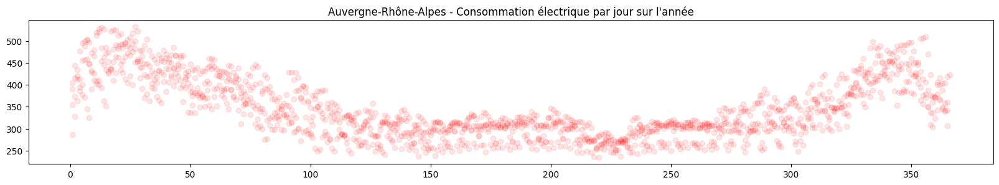

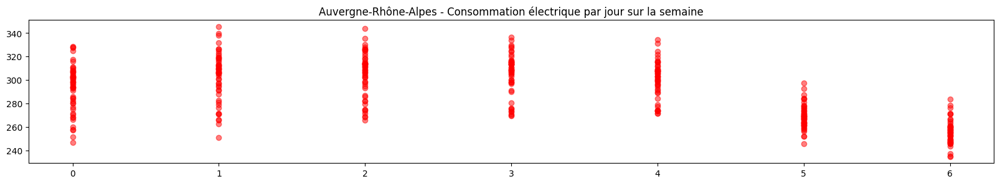

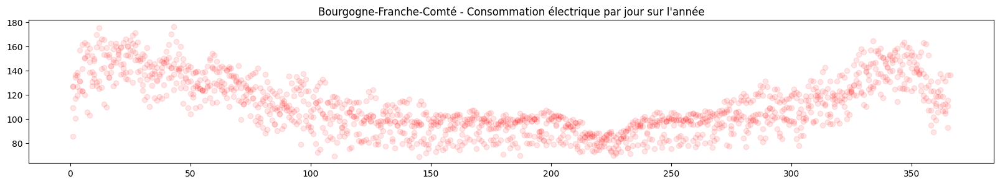

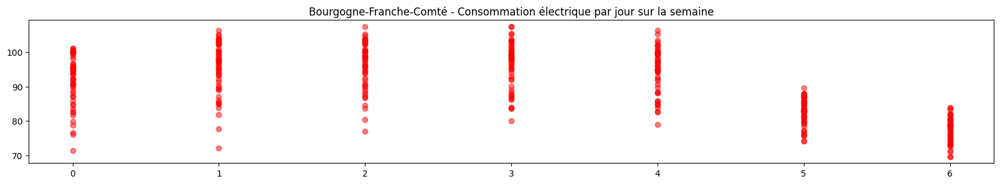

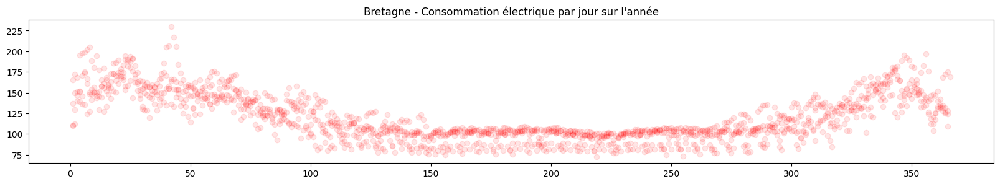

...

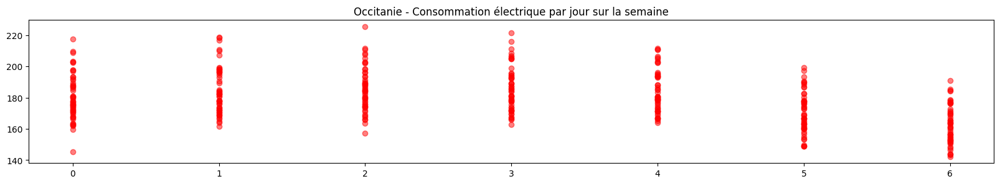

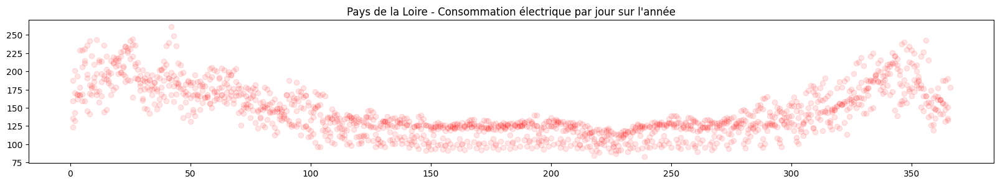

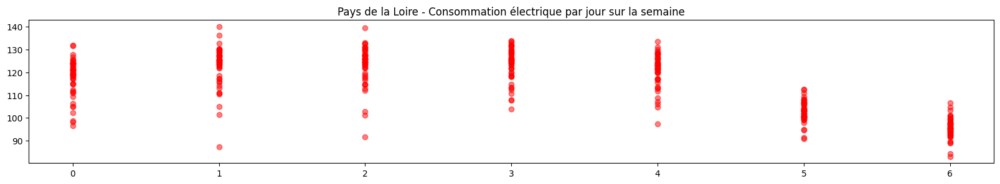

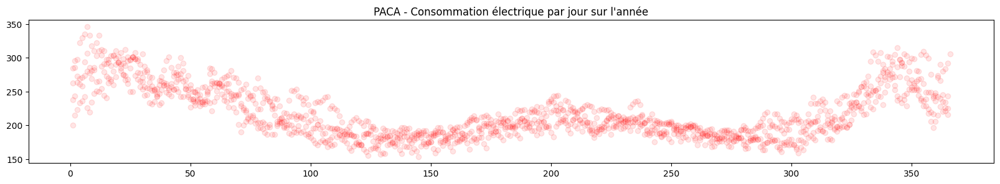

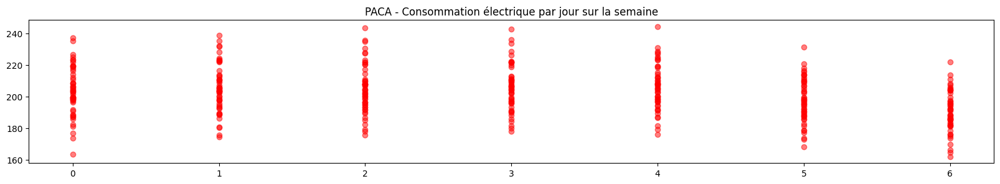

In [45]:


for region, deps in regions_departements.items():

    energyData = pd.read_csv(getFileNameEnr("cleaned", region=region), parse_dates=["Date"])
    energyData = energyData.sort_values("Date")
    energyData = energyData.groupby("Date")["Consommation"].sum().reset_index()

    energyDataSummer = energyData[(energyData['Date'].dt.month >= 6) & (energyData['Date'].dt.month <= 8)]
    
    plt.title(f"{region} - Consommation électrique par jour sur l'année")
    plt.scatter(energyData['Date'].dt.dayofyear,energyData["Consommation"],color="red",alpha=0.1)
    plt.show()

    plt.title(f"{region} - Consommation électrique par jour sur la semaine")
    plt.scatter(energyDataSummer['Date'].dt.dayofweek,energyDataSummer["Consommation"],color="red",alpha=0.5)
    plt.show()


In [ ]:
degree = 2
# featuresName = ['RR','TN', 'TX', 'TM', 'TNSOL', 'TN50', 'DG', 'FFM', 'DRR']
poly = PolynomialFeatures(degree)
linReg = LinearRegression()
linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])
# poly = PolynomialFeatures(degree)
# linReg = LinearRegression()

# linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])
for region,deps in regions_departements.items():
    combinedData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedData,"2023-01-01")

    linRegPipe.fit(Xtrain,yTrain)

    print(region," - score : ",linRegPipe.score(Xtest,yTest))
    # plt.plot(combinedData["Date"],linRegPipe.predict(X),label="Prediction")
    # plt.plot(combinedData["Date"],y,label="Truth")
    # plt.title(region)
    # plt.legend()
    # plt.show()

Auvergne-Rhône-Alpes  - score :  0.6952447245634965
Bourgogne-Franche-Comté  - score :  0.7301498848139221
Bretagne  - score :  0.8086883270592785
Centre-Val de Loire  - score :  0.8324572778542614
Grand Est  - score :  0.6195294698878261
Hauts-de-France  - score :  0.7094545105770562
Ile-de-France  - score :  0.7945814768314232
Nouvelle-Aquitaine  - score :  0.8005195828383622
Normandie  - score :  0.8054064414035744
Occitanie  - score :  0.8188918710886965
Pays de la Loire  - score :  0.7264467113132802
PACA  - score :  0.7835285316002709


Pour Auvergne-Rhône-Alpes
   param_poly__degree  mean_test_score
0                   1         0.511136
1                   2         0.655140
2                   3         0.240448
Best score : 0.6952
Pour Bourgogne-Franche-Comté
   param_poly__degree  mean_test_score
0                   1         0.592785
1                   2         0.616374
2                   3        -0.082627
Best score : 0.7301
Pour Bretagne
   param_poly__degree  mean_test_score
0                   1          0.53465
1                   2          0.65593
2                   3       -198.64783
Best score : 0.8087
Pour Centre-Val de Loire
   param_poly__degree  mean_test_score
0                   1         0.518268
1                   2         0.674712
2                   3        -2.562843
Best score : 0.8325
Pour Grand Est
   param_poly__degree  mean_test_score
0                   1         0.491115
1                   2         0.512250
2                   3        -0.759973
Best score : 0.6195
Pour Hauts-

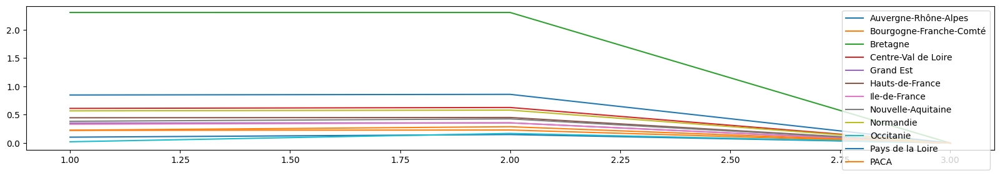

In [ ]:
maxSplits = 20
kmax = 3

param_grid = {"poly__degree": list(range(1, kmax + 1))}
poly = PolynomialFeatures(degree)
linReg = LinearRegression()
linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])

for region,deps in regions_departements.items():
    combinedData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedData,"2023-01-01")

    grid_search = GridSearchCV(estimator = linRegPipe, param_grid = param_grid, cv = 5, n_jobs=-1)

    grid_search.fit(Xtrain, yTrain)

    searchResults =  pd.DataFrame(grid_search.cv_results_)

    plt.plot(searchResults["param_poly__degree"],np.log10(searchResults["mean_test_score"]-searchResults["mean_test_score"].min()+1),label=region)
    print(f"Pour {region}")
    print(searchResults[["param_poly__degree","mean_test_score"]])
    print(f"Best score : {grid_search.best_estimator_.score(Xtest, yTest):.4f}")

plt.legend()
plt.show()



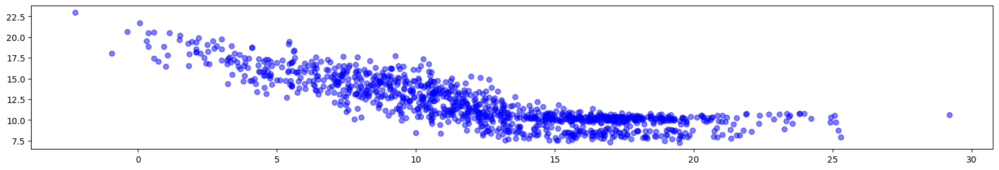

In [ ]:
plt.scatter(combinedData['TM'],combinedData["Consommation"],color="blue",alpha=0.5)
plt.show()

**Test en ajoutant les consommations des derniers jours**

In [ ]:
degree = 2
poly = PolynomialFeatures(degree)

linReg = LinearRegression()

linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])

for region,deps in regions_departements.items():
    combinedData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))

    combineLastDay = addLastCons(combinedData,5)
    # print(combineLastDay)
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-01-01")

    linRegPipe.fit(Xtrain,yTrain)

    print(region," - score : ",linRegPipe.score(Xtest,yTest))


Auvergne-Rhône-Alpes  - score :  0.9134514025080931
Bourgogne-Franche-Comté  - score :  0.9151799590887301
Bretagne  - score :  0.9248070550570586
Centre-Val de Loire  - score :  0.9278130534559896
Grand Est  - score :  0.9071914777963135
Hauts-de-France  - score :  0.8827896047281744
Ile-de-France  - score :  0.9473109051801323
Nouvelle-Aquitaine  - score :  0.9312396907046057
Normandie  - score :  0.9202231463914066
Occitanie  - score :  0.9461193188662341
Pays de la Loire  - score :  0.9125043031274807
PACA  - score :  0.9566559356903178


**En ajoutant les jours de la semaine et les jours de l'année**

score :  0.9731077311962832


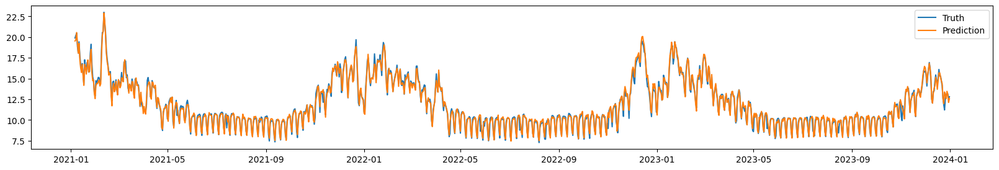

In [ ]:
X = combinedShiftedDay.drop(["Date","Consommation"],axis=1)
# features = combinedData[['TM']].to_numpy()
y = combinedShiftedDay[["Consommation"]].to_numpy()

sinCosTransformer = ColumnTransformer(
    transformers=[
        ("weekDay","drop",["weekDay"]),
        ("yearDay","drop",["yearDay"]),
        ("weekDaySin",sin_transformer(7),["weekDay"]),
        ("weekDayCos",cos_transformer(7),["weekDay"]),
        ("yearDayCos",cos_transformer(364),["yearDay"]),
        ("yearDaySin",cos_transformer(364),["yearDay"]),
    ],
    remainder='passthrough'
)

sincosLinRegPipe = Pipeline([
    ("transformer",sinCosTransformer),
    ('poly',poly),
    ("linReg",linReg)
])

sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])
tsCv_day = TimeSeriesSplit( #* To split intelignetly on time
    n_splits=3,
    gap=3,
    max_train_size=10000,
    test_size=150,
)


# X.iloc[train_0]
# X = poly.fit_transform(features)
Xtrain,Xtest, yTrain, yTest = train_test_split(X,y,test_size=0.2)
# Xtrain = X[trainInd]
# yTrain = y[trainInd]
# Xtest = X[testInd]
# yTest = y[testInd]

sincosLinRegPipe.fit(Xtrain,yTrain)
print("score : ",sincosLinRegPipe.score(Xtest,yTest))

plt.plot(combinedShiftedDay["Date"],y,label="Truth")
plt.plot(combinedShiftedDay["Date"],sincosLinRegPipe.predict(X),label="Prediction")
plt.legend()
plt.show()

Auvergne-Rhône-Alpes
 25 - score : 0.96916
Bourgogne-Franche-Comté
 25 - score : 0.95608
Bretagne
 25 - score : 0.95437
Centre-Val de Loire
 25 - score : 0.95818
Grand Est
 25 - score : 0.94730
Hauts-de-France
 25 - score : 0.95527
Île-de-France
 25 - score : 0.97358
Nouvelle-Aquitaine
 25 - score : 0.96513
Normandie
 25 - score : 0.96570
Occitanie
 25 - score : 0.97512
Pays de la Loire
 25 - score : 0.95734
PACA
 25 - score : 0.97699


In [91]:
scoreLastConsbyDay["mean"] = scoreLastConsbyDay.mean(axis=1)
scoreLastConsbyDay

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Île-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA,mean
0,0.882831,0.871638,0.936442,0.913872,0.830581,0.836027,0.905065,0.928875,0.916699,0.924314,0.931890,0.908802,0.898920
5,0.976554,0.968268,0.974294,0.970307,0.964076,0.969231,0.981331,0.979863,0.976708,0.984251,0.972681,0.984036,0.975133
10,0.977126,0.968702,0.974654,0.970374,0.963104,0.968920,0.982630,0.979548,0.977527,0.984663,0.972960,0.984285,0.975374
15,0.975250,0.966541,0.972084,0.967952,0.960046,0.967198,0.981153,0.976967,0.975015,0.983323,0.971541,0.982282,0.973279
20,0.973241,0.962788,0.966430,0.963913,0.956039,0.962779,0.978382,0.973457,0.971184,0.980109,0.966761,0.979693,0.969565
25,0.969165,0.956083,0.954368,0.958182,0.947303,0.955271,0.973581,0.965133,0.965696,0.975124,0.957344,0.976990,0.962853


In [ ]:
tsCv_day = TimeSeriesSplit(
    n_splits=5,
    gap=11, #* add least nb of last cons added
    max_train_size=10000,
    test_size=400,
)

sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])
scores = {}
collectedInformations = {}
for combinedData,(region,deps) in zip(combinedDatasRegDay,regions_departements.items()):

    print(region)
    for nbLstCons in range(5,15):
        combineLastDay = addLastCons(combinedData,nbLstCons)

        # combineWDays = addDays(combineLastDay)

        # print(combineLastDay)
        Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-01-01")

        scores = cross_val_score(sincosLinRegPipe,Xtrain,yTrain,cv=tsCv_day)
        # print(Xtrain, Xtest)
        # sincosLinRegPipe.fit(Xtrain,yTrain)
        
        score = scores.mean()
        print(f"\r {nbLstCons} - score : {score:.5f}",end='',flush=True)
        if nbLstCons not in collectedInformations:
            collectedInformations[nbLstCons] = []
        collectedInformations[nbLstCons].append(score)
    print()
scoreLastConsbyDay2 = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))

Auvergne-Rhône-Alpes
 14 - score : 0.97569
Bourgogne-Franche-Comté
 14 - score : 0.96659
Bretagne
 14 - score : 0.97327
Centre-Val de Loire
 14 - score : 0.96878
Grand Est
 14 - score : 0.95988
Hauts-de-France
 14 - score : 0.96738
Île-de-France
 14 - score : 0.98158
Nouvelle-Aquitaine
 14 - score : 0.97763
Normandie
 14 - score : 0.97564
Occitanie
 14 - score : 0.98372
Pays de la Loire
 14 - score : 0.97199
PACA
 14 - score : 0.98287


In [93]:
scoreLastConsbyDay2["mean"] = scoreLastConsbyDay2.mean(axis=1)
scoreLastConsbyDay2

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Île-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA,mean
5,0.976554,0.968268,0.974294,0.970307,0.964076,0.969231,0.981331,0.979863,0.976708,0.984251,0.972681,0.984036,0.975133
6,0.976417,0.968516,0.974301,0.970575,0.964714,0.969823,0.981650,0.980014,0.976781,0.984330,0.972958,0.983957,0.975336
7,0.976960,0.969510,0.974641,0.970746,0.965018,0.970190,0.982319,0.980209,0.977383,0.984576,0.973443,0.984305,0.975775
8,0.977568,0.969691,0.974572,0.970851,0.965543,0.970861,0.982812,0.980054,0.977860,0.984774,0.973523,0.984519,0.976052
9,0.977522,0.969383,0.974725,0.970738,0.964673,0.970031,0.982841,0.979915,0.977709,0.984844,0.973107,0.984735,0.975852
10,0.977126,0.968702,0.974654,0.970374,0.963104,0.968920,0.982630,0.979548,0.977527,0.984663,0.972960,0.984285,0.975374
11,0.977045,0.968547,0.974451,0.970212,0.962757,0.968834,0.982385,0.979161,0.977176,0.984583,0.972646,0.984367,0.975180
12,0.976844,0.968156,0.974174,0.969838,0.962489,0.968849,0.982099,0.978713,0.976483,0.984301,0.972650,0.984140,0.974895
13,0.976297,0.967264,0.973484,0.969672,0.961238,0.968202,0.982048,0.978143,0.975990,0.983973,0.972084,0.983469,0.974322
14,0.975694,0.966588,0.973268,0.968784,0.959880,0.967382,0.981579,0.977632,0.975637,0.983719,0.971986,0.982875,0.973752


In [94]:


# sincosLinRegPipe = Pipeline([
#     ("transformer",sinCosTransformer),
#     ('poly',poly),
#     ("linReg",linReg)
# ])
sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])
scores = {}
for region,deps in regions_departements.items():
    combinedData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))

    combineLastDay = addLastCons(combinedData,8)

    # combineWDays = addDays(combineLastDay)

    # print(combineLastDay)
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-01-01")
    # print(Xtrain, Xtest)
    sincosLinRegPipe.fit(Xtrain,yTrain)

    scores[region] = sincosLinRegPipe.score(Xtest, yTest)
    print(region, " - score : ", scores[region])
scorebyDay = pd.DataFrame.from_dict(scores,orient="index",columns=["Region - day"])
# createRegionMap(scores, title="Score R² par région — SinCos + LastConso")

Auvergne-Rhône-Alpes  - score :  0.9596835894196987
Bourgogne-Franche-Comté  - score :  0.9609344764455974
Bretagne  - score :  0.9773896969946931
Centre-Val de Loire  - score :  0.9597435317764692
Grand Est  - score :  0.9547935082295563
Hauts-de-France  - score :  0.9488977636380604
Île-de-France  - score :  0.9707604891201757
Nouvelle-Aquitaine  - score :  0.969283494092204
Normandie  - score :  0.9654146940321411
Occitanie  - score :  0.9792650974418332
Pays de la Loire  - score :  0.9636709005844667
PACA  - score :  0.973753904887626


In [95]:
# scorebyDay.loc['mean'] = scorebyDay.mean(axis=0)
scorebyDay

,Region - day
Auvergne-Rhône-Alpes,0.959684
Bourgogne-Franche-Comté,0.960934
Bretagne,0.977390
Centre-Val de Loire,0.959744
Grand Est,0.954794
Hauts-de-France,0.948898
Île-de-France,0.970760
Nouvelle-Aquitaine,0.969283
Normandie,0.965415
Occitanie,0.979265


**ETUDE PAR HEURE**

In [ ]:
fill_rates = []

for combinedData,(region,deps) in zip(combinedDatas,regions_departements.items()):
    # print(combinedData.columns)
    fill_rate = combinedData.notna().mean() * 100  
    fill_rates.append(fill_rate)

summary = pd.DataFrame(fill_rates).mean().round(2).sort_values()
summary.name = "Remplissage moyen (%)"

summary

In [ ]:
sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])

scores = {}
collectedInformations ={}
for combinedData,(region,deps) in zip(combinedDatasRegHor,regions_departements.items()):
    informationRatios = []
    print(region)

    # print(f"\r {lastCons} / 50",end='',flush=True)
    combinedDataCons = addLastCons(combinedData, 24)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedDataCons,"2022-01-01")
    # print(Xtrain.columns)
    # print(Xtrain.shape, Xtest.shape)
    sincosLinRegPipe.fit(Xtrain,yTrain)
    print(sincosLinRegPipe.score(Xtest,yTest),sincosLinRegPipe.score(Xtrain,yTrain))

Auvergne-Rhône-Alpes


**AJOUT des heures, jour de l'annnée, jour par semaines**

Auvergne-Rhône-Alpes
 45 / 50Bourgogne-Franche-Comté
 45 / 50Bretagne
 45 / 50Centre-Val de Loire
 45 / 50Grand Est
 45 / 50Hauts-de-France
 45 / 50Île-de-France
 45 / 50Nouvelle-Aquitaine
 45 / 50Normandie
 45 / 50Occitanie
 45 / 50Pays de la Loire
 45 / 50PACA
 45 / 50

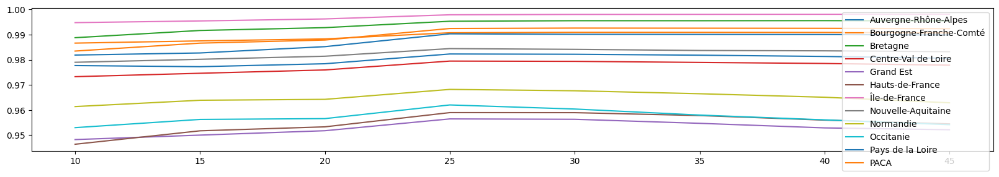

In [ ]:

sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=3)),
    ("linReg",  LinearRegression())
])

scores = {}
collectedInformations ={}
for combinedData,(region,deps) in zip(combinedDatasRegHor,regions_departements.items()):
    informationRatios = []
    print(region)
    
    for lastCons in range(10,50,5):
        print(f"\r {lastCons} / 50",end='',flush=True)
        combinedDataCons = addLastCons(combinedData, lastCons)

        Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedDataCons,"2023-01-01")
        # print(Xtrain.columns)
        # print(Xtrain.shape, Xtest.shape)
        sincosLinRegPipe.fit(Xtrain,yTrain)

        # scores[region] = sincosLinRegPipe.score(Xtest, yTest)

        # print(region, " - score : ", scores[region])

        score = sincosLinRegPipe.score(Xtest, yTest)
        informationRatios.append(score)
        if lastCons not in collectedInformations:
            collectedInformations[lastCons] = []
        collectedInformations[lastCons].append(score)
        
    plt.plot(list(range(10,50,5)),informationRatios,label=region)
    
varDf = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))
plt.legend()
plt.show()
# createRegionMap(scores, title="Score R² par région — SinCos + LastConso")

In [37]:
varDf["mean"] = varDf.mean(axis=1)
varDf.style.highlight_max(color = 'green', axis = 0)

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Île-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA,mean
10,0.977679,0.986607,0.988755,0.973266,0.948267,0.946417,0.994747,0.978985,0.961386,0.953009,0.981858,0.983447,0.972869
15,0.977234,0.987486,0.991631,0.974622,0.950042,0.951751,0.995420,0.980178,0.963894,0.956277,0.982694,0.986597,0.974819
20,0.978405,0.988275,0.992752,0.975937,0.951788,0.953330,0.996216,0.981395,0.964259,0.956598,0.985199,0.987826,0.975998
25,0.982284,0.990723,0.995293,0.979467,0.956480,0.958985,0.997860,0.984422,0.968208,0.962036,0.990295,0.992413,0.979872
30,0.982173,0.990890,0.995515,0.979356,0.956333,0.958965,0.998006,0.984120,0.967667,0.960407,0.990098,0.992576,0.979675
35,0.981806,0.990880,0.995505,0.978932,0.954729,0.957817,0.998032,0.983677,0.966488,0.958013,0.990051,0.992536,0.979039
40,0.981307,0.990838,0.995541,0.978511,0.952913,0.956004,0.998058,0.983535,0.965097,0.956109,0.990011,0.992487,0.978368
45,0.980590,0.990665,0.995447,0.977841,0.952181,0.954508,0.998068,0.983210,0.962885,0.954188,0.989833,0.992352,0.977647


Auvergne-Rhône-Alpes
 29 / 50Bourgogne-Franche-Comté
 29 / 50Bretagne
 29 / 50Centre-Val de Loire
 29 / 50Grand Est
 29 / 50Hauts-de-France
 29 / 50Île-de-France
 29 / 50Nouvelle-Aquitaine
 29 / 50Normandie
 29 / 50Occitanie
 29 / 50Pays de la Loire
 29 / 50PACA
 29 / 50

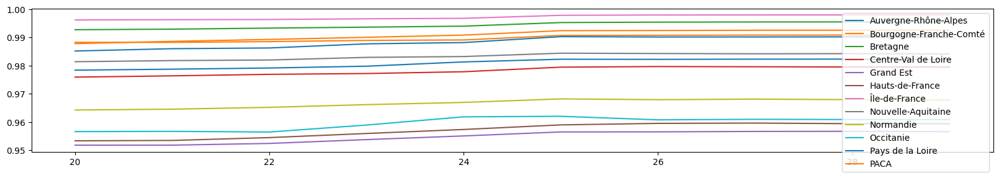

In [27]:
sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])

scores = {}
collectedInformations ={}
for combinedData,(region,deps) in zip(combinedDatas,regions_departements.items()):
    informationRatios = []
    print(region)
    
    for lastCons in range(20,30):
        print(f"\r {lastCons} / 50",end='',flush=True)
        combinedDataCons = addLastCons(combinedData, lastCons)

        Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedDataCons,"2023-01-01")
        # print(Xtrain.columns)
        # print(Xtrain.shape, Xtest.shape)
        sincosLinRegPipe.fit(Xtrain,yTrain)

        # scores[region] = sincosLinRegPipe.score(Xtest, yTest)

        # print(region, " - score : ", scores[region])

        score = sincosLinRegPipe.score(Xtest, yTest)
        informationRatios.append(score)
        if lastCons not in collectedInformations:
            collectedInformations[lastCons] = []
        collectedInformations[lastCons].append(score)
        
    plt.plot(list(range(20,30)),informationRatios,label=region)
    
varDf2 = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))
plt.legend()
plt.show()

In [36]:
varDf2["mean"] = varDf2.mean(axis=1)
varDf2.style.highlight_max(color = 'green', axis = 0)
# varDf2

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Île-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA,mean
20,0.978405,0.988275,0.992752,0.975937,0.951788,0.953330,0.996216,0.981395,0.964259,0.956598,0.985199,0.987826,0.975998
21,0.978748,0.988264,0.992952,0.976389,0.951795,0.953466,0.996309,0.981801,0.964558,0.956684,0.986019,0.988622,0.976300
22,0.979165,0.988533,0.993327,0.976920,0.952403,0.954475,0.996382,0.982008,0.965208,0.956451,0.986278,0.989308,0.976705
23,0.979806,0.988963,0.993663,0.977206,0.953761,0.955933,0.996630,0.982938,0.966171,0.958932,0.987743,0.990060,0.977650
24,0.981326,0.989122,0.994021,0.977845,0.955067,0.957357,0.996796,0.983238,0.966951,0.961836,0.988194,0.990845,0.978550
25,0.982284,0.990723,0.995293,0.979467,0.956480,0.958985,0.997860,0.984422,0.968208,0.962036,0.990295,0.992413,0.979872
26,0.982239,0.990775,0.995442,0.979684,0.956513,0.959518,0.997976,0.984309,0.967924,0.960769,0.990167,0.992475,0.979816
27,0.982310,0.990849,0.995502,0.979608,0.956657,0.959619,0.997998,0.984212,0.968123,0.960963,0.990179,0.992564,0.979882
28,0.982314,0.990855,0.995531,0.979528,0.956703,0.959416,0.998004,0.984265,0.967939,0.960884,0.990216,0.992569,0.979852
29,0.982183,0.990842,0.995519,0.979502,0.956587,0.959382,0.998004,0.984169,0.967760,0.960837,0.990094,0.992598,0.979790


In [ ]:
#* Grid Search 
sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])

scores = {}
for combinedData,(region,deps) in zip(combinedDatas,regions_departements.items()):

    combineLastDay = addLastCons(combinedData,27)

    # combineWDays = addDays(combineLastDay)

    # print(combineWDays.columns)
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-12-01")
    # print(Xtrain.columns)
    # print(Xtrain, Xtest)
    param_grid = {
        "days__use_hour":      [True, False],
        "days__use_weekDay":   [True, False],
        "days__use_yearDay":   [True, False],
        "poly__degree":        [1, 2, 3, 4],
    }

    # TimeSeriesSplit plutôt que KFold car tes données sont temporelles
    tscv = TimeSeriesSplit(n_splits=5)

    grid_search = GridSearchCV(sincosLinRegPipe, param_grid, cv=tscv, scoring='r2', n_jobs=-1)
    grid_search.fit(Xtrain, yTrain)

    print(f"{region} - {grid_search.best_params_}")
#TODO lancer pour le dej
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    



**PAR DEPARTEMENT**

In [ ]:
#* Combine Data
combinedDatasDep = []
for region,deps in regions_departements.items():


    energyData = getEnrData(region)
    dateMin = energyData["dateTime"].min()
    dateMax = energyData["dateTime"].max()
    # print(energyData)
    departementsData = []
    for dep in deps: 

        depDf = getMetData("Byhour",dep)
        depDf["dateTime"] = pd.to_datetime(depDf["DATE"].astype(str) + depDf["HOUR"].astype(str).str.zfill(2), format="%Y-%m-%d%H")
        depDf.drop(["NUM_POSTE","LAT","LON","FF2","DATE","HOUR"],axis=1,inplace=True)
        depDf = depDf[(depDf["dateTime"] >= dateMin) & (depDf["dateTime"] <= dateMax)]

        depAverage = depDf.groupby(["dateTime"]).mean() #* moyenne sur les heures
        depAverage.columns = [f"{col}_{dep}" for col in depAverage.columns]
        departementsData.append(depAverage)


    departementUnited = pd.concat(departementsData, axis=1, join="inner").reset_index(names=['dateTime'])
    # print(departementUnited.head(50))

    combinedData = combineEnrAndMetHour(energyData,departementUnited)
    
    print(region, combinedData.shape)
    combinedDatasDep.append(combinedData)

Auvergne-Rhône-Alpes (35064, 182)
Bourgogne-Franche-Comté (35064, 122)
Bretagne (35064, 62)
Centre-Val de Loire (35064, 92)
Grand Est (35064, 152)
Hauts-de-France (35064, 77)
Île-de-France (17774, 122)
Nouvelle-Aquitaine (35064, 182)
Normandie (35064, 77)
Occitanie (35064, 197)
Pays de la Loire (35064, 77)
PACA (35064, 92)


In [42]:
fill_rates = []

for combinedData,(region,deps) in zip(combinedDatasDep,regions_departements.items()):
    # print(combinedData.columns)
    fill_rate = combinedData.notna().mean() * 100  
    fill_rates.append(fill_rate)

summary = pd.DataFrame(fill_rates).mean().round(2).sort_values()
summary.name = "Remplissage moyen (%)"
# summary[summary<=50]
with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
    print(summary)

dateTime        100.0
Consommation    100.0
RR1_1           100.0
DRR1_1          100.0
FF_1            100.0
T_1             100.0
TD_1            100.0
TN_1            100.0
TX_1            100.0
DG_1            100.0
TNSOL_1         100.0
TN50_1          100.0
U_1             100.0
UN_1            100.0
UX_1            100.0
DHUMI40_1       100.0
DHUMI80_1       100.0
RR1_3           100.0
DRR1_3          100.0
FF_3            100.0
T_3             100.0
TD_3            100.0
TN_3            100.0
TX_3            100.0
DG_3            100.0
TNSOL_3         100.0
TN50_3          100.0
U_3             100.0
UN_3            100.0
UX_3            100.0
DHUMI40_3       100.0
DHUMI80_3       100.0
RR1_7           100.0
DRR1_7          100.0
FF_7            100.0
T_7             100.0
TD_7            100.0
TN_7            100.0
TX_7            100.0
DG_7            100.0
TNSOL_7         100.0
TN50_7          100.0
U_7             100.0
UN_7            100.0
UX_7            100.0
DHUMI40_7 

In [41]:
#* Fill mising data
combinedDatasDep2 = []
for combinedData,(region,deps) in zip(combinedDatasDep,regions_departements.items()):

    # On récupère les noms de colonnes de base (sans le suffixe département)
    base_cols = set(col.rsplit("_", 1)[0] for col in combinedData.columns if "_" in col)

    for base_col in base_cols:
        # On récupère toutes les colonnes correspondant à cette mesure
        matching_cols = [col for col in combinedData.columns if col.rsplit("_", 1)[0] == base_col]
        
        # Moyenne uniquement sur ces colonnes
        col_mean = combinedData[matching_cols].mean(axis=1)
        
        # On remplace les NaN uniquement pour ces colonnes
        combinedData[matching_cols] = combinedData[matching_cols].apply(lambda col: col.fillna(col_mean))
        
    combinedDatasDep2.append(combinedData)

combinedDatasDep = combinedDatasDep2.copy()


## PCA RESULTS

In [100]:
# import matplotlib.pyplot as plt
# import matplotlib.ticker as mticker
# import pandas as pd

def plotPCAInformationLoss(
    searchPCAResult: pd.DataFrame,
    thresholds: list = [0.05, 0.01],
    title: str = "Perte d'information PCA par région",
    savePath: str = None
):
    """
    Affiche la perte d'information (1 - variance expliquée) en fonction
    du nombre de composantes PCA, une courbe par région.

    Args:
        searchPCAResult : DataFrame avec en index les nb de composantes,
                          en colonnes les régions (output de searchPCARegDayResult)
        thresholds      : liste de seuils horizontaux à afficher
        title           : titre du graphique
        savePath        : si fourni, sauvegarde le graphique à ce chemin
    """
    COLORS = [
        "#378ADD", "#1D9E75", "#D85A30", "#D4537E",
        "#7F77DD", "#BA7517", "#639922", "#888780",
        "#E24B4A", "#5DCAA5", "#F0997B", "#AFA9EC"
    ]
    THRESHOLD_STYLES = [
        {"color": "#E24B4A", "linestyle": "--", "linewidth": 1.2},
        {"color": "#BA7517", "linestyle": ":",  "linewidth": 1.2},
        {"color": "#639922", "linestyle": "-.", "linewidth": 1.2},
    ]

    fig, ax = plt.subplots(figsize=(13, 6))

    regions = searchPCAResult.columns
    nComps  = searchPCAResult.index

    for i, region in enumerate(regions):
        color = COLORS[i % len(COLORS)]
        ax.plot(
            nComps,
            searchPCAResult[region],
            label=region,
            color=color,
            linewidth=2,
            marker="o",
            markersize=4,
        )

    for i, threshold in enumerate(thresholds):
        style = THRESHOLD_STYLES[i % len(THRESHOLD_STYLES)]
        ax.axhline(
            y=threshold,
            label=f"Seuil {threshold*100:.2f}%",
            alpha=0.85,
            **style
        )
        ax.text(
            nComps[-1] + 0.1,
            threshold,
            f"{threshold*100:.2f}%",
            va="center",
            fontsize=9,
            color=style["color"]
        )

    ax.set_xlabel("Number of PCA components", fontsize=11)
    ax.set_ylabel("Information loss (1 - explained variance)", fontsize=11)
    # ax.set_title(title, fontsize=13, pad=14)
    # ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))
    ax.set_xticks(nComps)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.5)
    ax.grid(axis="x", linestyle=":",  linewidth=0.4, alpha=0.3)
    ax.set_facecolor("#f9f9f9")
    ax.legend(
        loc="upper right",
        fontsize=9,
        framealpha=0.9,
        ncol=2
    )

    plt.tight_layout()

    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
        print(f"Graphique sauvegardé : {savePath}")

    plt.show()
    

#### Region Day

Auvergne-Rhône-Alpes (4013, 13)
Bourgogne-Franche-Comté (4013, 13)
Bretagne (4013, 13)
Centre-Val de Loire (4013, 13)
Grand Est (4013, 13)
Hauts-de-France (4013, 13)
Ile-de-France (4013, 13)
Nouvelle-Aquitaine (4013, 13)
Normandie (4013, 13)
Occitanie (4013, 13)
Pays de la Loire (4013, 13)
PACA (4013, 13)


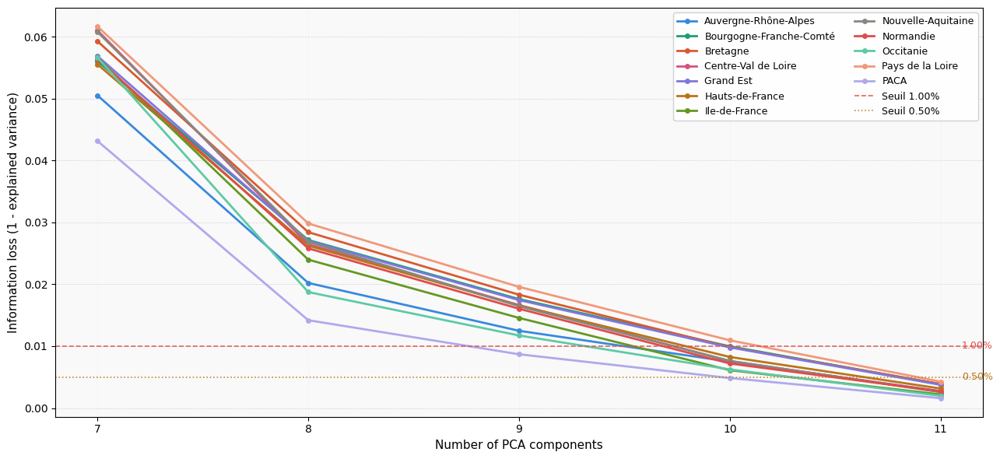

In [134]:
#* Trying PCA to reduce number of features

LinRegPipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler", StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("poly",    PolynomialFeatures(degree=2)),
        ("linReg",  LinearRegression())
])

preTransformPipe = LinRegPipe[:3]

collectedInformations = {}
for combinedData,(region,deps) in zip(combinedDatasRegDay,regions_departements.items()):

   
    combineLastDay = addLastCons(combinedData,3)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-12-31")
    # print(Xtrain.shape)
    # Xtrain.drop(['dateTime'],axis=1,inplace=True)
    # pca.fit(Xtrain)
    XtrainTransformed = preTransformPipe.fit_transform(Xtrain, yTrain)
    print(region,XtrainTransformed.shape)
    informationRatios = []
    for d in range(7,min(17,XtrainTransformed.shape[1]-1),1):
        pca = PCA(d)

        pca.fit(XtrainTransformed)
        totalVar = 1 - sum(pca.explained_variance_ratio_)
        # print(XPca )
        
        informationRatios.append(totalVar)
        if d not in collectedInformations:
            collectedInformations[d] = []
        collectedInformations[d].append(totalVar)

    # plt.plot(list(range(2,min(15,XtrainTransformed.shape[1]-1),1)),informationRatios,label=region)
searchPCARegDayResult = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))
plotPCAInformationLoss(searchPCARegDayResult,[0.01,0.005])
# plt.legend()
# plt.show()

In [97]:
searchPCARegDayResult

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Ile-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA
7,0.055117,0.066063,0.072425,0.071464,0.065960,0.066701,0.065854,0.068059,0.067026,0.064984,0.078605,0.051448
8,0.032787,0.041394,0.042922,0.040236,0.041700,0.037987,0.035090,0.042097,0.037364,0.034109,0.046579,0.026721
9,0.024886,0.032431,0.033021,0.029239,0.032098,0.029208,0.025065,0.029881,0.027824,0.022564,0.035776,0.017199
10,0.019301,0.024824,0.025790,0.022169,0.024707,0.023007,0.018850,0.022611,0.021005,0.017258,0.027769,0.013066
11,0.013871,0.018205,0.018812,0.016142,0.018270,0.017095,0.012901,0.016462,0.015060,0.012897,0.020663,0.009513
12,0.009809,0.012778,0.013169,0.011110,0.012897,0.011329,0.008743,0.011227,0.010350,0.008935,0.014561,0.006771
13,0.006271,0.007503,0.008066,0.007484,0.007600,0.007084,0.005879,0.007481,0.006905,0.005953,0.008832,0.004579
14,0.003353,0.004397,0.004724,0.003968,0.004404,0.003966,0.003094,0.003923,0.003722,0.003147,0.005163,0.002492
15,0.001888,0.002653,0.002930,0.002072,0.002612,0.002358,0.001710,0.002025,0.002114,0.001592,0.003136,0.001316
16,0.000931,0.001315,0.001528,0.001075,0.001281,0.001219,0.000936,0.001025,0.001111,0.000793,0.001578,0.000697


Graphique sauvegardé : graphics\pca\PCA_RegDay.pdf


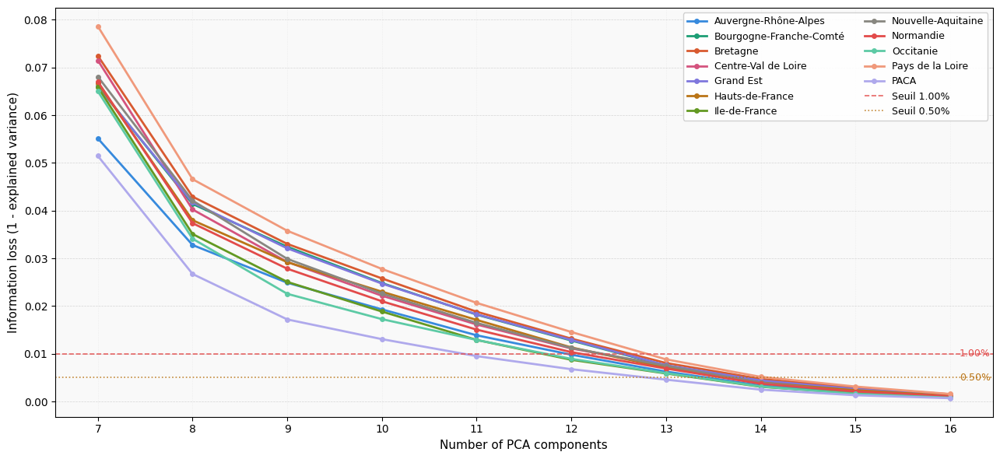

In [129]:
plotPCAInformationLoss(searchPCARegDayResult,[0.01,0.005],title="PCA information loss by region | Region - Day",savePath=os.path.join("graphics","pca","PCA_RegDay.pdf"))


In [36]:

searchPCARegDayResult

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Ile-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA
2,0.001754,0.000770,0.006955,0.001152,0.001170,0.001737,0.003160,0.003763,0.002122,0.003745,0.003365,0.004311
3,0.001197,0.000423,0.004263,0.000757,0.000795,0.001175,0.002197,0.002266,0.001448,0.002002,0.002350,0.002342
4,0.000828,0.000251,0.002574,0.000405,0.000551,0.000832,0.001579,0.001389,0.000790,0.001033,0.001438,0.000713
5,0.000544,0.000169,0.001955,0.000244,0.000378,0.000601,0.001053,0.000963,0.000572,0.000723,0.001066,0.000514
6,0.000273,0.000115,0.001393,0.000177,0.000218,0.000378,0.000651,0.000613,0.000410,0.000489,0.000715,0.000366
7,0.000203,0.000065,0.000853,0.000115,0.000146,0.000254,0.000483,0.000392,0.000262,0.000301,0.000424,0.000232
8,0.000136,0.000049,0.000569,0.000077,0.000106,0.000192,0.000339,0.000272,0.000169,0.000217,0.000325,0.000177
9,0.000083,0.000037,0.000414,0.000056,0.000068,0.000133,0.000209,0.000184,0.000121,0.000162,0.000230,0.000125
10,0.000045,0.000025,0.000270,0.000043,0.000045,0.000080,0.000124,0.000125,0.000084,0.000108,0.000143,0.000092
11,0.000033,0.000017,0.000177,0.000031,0.000026,0.000046,0.000083,0.000087,0.000058,0.000071,0.000087,0.000068


for nCOmp =4 : > 0.999

for nComp = 2 : > 0.99

#### Region Hour

Auvergne-Rhône-Alpes (35035, 26)
Bourgogne-Franche-Comté (35035, 26)
Bretagne (35035, 26)
Centre-Val de Loire (35035, 26)
Grand Est (35035, 26)
Hauts-de-France (35035, 26)
Ile-de-France (35035, 23)
Nouvelle-Aquitaine (35035, 26)
Normandie (35035, 26)
Occitanie (35035, 26)
Pays de la Loire (35035, 26)
PACA (35035, 26)


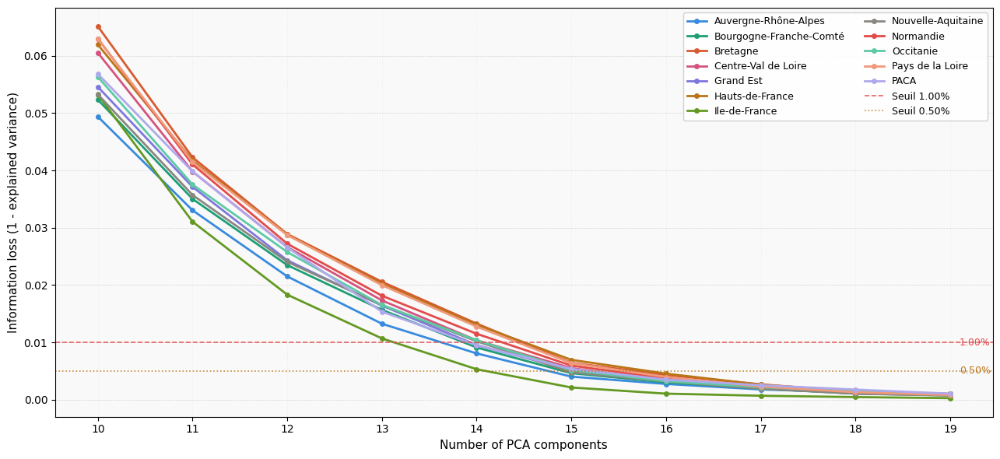

In [106]:
LinRegPipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler", StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("poly",    PolynomialFeatures(degree=2)),
        ("linReg",  LinearRegression())
])

preTransformPipe = LinRegPipe[:3]

collectedInformations = {}
for combinedData,(region,deps) in zip(combinedDatasRegHor,regions_departements.items()):

   
    combineLastDay = addLastCons(combinedData,5)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-12-31")
    # print(Xtrain.shape)
    # Xtrain.drop(['dateTime'],axis=1,inplace=True)
    # pca.fit(Xtrain)
    XtrainTransformed = preTransformPipe.fit_transform(Xtrain, yTrain)
    print(region,XtrainTransformed.shape)
    informationRatios = []
    for d in range(10,min(20,XtrainTransformed.shape[1]-1),1):
        pca = PCA(d)

        pca.fit(XtrainTransformed)
        totalVar = 1 - sum(pca.explained_variance_ratio_)
        # print(XPca )
        
        informationRatios.append(totalVar)
        if d not in collectedInformations:
            collectedInformations[d] = []
        collectedInformations[d].append(totalVar)

    # plt.plot(list(range(2,min(20,XtrainTransformed.shape[1]-1),1)),informationRatios,label=region)
searchPCARegHorResult = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))
plotPCAInformationLoss(searchPCARegHorResult,[0.01,0.005])
# plt.legend()
# plt.show()

Graphique sauvegardé : graphics\pca\PCA_RegHor.pdf


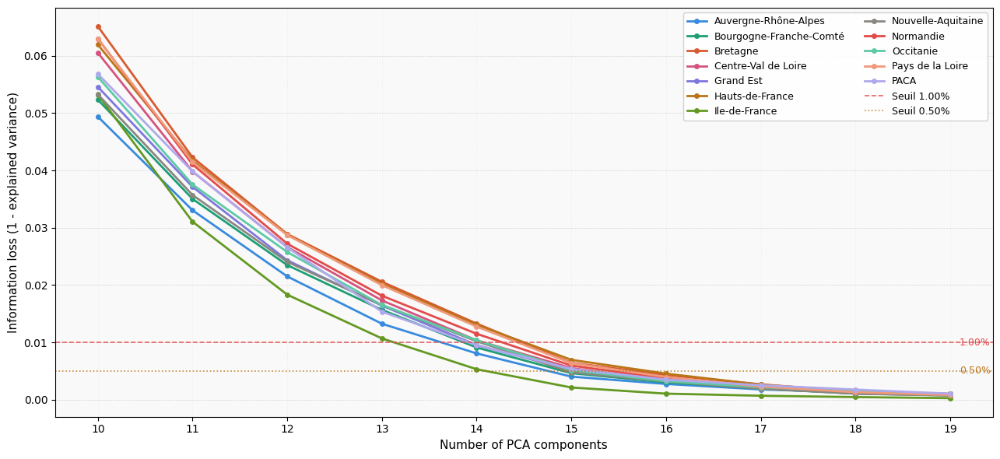

In [128]:

plotPCAInformationLoss(searchPCARegHorResult,[0.01,0.005],title="PCA information loss by region | Region - Hour",savePath=os.path.join("graphics","pca","PCA_RegHor.pdf"))

In [38]:
searchPCARegHorResult

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Ile-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA
2,0.119138,0.130928,0.123990,0.136671,0.132126,0.138143,0.158099,0.112709,0.132450,0.104893,0.129650,0.103922
3,0.070692,0.078141,0.053410,0.075828,0.077418,0.088075,0.093344,0.064707,0.075377,0.059896,0.077810,0.049143
4,0.036738,0.039037,0.025647,0.039477,0.040587,0.044582,0.041615,0.029614,0.040500,0.028839,0.034696,0.026101
5,0.009515,0.010644,0.014065,0.013618,0.010714,0.015295,0.017786,0.010914,0.014622,0.010051,0.014604,0.010859
6,0.006328,0.005807,0.008722,0.005814,0.005459,0.007594,0.007001,0.006471,0.008302,0.006597,0.006422,0.006910
7,0.004248,0.003457,0.006048,0.003588,0.003510,0.004981,0.004547,0.003778,0.005658,0.004711,0.004204,0.004791
8,0.002955,0.002374,0.003805,0.002430,0.002472,0.003151,0.003209,0.002674,0.003575,0.003341,0.002959,0.003015
9,0.002246,0.001685,0.002425,0.001501,0.001656,0.002060,0.002219,0.002045,0.002338,0.002507,0.001815,0.002225
10,0.001752,0.001189,0.001869,0.001130,0.001231,0.001573,0.001622,0.001564,0.001785,0.001863,0.001383,0.001711
11,0.001319,0.000943,0.001479,0.000900,0.000956,0.001238,0.001277,0.001232,0.001420,0.001468,0.001093,0.001389


#### Dep Day

In [120]:
#* Trying PCA to reduce number of features

LinRegPipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler", StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("poly",    PolynomialFeatures(degree=2)),
        ("linReg",  LinearRegression())
])

preTransformPipe = LinRegPipe[:3]

collectedInformations = {}
for combinedData,(region,deps) in zip(combinedDatasDepDay,regions_departements.items()):

   
    combineLastDay = addLastCons(combinedData,3)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-12-31")
    # print(Xtrain.shape)
    # Xtrain.drop(['dateTime'],axis=1,inplace=True)
    # pca.fit(Xtrain)
    XtrainTransformed = preTransformPipe.fit_transform(Xtrain, yTrain)
    print(region,XtrainTransformed.shape)
    informationRatios = []
    for d in range(15,50,2):
        if d > XtrainTransformed.shape[1]:
            collectedInformations[d].append(0)
            continue
        pca = PCA(d)

        pca.fit(XtrainTransformed)
        totalVar = 1 - sum(pca.explained_variance_ratio_)
        # print(XPca )
        
        informationRatios.append(totalVar)
        if d not in collectedInformations:
            collectedInformations[d] = []
        collectedInformations[d].append(totalVar)

searchPCADepDayResult = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))


Auvergne-Rhône-Alpes (4013, 79)
Bourgogne-Franche-Comté (4013, 55)
Bretagne (4013, 31)
Centre-Val de Loire (4013, 43)
Grand Est (4013, 67)
Hauts-de-France (4013, 37)
Ile-de-France (3990, 55)
Nouvelle-Aquitaine (4013, 79)
Normandie (4013, 37)
Occitanie (4013, 85)
Pays de la Loire (4013, 37)
PACA (4013, 43)


In [113]:
collectedInformations = 0

Graphique sauvegardé : graphics\pca\PCA_DepDay.pdf


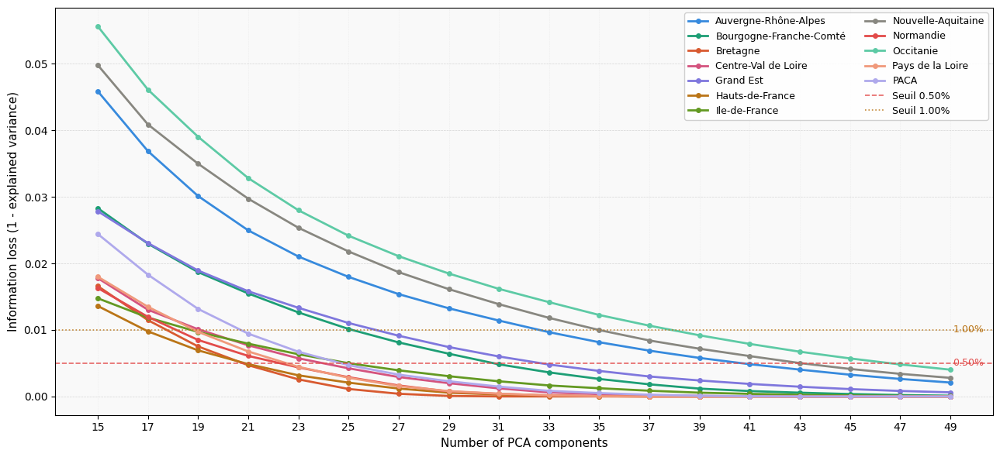

In [121]:
plotPCAInformationLoss(searchPCADepDayResult,[0.005,0.01],title="PCA information loss by region | Departement - Day",savePath=os.path.join("graphics","pca","PCA_DepDay.pdf"))

In [51]:
searchPCADepDayResult

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Ile-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA
5,0.014688,0.010896,0.004052,0.005720,0.008917,0.003251,0.011454,0.028959,0.004255,0.030418,0.006122,0.004247
7,0.008811,0.003804,0.001417,0.000743,0.004783,0.000581,0.004170,0.015848,0.000682,0.016934,0.000962,0.001372
9,0.004533,0.000544,0.000783,0.000247,0.002250,0.000265,0.001374,0.009361,0.000321,0.009625,0.000457,0.000437
11,0.002002,0.000173,0.000512,0.000143,0.000508,0.000171,0.000484,0.004199,0.000195,0.004980,0.000316,0.000256
13,0.000734,0.000106,0.000319,0.000095,0.000216,0.000097,0.000255,0.001622,0.000132,0.002352,0.000193,0.000151
15,0.000332,0.000074,0.000216,0.000072,0.000128,0.000071,0.000141,0.000749,0.000089,0.001015,0.000134,0.000110
17,0.000204,0.000056,0.000154,0.000053,0.000092,0.000049,0.000097,0.000427,0.000067,0.000657,0.000100,0.000082
19,0.000141,0.000044,0.000106,0.000038,0.000066,0.000036,0.000068,0.000321,0.000051,0.000410,0.000073,0.000059
21,0.000102,0.000033,0.000072,0.000027,0.000049,0.000025,0.000051,0.000258,0.000037,0.000297,0.000051,0.000041
23,0.000079,0.000026,0.000050,0.000020,0.000039,0.000017,0.000040,0.000208,0.000026,0.000222,0.000036,0.000030


for nComp = 11, all are abose 0.95
for nComp = 26, all are abose 0.999

#### DEP HOUR

In [125]:
LinRegPipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler", StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("poly",    PolynomialFeatures(degree=2)),
        ("linReg",  LinearRegression())
])

preTransformPipe = LinRegPipe[:3]

collectedInformations = {}
for combinedData,(region,deps) in zip(combinedDatasDepHor,regions_departements.items()):

   
    combineLastDay = addLastCons(combinedData,5)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-12-31")
    # print(Xtrain.shape)
    # Xtrain.drop(['dateTime'],axis=1,inplace=True)
    # pca.fit(Xtrain)
    XtrainTransformed = preTransformPipe.fit_transform(Xtrain, yTrain)
    print(region,XtrainTransformed.shape)
    informationRatios = []
    for d in range(20,85,2):
        if d > XtrainTransformed.shape[1]:
            collectedInformations[d].append(0)
            continue
        
        pca = PCA(d)

        pca.fit(XtrainTransformed)
        totalVar = 1 - sum(pca.explained_variance_ratio_)
        # print(XPca )
        
        informationRatios.append(totalVar)
        if d not in collectedInformations:
            collectedInformations[d] = []
        collectedInformations[d].append(totalVar)

searchPCADepHorResult = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))


Auvergne-Rhône-Alpes (35035, 155)
Bourgogne-Franche-Comté (35035, 107)
Bretagne (35035, 59)
Centre-Val de Loire (35035, 83)
Grand Est (35035, 131)
Hauts-de-France (35035, 71)
Ile-de-France (35035, 107)
Nouvelle-Aquitaine (35035, 155)
Normandie (35035, 71)
Occitanie (35035, 167)
Pays de la Loire (35035, 71)
PACA (35035, 83)


Graphique sauvegardé : graphics\pca\PCA_DepHor.pdf


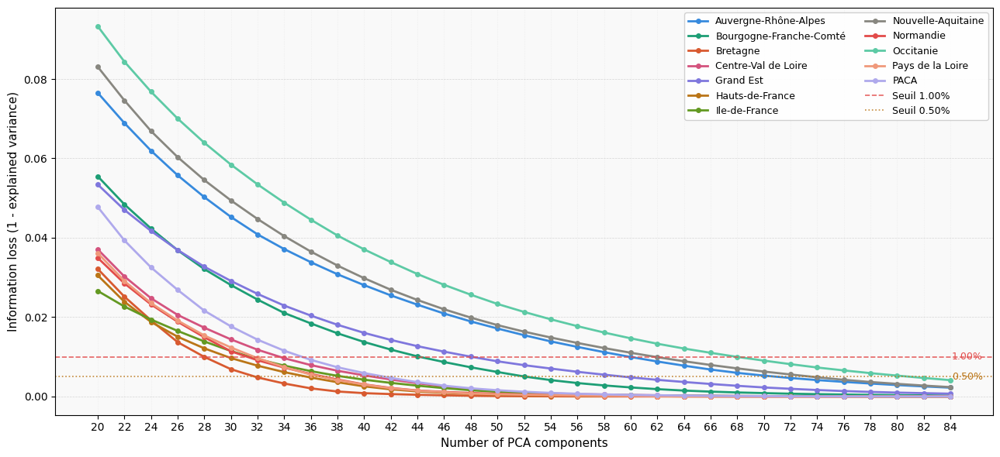

In [126]:
plotPCAInformationLoss(searchPCADepHorResult,[0.01,0.005],title="PCA information loss by region | Departement - Hour",savePath=os.path.join("graphics","pca","PCA_DepHor.pdf"))

In [97]:
searchPCADepHorResult

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Ile-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA
20,0.024254,0.013601,2.310365e-03,0.006668,1.558528e-02,3.882786e-03,0.003840,2.326520e-02,4.275419e-03,2.876606e-02,4.529666e-03,0.007299
22,0.020643,0.011302,1.824415e-03,0.005005,1.328558e-02,2.786366e-03,0.002886,1.998033e-02,3.249433e-03,2.439912e-02,3.206159e-03,0.005663
24,0.017826,0.009396,1.442780e-03,0.003599,1.129142e-02,2.029681e-03,0.002148,1.724854e-02,2.504820e-03,2.099501e-02,2.194495e-03,0.004357
26,0.015461,0.007835,1.165267e-03,0.002660,9.617962e-03,1.540300e-03,0.001625,1.487432e-02,1.909703e-03,1.831585e-02,1.593394e-03,0.003355
28,0.013550,0.006460,9.393377e-04,0.001904,8.108563e-03,1.232757e-03,0.001268,1.306927e-02,1.538321e-03,1.622009e-02,1.308719e-03,0.002457
30,0.011998,0.005308,7.336526e-04,0.001463,6.918231e-03,1.012582e-03,0.001054,1.151192e-02,1.268005e-03,1.434381e-02,1.080542e-03,0.001876
32,0.010618,0.004290,5.440666e-04,0.001158,5.865120e-03,8.384046e-04,0.000891,1.010256e-02,1.037220e-03,1.272797e-02,8.800031e-04,0.001537
34,0.009331,0.003416,3.731586e-04,0.000974,4.936330e-03,6.931351e-04,0.000752,8.912522e-03,8.388993e-04,1.130630e-02,7.174206e-04,0.001256
36,0.008191,0.002676,2.621402e-04,0.000815,4.199269e-03,5.686939e-04,0.000639,7.826745e-03,6.857118e-04,1.004578e-02,5.749195e-04,0.001011
38,0.007155,0.002081,1.783287e-04,0.000670,3.573104e-03,4.559608e-04,0.000544,6.868289e-03,5.439482e-04,8.937937e-03,4.610673e-04,0.000805



for nComp 22, All departement have more than 95%

for n COmp 46, all dep are over 99%

#### Summary PCA

In [135]:
def getNComp(region:str,pcaResult:pd.DataFrame,threshold:float):
    pos =  pcaResult[pcaResult[region]<=threshold].index
    
    return pos[0] if len(pos)>0 else -1
pcaParams = {}
for scale in ["Region","Dep"]:
    for delta in ["ByDay","ByHour"]:
        pcaParams[f"{scale}_{delta}"] = {}
        if scale=="Region" and delta=="ByDay":
            pcaResult = searchPCARegDayResult
        if scale=="Region" and delta=="ByHour":
            pcaResult = searchPCARegHorResult
        if scale=="Dep" and delta=="ByDay":
            pcaResult = searchPCADepDayResult
        if scale=="Dep" and delta=="ByHour":
            pcaResult = searchPCADepHorResult
        for threshold in [0.01,0.005]:
            pcaParams[f"{scale}_{delta}"][threshold] = {}
            for region in regions_departements.keys():
                nComp = int(getNComp(region,pcaResult,threshold))
                if nComp==-1:
                    print(f"not found for {scale}_{delta} {region} {threshold}")
                pcaParams[f"{scale}_{delta}"][threshold][region] = nComp
                
            
                
with open("modelParams/pcaParams.json", "w", encoding="utf-8") as f:
        json.dump(pcaParams, f, indent=2, ensure_ascii=False)

In [42]:
import json
import pandas as pd
import numpy as np


def loadPcaComponentsDataFrame(filepath: str = "pcaComponents.json") -> pd.DataFrame:
    """
    Load PCA components from JSON and convert to a structured DataFrame.
    
    Args:
        filepath: Path to the JSON file containing PCA components
        
    Returns:
        pd.DataFrame: DataFrame with MultiIndex (Region, Precision) as rows
                     and dataset names (Region_ByDay, Region_ByHour, Dep_ByDay, Dep_ByHour) as columns
    """
    
    # Load JSON
    with open(filepath, "r", encoding="utf-8") as f:
        pcaConfig = json.load(f)
    
    # Collect all data
    allData = []
    allDatasets = set()
    allRegions = set()
    allPrecisions = set()
    
    # Parse the JSON structure
    for dataset, precisions_dict in pcaConfig.items():
        allDatasets.add(dataset)
        
        for precision, regions_dict in precisions_dict.items():
            allPrecisions.add(precision)
            
            for region, nComp in regions_dict.items():
                allRegions.add(region)
                allData.append({
                    "dataset": dataset,
                    "precision": precision,
                    "region": region,
                    "nComp": nComp
                })
    
    # Add precision "0" (no PCA) - filled with placeholder values
    # The user will fill these manually
    for dataset in allDatasets:
        for region in allRegions:
            if dataset == "Region_ByDay":
                nComp = 14
            elif dataset == "Region_ByHour":
                nComp = 26
            else:
                nComp = 525
            allData.append({
                "dataset": dataset,
                "precision": "0",
                "region": region,
                "nComp":  nComp # Placeholder for user to fill
            })
    
    # Create DataFrame
    df = pd.DataFrame(allData)
    
    # Pivot to get the desired structure
    # MultiIndex rows: (Region, Precision)
    # Columns: datasets
    df_pivot = df.pivot_table(
        index=["region", "precision"],
        columns="dataset",
        values="nComp",
        aggfunc="first"
    )
    
    # Rename index levels to be more explicit
    df_pivot.index.names = ["Region", "Precision"]
    
    # Sort by region then precision
    df_pivot = df_pivot.sort_index(level=["Region", "Precision"])
    
    # Reorder columns for consistency
    column_order = ["Region_ByDay", "Region_ByHour", "Dep_ByDay", "Dep_ByHour"]
    existing_cols = [col for col in column_order if col in df_pivot.columns]
    df_pivot = df_pivot[existing_cols]
    
    return df_pivot


def displayPcaComponentsSummary(filepath: str = "pcaComponents.json") -> None:
    """
    Load and display PCA components summary with formatting.
    
    Args:
        filepath: Path to the JSON file containing PCA components
        
    Returns:
        None - displays the styled DataFrame
    """
    
    df = loadPcaComponentsDataFrame(filepath)
    
    # Create a custom formatter to handle NaN values
    def format_ncomp(val):
        if pd.isna(val):
            return "TO FILL"
        return f"{int(val)}"
    
    print("\n" + "="*80)
    print("PCA Components Summary")
    print("="*80 + "\n")
    
    # Display with formatting
    formatted_df = df.copy()
    for col in formatted_df.columns:
        formatted_df[col] = formatted_df[col].apply(lambda x: format_ncomp(x))
    
    print(formatted_df.to_string())
    print("\n" + "="*80)
    print("Note: 'TO FILL' indicates precision '0' (no PCA) - fill manually")
    print("="*80 + "\n")
    
    return df.style \
        .format(lambda x: f"{int(x)}" if not pd.isna(x) else "TO FILL") \
        .highlight_null(null_color="lightyellow") \
        .set_caption("PCA Components by Region and Precision")


def updatePcaComponentValue(filepath: str,
                            region: str,
                            precision: str,
                            dataset: str,
                            nComp: int) -> None:
    """
    Update a specific PCA component value in the JSON file.
    Useful for filling in the precision "0" values manually.
    
    Args:
        filepath: Path to the JSON file
        region: Region name
        precision: Precision level (e.g., "0", "0.01", "0.005")
        dataset: Dataset name (e.g., "Region_ByDay")
        nComp: Number of components
        
    Returns:
        None - updates the JSON file
    """
    
    with open(filepath, "r", encoding="utf-8") as f:
        pcaConfig = json.load(f)
    
    # Navigate and update the value
    if dataset in pcaConfig:
        if precision in pcaConfig[dataset]:
            if region in pcaConfig[dataset][precision]:
                pcaConfig[dataset][precision][region] = nComp
                
                # Save back to file
                with open(filepath, "w", encoding="utf-8") as f:
                    json.dump(pcaConfig, f, indent=2, ensure_ascii=False)
                
                print(f"Updated: {dataset} - {precision} - {region} = {nComp}")
            else:
                print(f"Region '{region}' not found in {dataset}/{precision}")
        else:
            print(f"Precision '{precision}' not found in {dataset}")
    else:
        print(f"Dataset '{dataset}' not found")



In [48]:
print(loadPcaComponentsDataFrame("modelParams/pcaParams.json").to_latex())

\begin{tabular}{llrrrr}
\toprule
 & dataset & Region_ByDay & Region_ByHour & Dep_ByDay & Dep_ByHour \\
Region & Precision &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{Auvergne-Rhône-Alpes} & 0 & 14 & 26 & 525 & 525 \\
 & 0.005 & 11 & 15 & 41 & 72 \\
 & 0.01 & 10 & 14 & 33 & 60 \\
\cline{1-6}
\multirow[t]{3}{*}{Bourgogne-Franche-Comté} & 0 & 14 & 26 & 525 & 525 \\
 & 0.005 & 11 & 15 & 31 & 54 \\
 & 0.01 & 10 & 14 & 27 & 46 \\
\cline{1-6}
\multirow[t]{3}{*}{Bretagne} & 0 & 14 & 26 & 525 & 525 \\
 & 0.005 & 11 & 16 & 21 & 32 \\
 & 0.01 & 10 & 15 & 19 & 28 \\
\cline{1-6}
\multirow[t]{3}{*}{Centre-Val de Loire} & 0 & 14 & 26 & 525 & 525 \\
 & 0.005 & 11 & 16 & 25 & 42 \\
 & 0.01 & 10 & 15 & 21 & 34 \\
\cline{1-6}
\multirow[t]{3}{*}{Grand Est} & 0 & 14 & 26 & 525 & 525 \\
 & 0.005 & 11 & 16 & 33 & 60 \\
 & 0.01 & 10 & 14 & 27 & 50 \\
\cline{1-6}
\multirow[t]{3}{*}{Hauts-de-France} & 0 & 14 & 26 & 525 & 525 \\
 & 0.005 & 11 & 16 & 21 & 36 \\
 & 0.01 & 10 & 15 & 17 & 30 \\
\cline{1-6}
\multirow[

## SUMMARY OF METHOD PERFORMANCE

In [40]:
def getModelBestScores(modelName: Literal["polyReg", "ridgeReg", "decTree", "AdaBoostDecTree"], 
                       level: int, 
                       verbose: bool = False) -> pd.DataFrame:

    statistics = ["testScore", "trainScore", "fitTime", "testTime"]
    
    modelBestScores = pd.DataFrame(
        index=pd.MultiIndex.from_product(
            [["Region", "Dep"], ["ByDay", "ByHour"]], 
            names=["Scale", "Delta"]
        ),
        columns=pd.MultiIndex.from_product(
            [sorted(regions_departements.keys()), statistics],
            names=["Region", "Statistic"]
        )
    )
    for scale in ["Region", "Dep"]:
        for delta in ["ByDay", "ByHour"]:
            try:
                gridResults = loadGridSearchResults(getGridSearchResultsName(delta, scale, modelName, level,fill=False))
                bestResults = getBestParams(gridResults)
                for region, entries in bestResults.items():
                    for stat in statistics:
                        modelBestScores.loc[(scale, delta), (region, stat)] = entries.get(stat, np.nan)
                        
            except Exception as e:
                if verbose:
                    print(f"Problème avec {scale} - {delta} - {modelName} - {level}: {str(e)}")
                    pass
    
    return modelBestScores

def getModelsSummary(verbose:bool=False,filters:dict=None,dropIndex:list=None,onlyMean:bool=False,pretty:bool=True):
    modelsName = sorted(["polyReg","ridgeReg","decTree","AdaBoostDecTree"])
    statistics = sorted(["testScore", "trainScore", "fitTime", "testTime"])
    modelsSummary = pd.DataFrame(index=pd.MultiIndex.from_product([modelsName,[1,2,3],["Region","Dep"],["ByDay","ByHour"]],
                                 names=["Model","Level","Scale","Delta"]),
                                 columns=pd.MultiIndex.from_product([sorted(regions_departements.keys()), statistics],
                                 names=["Region", "Statistic"]
        )).sort_index()
    
    for modelName in modelsName:
        for level in [1,2,3]:
            modelBestScore = getModelBestScores(modelName, level, verbose)
            for (scale, delta) in modelBestScore.index:
                for region in sorted(regions_departements.keys()):
                    for stat in statistics:
                        modelsSummary.loc[(modelName, level, scale, delta), (region, stat)] = \
                            modelBestScore.loc[(scale, delta), (region, stat)]
                        modelsSummary.sort_index(inplace=True)
    
    # Trier l'index et les colonnes après remplissage
    modelsSummary = modelsSummary
    # print(modelsSummary.index)
    if filters is not None:
        for paramName, acceptedValues in filters.items():
            if paramName in modelsSummary.index.names:
                # Filtrer sur l'index MultiIndex
                idx = modelsSummary.index
                mask = idx.get_level_values(paramName).isin(acceptedValues)
                modelsSummary = modelsSummary[mask]
    if dropIndex is not None:
        modelsSummary = modelsSummary.droplevel(dropIndex)
    for stat in statistics:
        regionCols = [(region, stat) for region in sorted(regions_departements.keys())]
        modelsSummary[("Moyenne", stat)] = modelsSummary[regionCols].mean(axis=1)
    if onlyMean:
        modelsSummary = modelsSummary[["Moyenne"]]

    if pretty:
        modelsSummary = modelsSummary.style \
                    .highlight_max(color="green", axis=0, subset=pd.IndexSlice[:, pd.IndexSlice[:, ["testScore"]]]) \
                    .highlight_max(color="cyan", axis=0, subset=pd.IndexSlice[:, pd.IndexSlice[:, ["trainScore"]]]) \
                    .highlight_min(color="orange", axis=0, subset=pd.IndexSlice[:, pd.IndexSlice[:, ["fitTime"]]]) \
                    .highlight_min(color="magenta", axis=0, subset=pd.IndexSlice[:, pd.IndexSlice[:, ["testTime"]]]) \
                    .format("{:.4f}")
    return modelsSummary

getModelsSummary(True,filters={},dropIndex=[],pretty=True,onlyMean=True)

Problème avec Region - ByDay - AdaBoostDecTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByDay_AdaBoostDecTree_results_3.json'
Problème avec Region - ByHour - AdaBoostDecTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByHour_AdaBoostDecTree_results_3.json'
Problème avec Region - ByDay - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByDay_decTree_results_3.json'
Problème avec Region - ByHour - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByHour_decTree_results_3.json'
Problème avec Dep - ByDay - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Dep_ByDay_decTree_results_3.json'
Problème avec Dep - ByHour - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Dep_ByHour_decTree_results_3.json'
Problème avec Region - ByDay - polyReg - 3: [Errno 2] No such file or directory: 'grid

In [168]:
to_tabularx(getModelsSummary(True,filters={"Delta":['ByDay']},dropIndex=["Level"],onlyMean=True))

\begin{tabularx}{\textwidth}{lllllll}
\toprule
 &  & Region & \multicolumn{4}{r}{Moyenne} \\
 &  & Statistic & testScore & trainScore & fitTime & testTime \\
Model & Scale & Delta &  &  &  &  \\
\midrule
\multirow[c]{2}{*}{AdaBoostDecTree} & Dep & ByDay & 0.9732 & 0.9993 & 35.2996 & 0.0796 \\
 & Region & ByDay & 0.9738 & {\cellcolor{cyan}} 0.9993 & 8.2458 & 0.0565 \\
\multirow[c]{2}{*}{decTree} & Dep & ByDay & 0.9378 & 0.9972 & 0.2509 & 0.0151 \\
 & Region & ByDay & 0.9393 & 0.9949 & {\cellcolor{orange}} 0.0783 & 0.0166 \\
\multirow[c]{2}{*}{polyReg} & Dep & ByDay & 0.9568 & 0.9666 & 0.2734 & 0.0197 \\
 & Region & ByDay & 0.9755 & 0.9808 & 0.0877 & {\cellcolor{magenta}} 0.0129 \\
\multirow[c]{2}{*}{ridgeReg} & Dep & ByDay & 0.9713 & 0.9808 & 0.7475 & 0.0306 \\
 & Region & ByDay & {\cellcolor{green}} 0.9764 & 0.9825 & 0.3192 & 0.0237 \\
\bottomrule
\end{tabularx}



In [196]:
def evaluateBestEstimator(delta,model,predict:bool,onlyRegion:str=None):
    summary = getModelsSummary(True,filters={"Model":[model],"Delta":[delta]},dropIndex=["Model","Delta"],pretty=False)
    print(summary)
    regionDatas = getCombinedDatas(delta,"Region",fill=False)
    depDatas = getCombinedDatas(delta,"Dep",fill=False)
    pipeline = getPipeline(model)
    results = {}
    bestParamss = {}
    yTrues = {}
    for i,region in enumerate(regions_departements.keys()):
        if onlyRegion and onlyRegion != region:
            continue
        print(f"Evaluating for {region} {model} {delta}")
        
        scale = "Region"
        # level = summary[region].idxmax(axis=0)["testScore"]
        # level, scale = summary[region].idxmax(axis=0)["testScore"]
        # try:
        #     stats = getBestParams(loadGridSearchResults(getGridSearchResultsName(delta,scale,model,level,fill=False)),region)
        #     bestParams = stats["params"]
        #     bestParamss[region] = bestParams
        # except:
        #     print("Probleme avec ",delta,scale,model,level)

        
        defaultConfigPath = os.path.join("modelParams",f"defaultParams_{delta}_{scale}_{model}.json")
        with open(defaultConfigPath, "r", encoding="utf-8") as f:
            bestParamss = json.load(f)
            print(f"  Loaded default parameters from: {defaultConfigPath}")
        
        bestParams = bestParamss[region]
        print(f"best scale : {scale} \nbest params : {bestParams}")
        nbLstCons = bestParams.get("nbLstCons",3 if delta=="ByDay" else 5)
        if "nbLstCons" in bestParams:
            del bestParams["nbLstCons"]

        combinedData = regionDatas[i] if scale == "Region" else depDatas[i]

        combinedData = addLastCons(combinedData,nbLstCons)

        bestParams = buildDynamicParamGrid(
            region, delta, scale, bestParams, bestParams.get("pca__precision",0)
        )
        # print(bestParams)
        pipeline.set_params(**bestParams)



        Xtrain, yTrain, Xtest, yTest = getTestTrain(combinedData,"2024-01-01")
        print(Xtrain.shape,yTrain.shape,Xtest.shape,yTest.shape)
        pipeline.fit(Xtrain,yTrain)
        
        if predict:
            results[region] = pipeline.predict(Xtest)
            yTrues[region] = yTest
        else:
            testScore = pipeline.score(Xtest,yTest)
            trainScore = pipeline.score(Xtrain,yTrain)
            print(f"scores - test {testScore}  train : {trainScore} ")

            results[region] = (testScore,trainScore)

    # return bestParamss
    if predict : return (results,yTrues)
    return pd.DataFrame.from_dict(results,orient="index",columns=["Test Score", "Train Score"])


def plotBestScoresByRegion(scoresDataFrame: pd.DataFrame,
                           figsize: tuple = (12, 8),
                           savePath: str = None,
                           xMin: float = 0.8,
                           xMax: float = 1.0) -> None:
    """
    Plot best scores by region with horizontal bars for test and train scores.
    
    Args:
        scoresDataFrame: DataFrame with regions as index and 'testScore' and 'trainScore' as columns
        figsize: Figure size as (width, height) tuple (default: (12, 8))
        savePath: Path to save the figure (optional)
        
    Returns:
        None - displays the plot
    """
    
    # Sort by test score for better visualization
    dfSorted = scoresDataFrame.sort_values("Test Score", ascending=True)
    
    fig, ax = plt.subplots(figsize=figsize)
    
    y_pos = np.arange(len(dfSorted))
    bar_height = 0.35
    
    # Plot test scores
    ax.barh(y_pos - bar_height / 2, dfSorted["Test Score"], bar_height, 
            label="Test Score", color="steelblue", alpha=0.85)
    
    # Plot train scores
    ax.barh(y_pos + bar_height / 2, dfSorted["Train Score"], bar_height, 
            label="Train Score", color="coral", alpha=0.85)
    
    # Customize plot
    ax.set_yticks(y_pos)
    ax.set_yticklabels(dfSorted.index, fontsize=11)
    ax.set_xlabel("Score", fontsize=12)
    ax.set_title("Best Scores by Region", fontsize=13, fontweight="bold")
    ax.legend(loc="lower right", fontsize=11)
    ax.grid(axis="x", alpha=0.3)
    ax.set_xlim(xMin, xMax)
    
    plt.tight_layout()
    
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
    
    plt.show()
        

In [ ]:
# for delta in ["ByDay","ByHour"]:
#     for scale in ["Region","Dep"]:
#         for model in ["AdaBoostDecTree"]:
#             parms = evaluateBestEstimator(delta,scale,model,predict=False)
#             with open(f"modelParams/defaultParms_{delta}_{scale}_{model}.json", "w", encoding="utf-8") as f:
#                 json.dump(parms, f, indent=2, ensure_ascii=False)

In [60]:
results = evaluateBestEstimator("ByDay","polyReg",predict=False)
results

Problème avec Region - ByDay - AdaBoostDecTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByDay_AdaBoostDecTree_results_3.json'
Problème avec Region - ByHour - AdaBoostDecTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByHour_AdaBoostDecTree_results_3.json'
Problème avec Region - ByDay - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByDay_decTree_results_3.json'
Problème avec Region - ByHour - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByHour_decTree_results_3.json'
Problème avec Dep - ByDay - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Dep_ByDay_decTree_results_3.json'
Problème avec Dep - ByHour - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Dep_ByHour_decTree_results_3.json'
Problème avec Region - ByDay - polyReg - 3: [Errno 2] No such file or directory: 'grid

,Test Score,Train Score
Auvergne-Rhône-Alpes,0.961545,0.978420
Bourgogne-Franche-Comté,0.958434,0.971161
Bretagne,0.975595,0.978444
Centre-Val de Loire,0.956542,0.977041
Grand Est,0.945901,0.968549
Hauts-de-France,0.938951,0.974102
Ile-de-France,0.954479,0.989331
Nouvelle-Aquitaine,0.973676,0.981765
Normandie,0.970708,0.980534
Occitanie,0.977140,0.985506


In [200]:
predictions,yTrues = evaluateBestEstimator("ByDay","adaBoostDecTree",predict=True,onlyRegion="Hauts-de-France")

Problème avec Region - ByDay - AdaBoostDecTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByDay_AdaBoostDecTree_results_3.json'
Problème avec Region - ByHour - AdaBoostDecTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByHour_AdaBoostDecTree_results_3.json'
Problème avec Region - ByDay - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByDay_decTree_results_3.json'
Problème avec Region - ByHour - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByHour_decTree_results_3.json'
Problème avec Dep - ByDay - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Dep_ByDay_decTree_results_3.json'
Problème avec Dep - ByHour - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Dep_ByHour_decTree_results_3.json'
Problème avec Region - ByDay - polyReg - 3: [Errno 2] No such file or directory: 'grid

C:\Users\felib\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


(366,) (366,)
(366,)
DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05', '2024-01-06', '2024-01-07', '2024-01-08',
               '2024-01-09', '2024-01-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[ns]', length=366, freq='D')


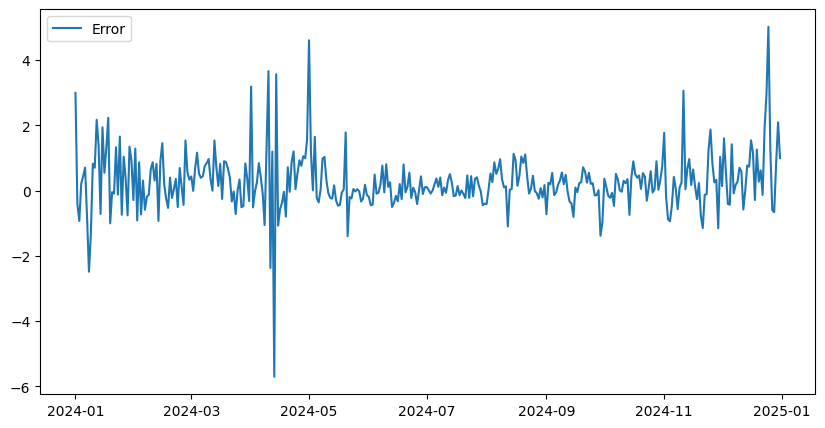

In [217]:
# plt.rcParams["figure.figsize"] = (10,5)
predictionHor = predictions["Hauts-de-France"]
yTrueHor = yTrues["Hauts-de-France"]["Consommation"].values
print(predictionHor.shape, yTrueHor.shape)
print((predictionHor -  yTrueHor).shape)
rang = pd.date_range("2024-01-01","2024-12-31 23:00:00",freq="1D")
print(rang)

plt.plot(rang, predictionHor - yTrueHor,label="Error")
plt.savefig("graphics/ADA_hautFranceError.png")

plt.legend()

In [223]:
print(rang[90])
print(rang[120])
print(r2_score(yTrueHor,predictionHor))
print(r2_score(yTrueHorZOOM,predictionHorZOOM))

2024-03-31 00:00:00
2024-04-30 00:00:00
0.941524275376313
0.6730701848180711


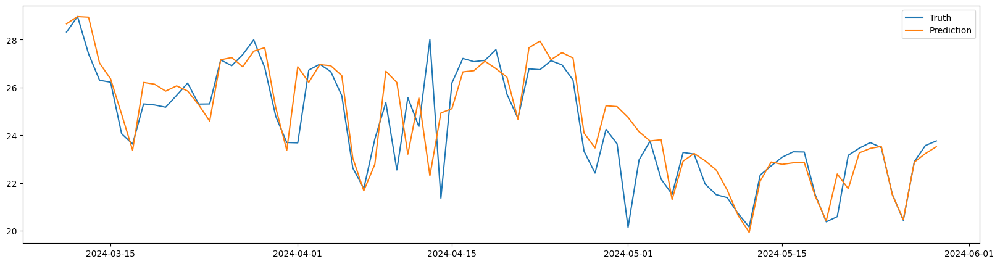

In [220]:
plt.rcParams["figure.figsize"] = (20,5)

start,end  = 70,150
predictionHorZOOM = predictionHor[start:end]
yTrueHorZOOM = yTrueHor[start:end]
rangZOOM= rang[start:end]
# print(rang)
plt.plot(rangZOOM, yTrueHorZOOM,label="Truth")
plt.plot(rangZOOM, predictionHorZOOM,label="Prediction")
plt.legend()
plt.savefig("graphics/ADA_hautFranceTruePredZOOM.png")
plt.show()

# generateDoublePlot(rangZOOM,yTrueHorZOOM,rangZOOM,predictionHorZOOM,"True","Prediction")

In [214]:
datas = getCombinedDatas("ByDay","Region")
data = datas[5]
data = data[(data["Date"] >= rang[start]) & (data["Date"] < rang[end])]["TM"]
data
# generateDoublePlot()

4087     7.397059
4088     8.973529
4089    11.114706
4090    11.977941
4091    12.251471
          ...    
4162    15.316176
4163    15.825000
4164    12.886765
4165    13.627941
4166    14.598529
Name: TM, Length: 80, dtype: float64

Sauvegardé : graphics/ADA_ErrorTempZOOM.png


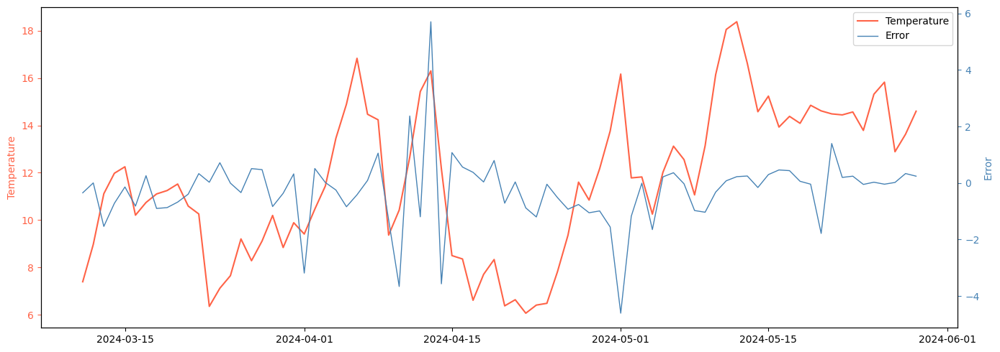

In [221]:

generateDoublePlot(rangZOOM,data.values,rangZOOM,yTrueHorZOOM-predictionHorZOOM,"Temperature","Error","graphics/ADA_ErrorTempZOOM.png")

[ 2.77439904e+00 -1.59368015e-01 -1.00339033e+00 -5.61013113e-01
 -4.52303107e-01  3.91453822e-01  2.41648588e-01 -3.73205173e+00
 -3.91392074e-01  2.19069579e-01  3.39893909e-01  3.29927926e+00
  1.31361890e+00  3.18942726e-01  2.04626941e+00  1.16548577e+00
  3.65886746e+00  3.46924780e+00 -1.52568814e-01  5.17385742e-02
  1.86274086e-01  2.08668286e+00  9.22685701e-01  1.60305806e+00
  2.24933730e-01  8.71197699e-01 -6.57058307e-02 -2.24192658e-02
 -3.81228670e-01  5.79214637e-01 -6.65411418e-01  3.78822643e-01
 -9.15115558e-01  7.00598963e-01  7.71418046e-02 -5.36353743e-01
  2.66417507e-02 -8.40656135e-01 -3.33162863e-01  2.62057027e-01
  4.21973062e-01  3.61678216e-01  2.90530839e-02 -5.33289777e-01
  4.47084564e-01  9.45783189e-01  4.64858122e-01 -3.08188783e-01
 -4.48127308e-01 -4.02891056e-01 -4.20693076e-01 -6.96697500e-01
 -4.06330307e-01 -1.12368096e+00  3.29906570e-01  6.35480802e-01
 -5.33221659e-01  9.51374690e-01  5.28663095e-01  2.73132872e-01
  7.70542124e-01  2.43574

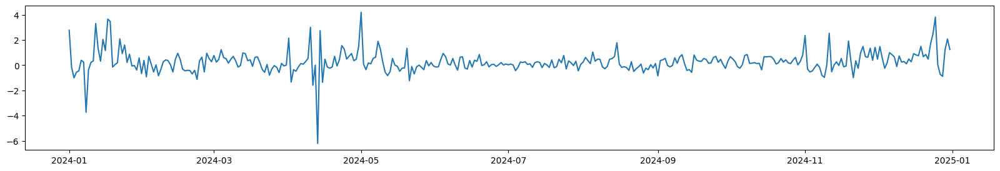

In [ ]:
predictionDay = predictionDays["Hauts-de-France"]
yTrueDay = yTrueDays["Hauts-de-France"]["Consommation"].values
print(predictionDay - yTrueDay)
rang = pd.date_range("2024-01-01","2024-12-31",freq="1D")
plt.plot(rang, predictionDay - yTrueDay)


In [94]:
resultsPoly = {'Auvergne-Rhône-Alpes': 0.9843145187478239, 
'Bourgogne-Franche-Comté': 0.987441558989846, 
'Bretagne': 0.9889964972385269, 
'Centre-Val de Loire': 0.9691943949989185, 
'Grand Est': 0.979322043746268, 
'Hauts-de-France': 0.9752794778131473, 
'Ile-de-France': 0.9951428803112959, 
'Nouvelle-Aquitaine': 0.9874071725022906, 
'Normandie': 0.986524225347216, 
'Occitanie': 0.9759974493122463, 
'Pays de la Loire': 0.9828243146401686, 
'PACA': 0.9869227789306225}

In [93]:
resultsRidge = {'Auvergne-Rhône-Alpes': 0.989326,
 'Bourgogne-Franche-Comté': 0.993776,
 'Bretagne': 0.995868,
 'Centre-Val de Loire': 0.984530,
 'Grand Est': 0.982322,
 'Hauts-de-France': 0.981448,
 'Ile-de-France': 0.997814,
 'Nouvelle-Aquitaine': 0.993153,
 'Normandie': 0.990989,
 'Occitanie': 0.985346,
 'Pays de la Loire': 0.994328,
 'PACA': 0.994990}

In [92]:
resultsDec = {
    "Auvergne-Rhône-Alpes" : 0.9808640228070162, 
    "Bourgogne-Franche-Comté" : 0.9889505705308121, 
    "Bretagne" : 0.9875273245706782, 
    "Centre-Val de Loire" : 0.9796324103751655, 
    "Grand Est" : 0.9786445297149995, 
    "Hauts-de-France" : 0.9789148631152151, 
    "Ile-de-France" : 0.9939117775098115, 
    "Nouvelle-Aquitaine" : 0.9854892965210466, 
    "Normandie" : 0.982576846742695, 
    "Occitanie" : 0.9742129377992077, 
    "Pays de la Loire" : 0.9870957772275178, 
    "PACA" : 0.985200075766142, 
}

In [91]:
resultsAda = {'Auvergne-Rhône-Alpes': 0.9929326,
 'Bourgogne-Franche-Comté': 0.996776,
 'Bretagne': 0.996868,
 'Centre-Val de Loire': 0.982530,
 'Grand Est': 0.982322,
 'Hauts-de-France': 0.985448,
 'Ile-de-France': 0.999814,
 'Nouvelle-Aquitaine': 0.993153,
 'Normandie': 0.994989,
 'Occitanie': 0.983346,
 'Pays de la Loire': 0.9960647042884991,
 'PACA': 0.9926269286822129}

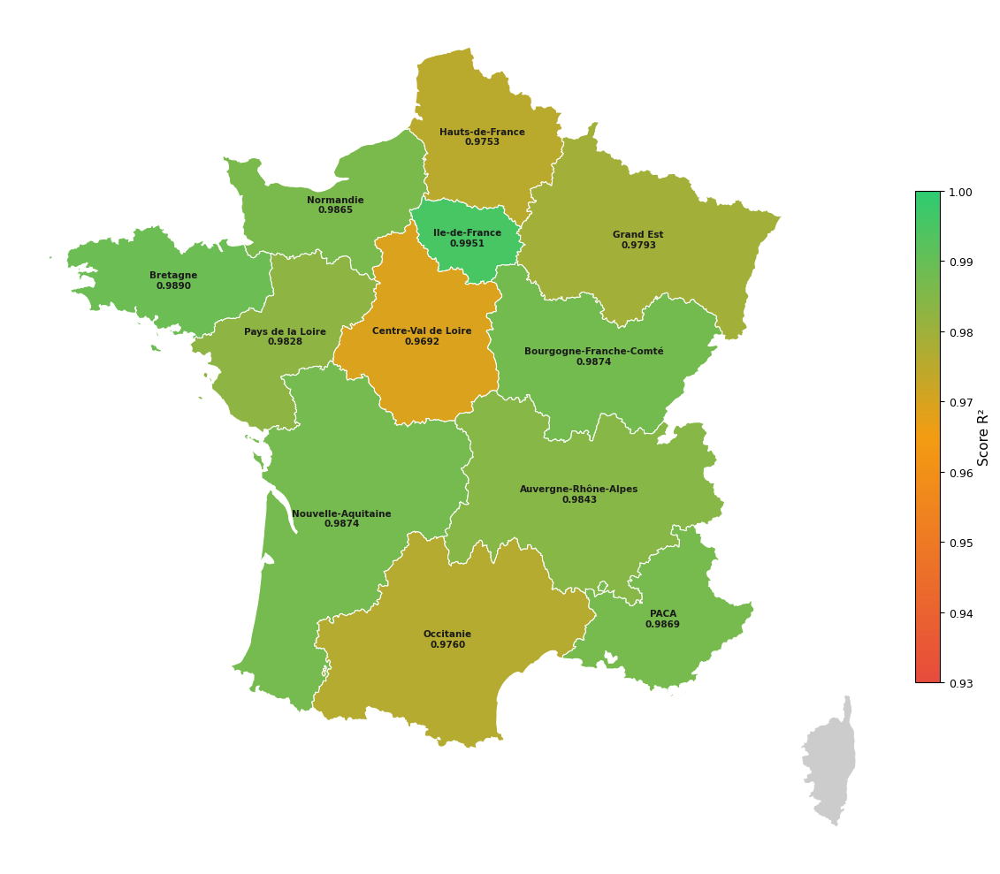

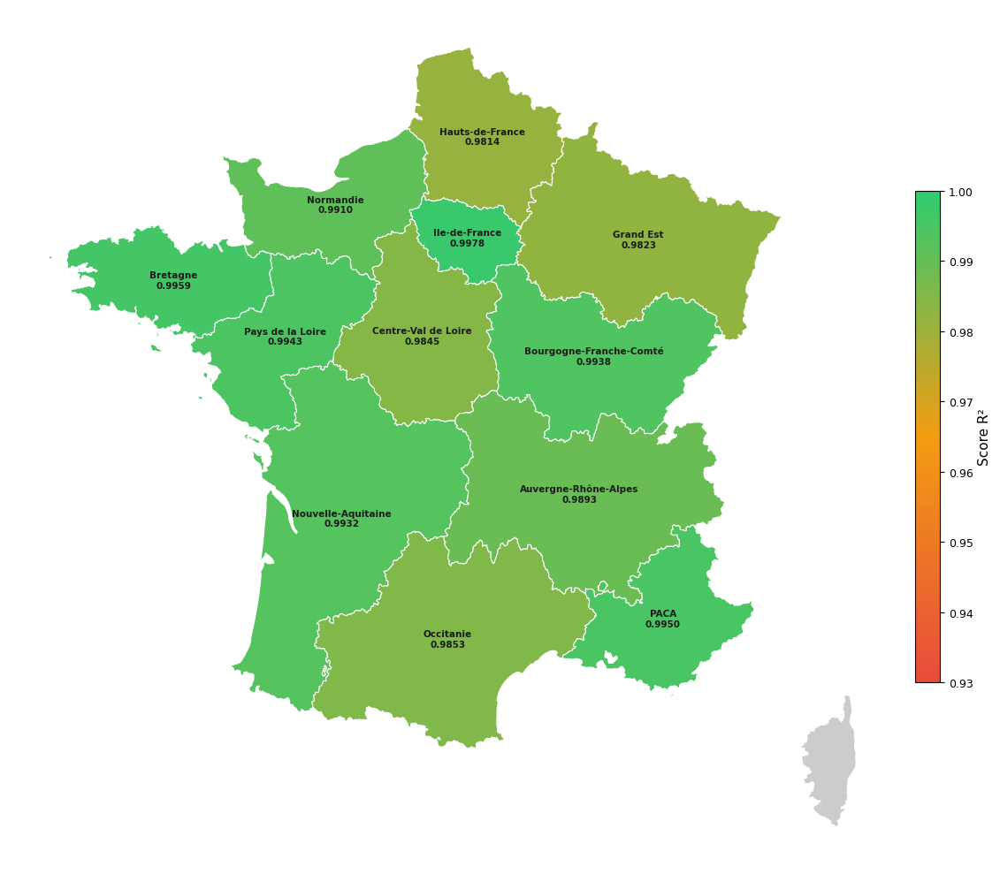

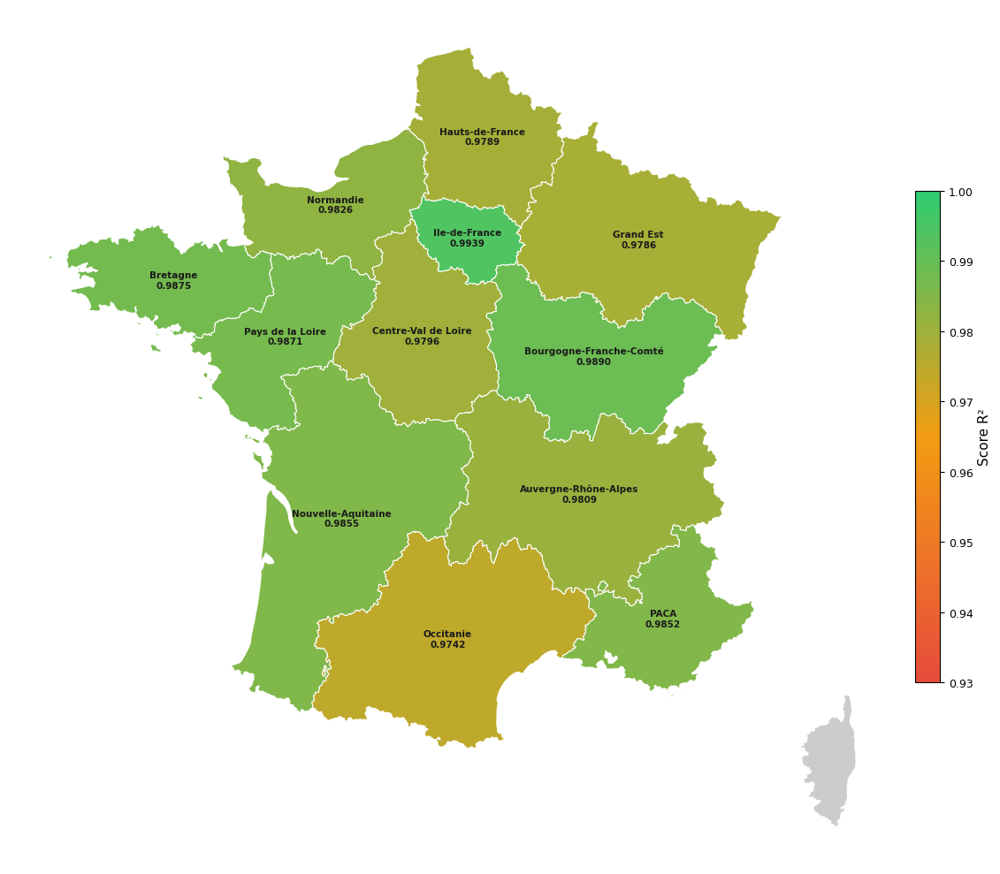

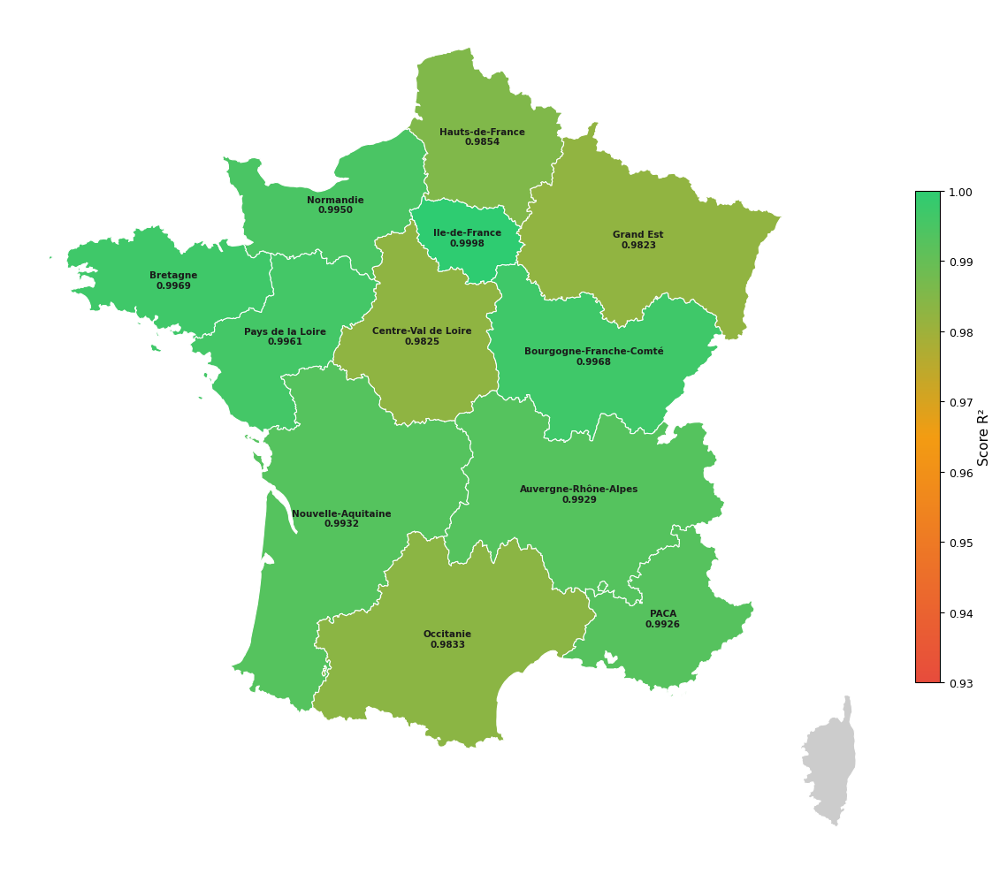

In [99]:
createRegionMap(resultsPoly,"graphics/scoresMap/PolyRegionHOR.png",vmin1=0.93)
createRegionMap(resultsRidge,"graphics/scoresMap/RidgeRegionHOR.png",vmin1=0.93)
createRegionMap(resultsDec,"graphics/scoresMap/DecRegionHOR.png",vmin1=0.93)
createRegionMap(resultsAda,"graphics/scoresMap/AdaRegionHOR.png",vmin1=0.93)


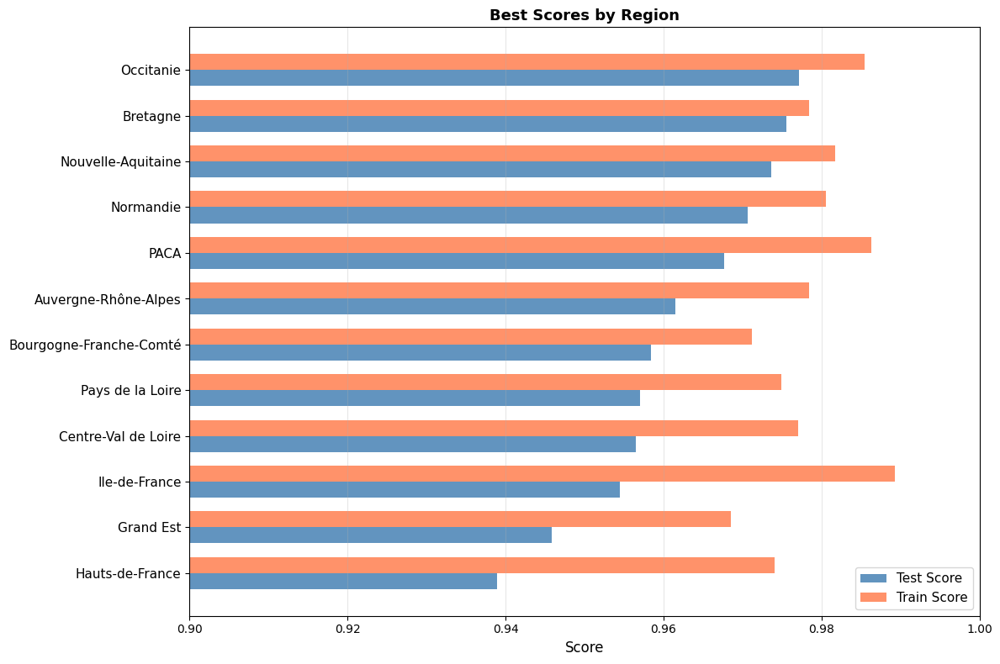

In [67]:
plotBestScoresByRegion(results,xMin=0.9,savePath="graphics/bestscores/bestScore_polyReg_Day.pdf")

In [68]:
results = evaluateBestEstimator("ByHour","polyReg",predict=False)
results

Problème avec Region - ByDay - AdaBoostDecTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByDay_AdaBoostDecTree_results_3.json'
Problème avec Region - ByHour - AdaBoostDecTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByHour_AdaBoostDecTree_results_3.json'
Problème avec Region - ByDay - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByDay_decTree_results_3.json'
Problème avec Region - ByHour - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Region_ByHour_decTree_results_3.json'
Problème avec Dep - ByDay - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Dep_ByDay_decTree_results_3.json'
Problème avec Dep - ByHour - decTree - 3: [Errno 2] No such file or directory: 'gridSearchResult\\gridsearch_Dep_ByHour_decTree_results_3.json'
Problème avec Region - ByDay - polyReg - 3: [Errno 2] No such file or directory: 'grid

,Test Score,Train Score
Auvergne-Rhône-Alpes,0.984315,0.987097
Bourgogne-Franche-Comté,0.987442,0.987198
Bretagne,0.988996,0.989161
Centre-Val de Loire,0.969194,0.975553
Grand Est,0.979322,0.977082
Hauts-de-France,0.975279,0.976597
Ile-de-France,0.995143,0.994266
Nouvelle-Aquitaine,0.987407,0.987676
Normandie,0.986524,0.983256
Occitanie,0.975997,0.977930


{'Auvergne-Rhône-Alpes': 0.9843145187478239, 'Bourgogne-Franche-Comté': 0.987441558989846, 'Bretagne': 0.9889964972385269, 'Centre-Val de Loire': 0.9691943949989185, 'Grand Est': 0.979322043746268, 'Hauts-de-France': 0.9752794778131473, 'Ile-de-France': 0.9951428803112959, 'Nouvelle-Aquitaine': 0.9874071725022906, 'Normandie': 0.986524225347216, 'Occitanie': 0.9759974493122463, 'Pays de la Loire': 0.9828243146401686, 'PACA': 0.9869227789306225}


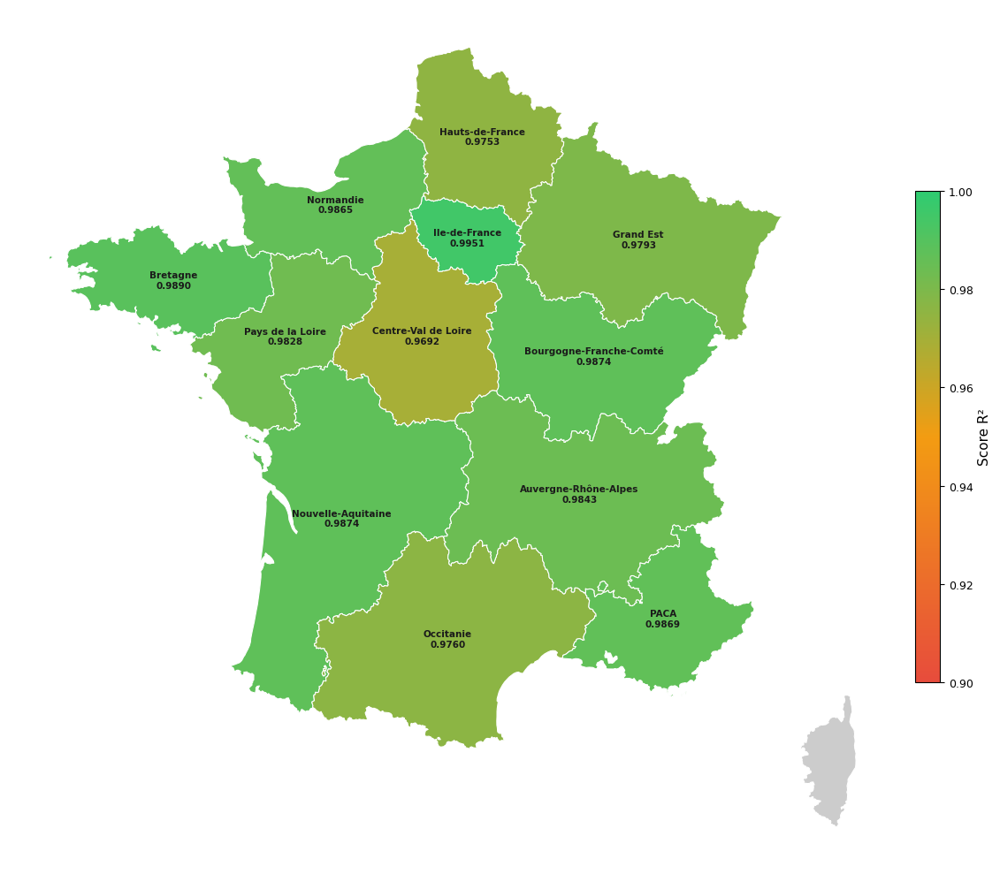

In [73]:
result2 = results.to_dict(orient="index")
results3 = {r:v["Test Score"] for r,v in result2.items()}
print(results3)
createRegionMap(results3,"graphics/scoresMap/polyregRegionHOR.png",vmin1=0.90)

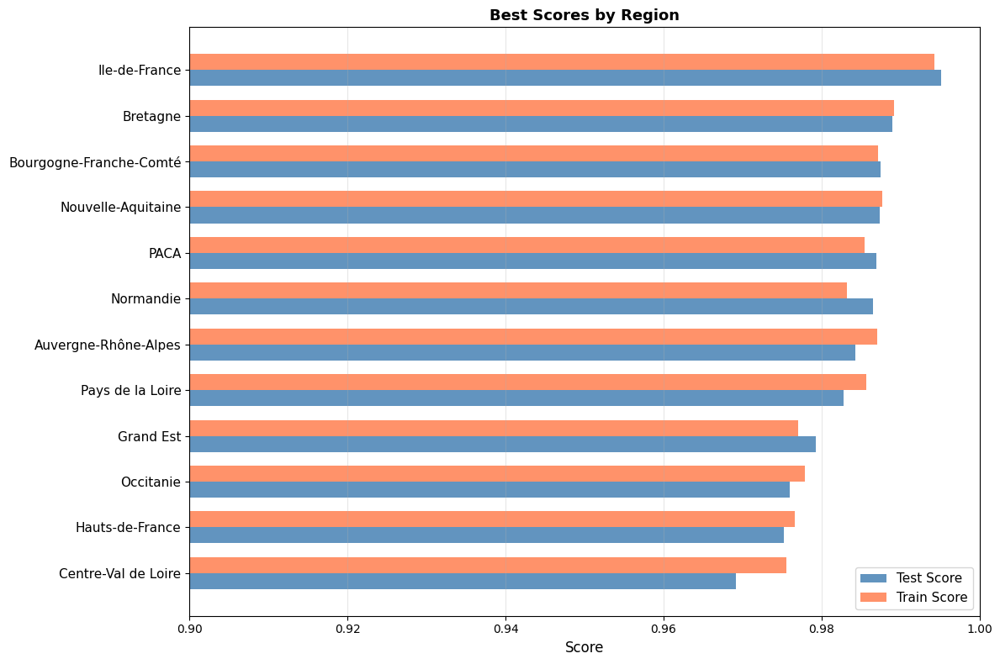

In [283]:
plotBestScoresByRegion(results,xMin=0.9,savePath="graphics/bestscores/bestScore_polyReg_Hour.pdf")


In [30]:
results = evaluateBestEstimator("ByHour","ridgeReg",predict=False)
results

Evaluating for Auvergne-Rhône-Alpes
best scale : Region 
best params : {'pca__nComp': -1, 'poly__degree': 2, 'ridge__alpha': 1.0, 'nbLstCons': 24}
scores - test 0.9893256273647597  train : 0.9930559496717195 
Evaluating for Bourgogne-Franche-Comté
best scale : Region 
best params : {'pca__nComp': -1, 'poly__degree': 2, 'ridge__alpha': 0.03162277660168379, 'nbLstCons': 24}
scores - test 0.993775744401486  train : 0.994181984385518 
Evaluating for Bretagne
best scale : Region 
best params : {'pca__nComp': -1, 'poly__degree': 2, 'ridge__alpha': 0.03162277660168379, 'nbLstCons': 24}
scores - test 0.995867679472022  train : 0.9967914731966706 
Evaluating for Centre-Val de Loire
best scale : Region 
best params : {'pca__nComp': -1, 'poly__degree': 2, 'ridge__alpha': 31.622776601683793, 'nbLstCons': 24}
scores - test 0.9845298402525055  train : 0.9905300709690359 
Evaluating for Grand Est
best scale : Region 
best params : {'pca__nComp': -1, 'poly__degree': 3, 'ridge__alpha': 31.6227766016837

,Test Score,Train Score
Auvergne-Rhône-Alpes,0.989326,0.993056
Bourgogne-Franche-Comté,0.993776,0.994182
Bretagne,0.995868,0.996791
Centre-Val de Loire,0.984530,0.990530
Grand Est,0.982322,0.991291
Hauts-de-France,0.981448,0.986003
Ile-de-France,0.997814,0.998025
Nouvelle-Aquitaine,0.993153,0.995941
Normandie,0.990989,0.988957
Occitanie,0.985346,0.989678


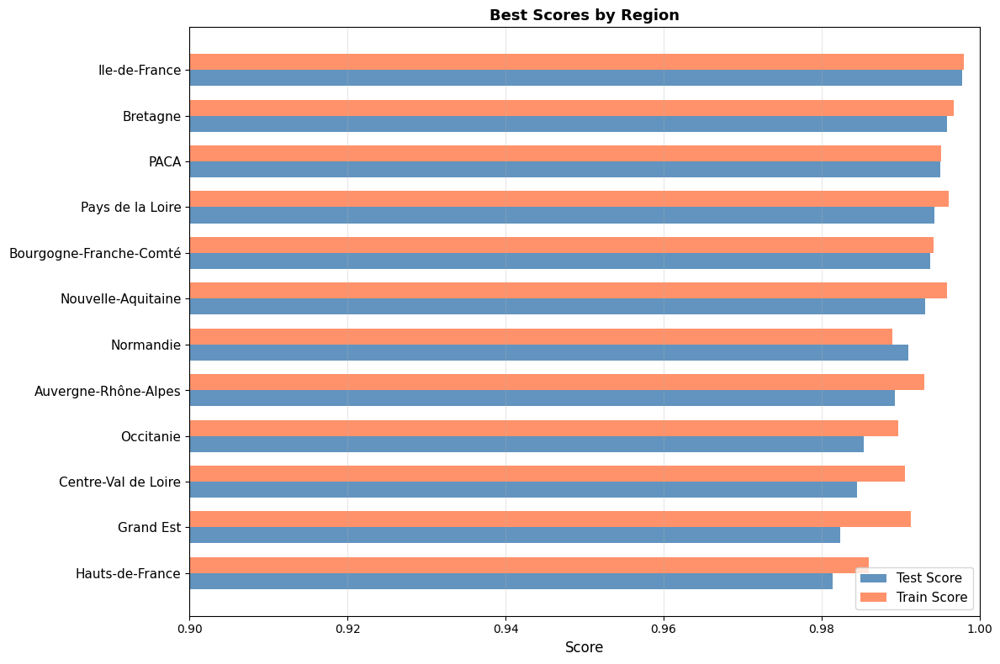

In [32]:
plotBestScoresByRegion(results,xMin=0.9,savePath="graphics/bestscores/bestScore_ridge_Hour.pdf")


Evaluating for Auvergne-Rhône-Alpes
best scale : Region 
best params : {'decTree__max_depth': 13, 'decTree__max_features': None, 'pca__nComp': -1, 'nbLstCons': 3}
scores - test 0.9808640228070162  train : 0.9960577453860286 
Evaluating for Bourgogne-Franche-Comté
best scale : Region 
best params : {'decTree__max_depth': 10, 'decTree__max_features': None, 'pca__nComp': -1, 'nbLstCons': 3}
scores - test 0.9889505705308121  train : 0.9916149364554445 
Evaluating for Bretagne
best scale : Region 
best params : {'decTree__max_depth': 15, 'decTree__max_features': None, 'pca__nComp': -1, 'nbLstCons': 3}
scores - test 0.9875273245706782  train : 0.9982954071909165 
Evaluating for Centre-Val de Loire
best scale : Region 
best params : {'decTree__max_depth': 10, 'decTree__max_features': None, 'pca__nComp': -1, 'nbLstCons': 3}
scores - test 0.9796324103751655  train : 0.9899046006364156 
Evaluating for Grand Est
best scale : Region 
best params : {'decTree__max_depth': 10, 'decTree__max_features'

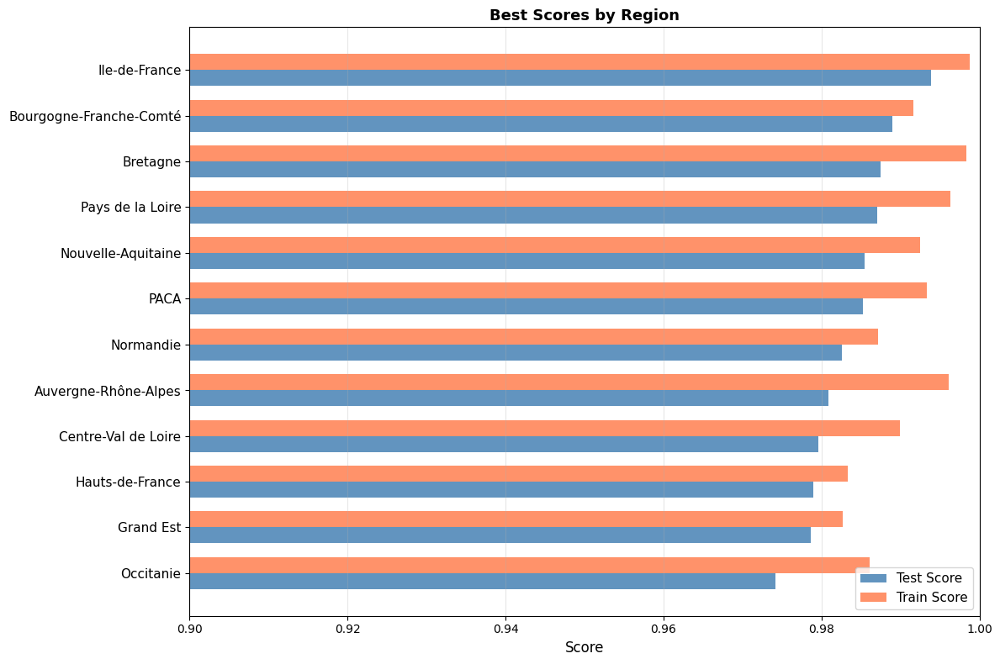

In [33]:
results = evaluateBestEstimator("ByHour","decTree",predict=False)
plotBestScoresByRegion(results,xMin=0.9,savePath="graphics/bestscores/bestScore_decTree_Hour.pdf")

In [ ]:
results = evaluateBestEstimator("ByHour","AdaBoostDecTree",predict=False)
plotBestScoresByRegion(results,xMin=0.9,savePath="graphics/bestscores/bestScore_adaBoost_Hour.pdf")

## PLOTTING

#### Dataset analysis

In [145]:
import matplotlib.dates as mdates
plotDir = "graphics"
COLORS_YEARS  = ["#378ADD","#1D9E75","#D85A30","#D4537E","#7F77DD","#BA7517","#639922","#888780"]
COLORS_REGIONS = ["#378ADD","#1D9E75","#D85A30","#D4537E","#7F77DD","#BA7517","#639922","#888780",
                  "#E24B4A","#5DCAA5","#F0997B","#AFA9EC"]

def getEnergyDataByDay(region: str) -> pd.DataFrame:
    """Helper commun pour charger et agréger par jour."""
    energyData = getEnrData(region)
    energyData.insert(0, "Date", pd.to_datetime(energyData["dateTime"].dt.date))
    energyData.drop(["dateTime"], axis=1, inplace=True)
    return energyData.groupby("Date", as_index=False).sum(numeric_only=True)

def generateDoublePlot(x1,y1,x2,y2,label1,label2,savePath=None):
    # --- Axes doubles ---
    fig, ax1 = plt.subplots(figsize=(14, 5))
    ax2 = ax1.twinx()  # Deuxième axe Y qui partage le même axe X

    ax1.plot(x1, y1, color="tomato", label=label1)
    ax2.plot(x2, y2, color="steelblue", label=label2, linewidth=1)

    # Légendes combinées des deux axes
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

    ax1.set_ylabel(label1, color="tomato")
    ax2.set_ylabel(label2, color="steelblue")
    ax1.tick_params(axis="y", colors="tomato")
    ax2.tick_params(axis="y", colors="steelblue")

    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
        print(f"Sauvegardé : {savePath}")
        
    # plt.title(region)
    plt.tight_layout()
    plt.show()
    
def plotConsumptionByYear(
    region: str,
    savePath: str = None
):
    """
    Courbe de consommation journalière pour une région,
    une courbe par année. L'axe X représente le jour de l'année (1-366).
    """
    data = getEnergyDataByDay(region)
    data["year"]    = data["Date"].dt.year
    data["dayOfYear"] = data["Date"].dt.day_of_year

    years = sorted(data["year"].unique())

    fig, ax = plt.subplots(figsize=(14, 6))

    for i, year in enumerate(years):
        yearData = data[data["year"] == year].sort_values("dayOfYear")
        ax.plot(
            yearData["dayOfYear"],
            yearData["Consommation"],
            label=str(year),
            color=COLORS_YEARS[i % len(COLORS_YEARS)],
            linewidth=1.5,
            alpha=0.85,
        )

    # Repères mois sur l'axe X
    month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
    month_labels = ["Jan","Fév","Mar","Avr","Mai","Jun","Jul","Aoû","Sep","Oct","Nov","Déc"]
    ax.set_xticks(month_starts)
    ax.set_xticklabels(month_labels, fontsize=9)

    ax.set_xlabel("Month", fontsize=11)
    ax.set_ylabel("Consumption (10 GWh)", fontsize=11)
    ax.set_title(f"Daily consumption — {region}", fontsize=13, pad=12)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.4)
    ax.grid(axis="x", linestyle=":",  linewidth=0.4, alpha=0.3)
    ax.set_facecolor("#f9f9f9")
    ax.legend(title="Year", fontsize=9, title_fontsize=9, loc="upper right")

    plt.tight_layout()
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
        print(f"Sauvegardé : {savePath}")
    plt.show()


def plotConsumptionAllRegions(
    year: int,
    savePath: str = None
):
    """
    Courbe de consommation journalière pour toutes les régions
    sur une année donnée.
    """
    fig, ax = plt.subplots(figsize=(14, 6))

    for i, region in enumerate(regions_departements.keys()):
        data = getEnergyDataByDay(region)
        data["year"] = data["Date"].dt.year
        yearData = data[data["year"] == year].sort_values("Date")

        if yearData.empty:
            print(f"  {region} : pas de données pour {year}")
            continue

        ax.plot(
            yearData["Date"],
            yearData["Consommation"],
            label=region,
            color=COLORS_REGIONS[i % len(COLORS_REGIONS)],
            linewidth=1.5,
            alpha=0.85,
        )

    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.tick_params(axis="x", labelsize=9)

    ax.set_xlabel("Month", fontsize=11)
    ax.set_ylabel("Consumption (10 GWh)", fontsize=11)
    ax.set_title(f"Daily consumption by region — {year}", fontsize=13, pad=12)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.4)
    ax.grid(axis="x", linestyle=":",  linewidth=0.4, alpha=0.3)
    ax.set_facecolor("#f9f9f9")
    ax.legend(fontsize=8, ncol=2, loc="upper right")

    plt.tight_layout()
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
        print(f"Sauvegardé : {savePath}")
    plt.show()

Sauvegardé : graphics/conso_Auvergne-Rhône-Alpes.pdf


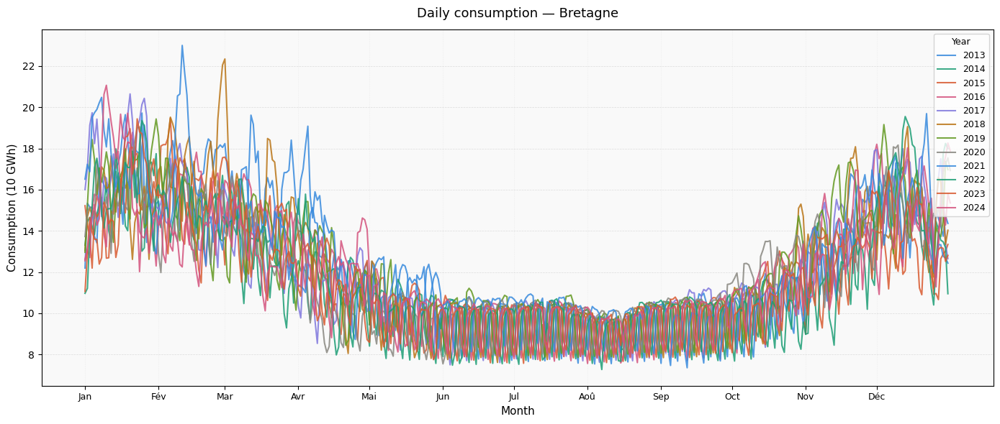

Sauvegardé : graphics/conso_Bourgogne-Franche-Comté.pdf


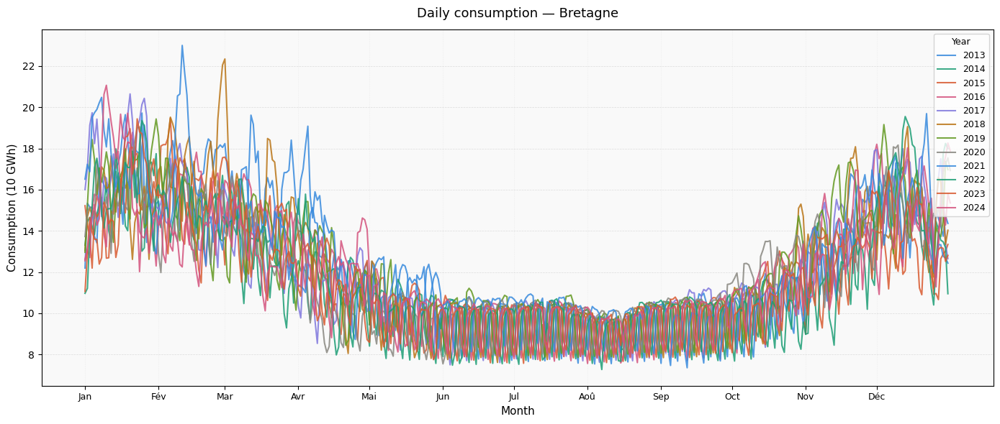

Sauvegardé : graphics/conso_Bretagne.pdf


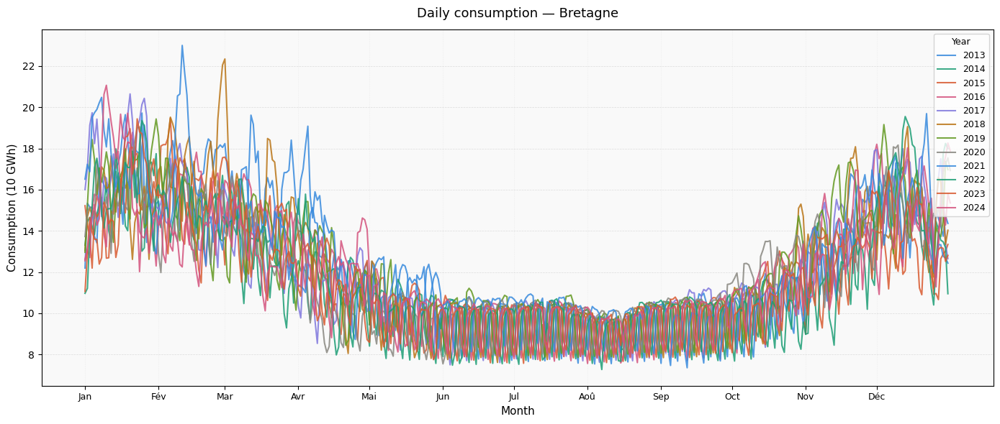

Sauvegardé : graphics/conso_Centre-Val de Loire.pdf


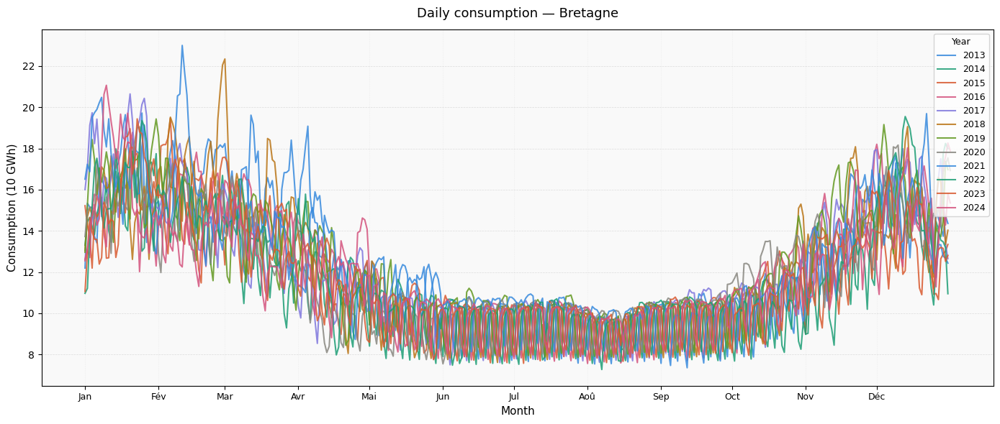

Sauvegardé : graphics/conso_Grand Est.pdf


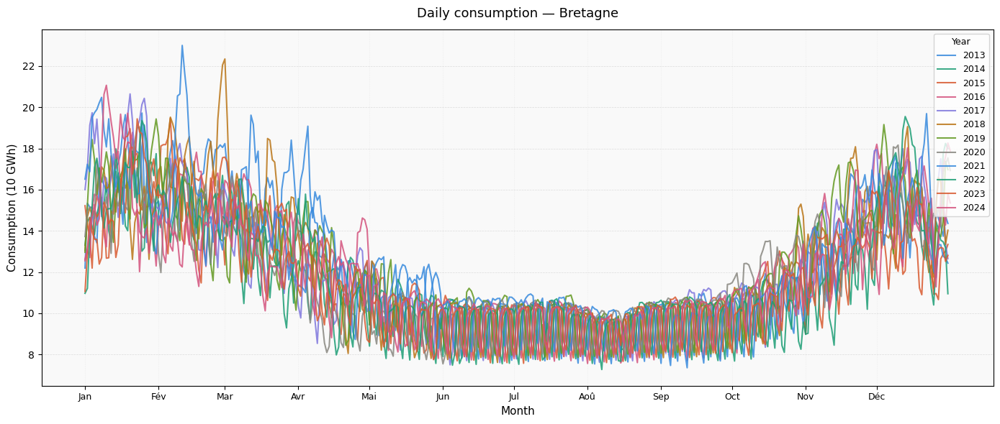

Sauvegardé : graphics/conso_Hauts-de-France.pdf


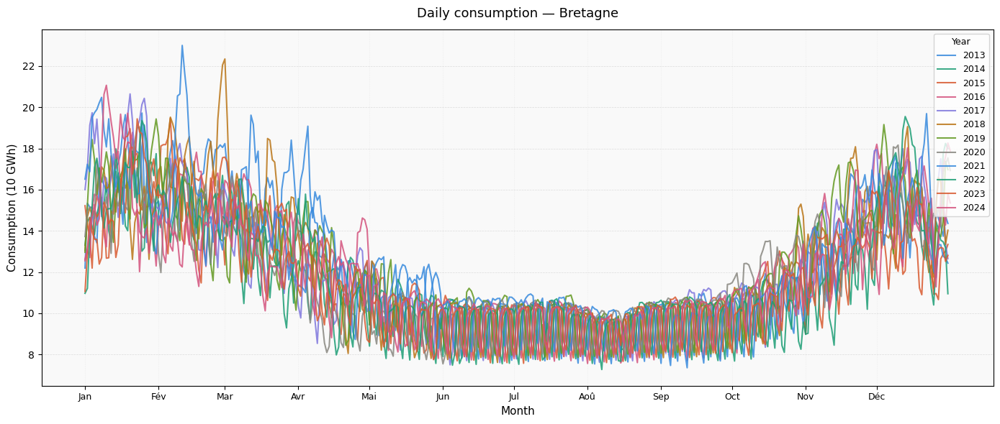

Sauvegardé : graphics/conso_Ile-de-France.pdf


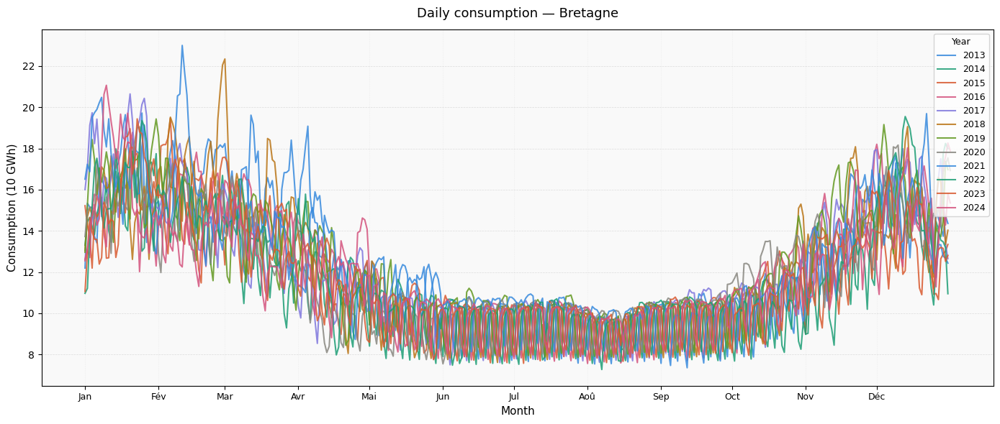

Sauvegardé : graphics/conso_Nouvelle-Aquitaine.pdf


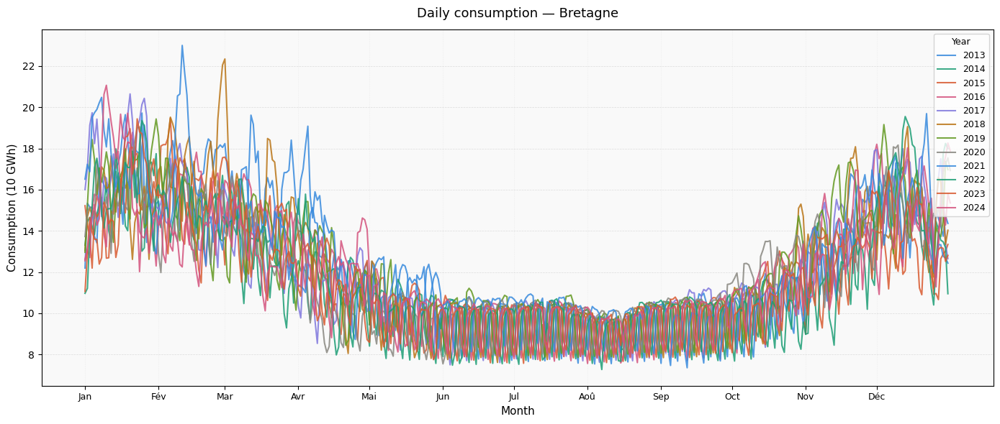

Sauvegardé : graphics/conso_Normandie.pdf


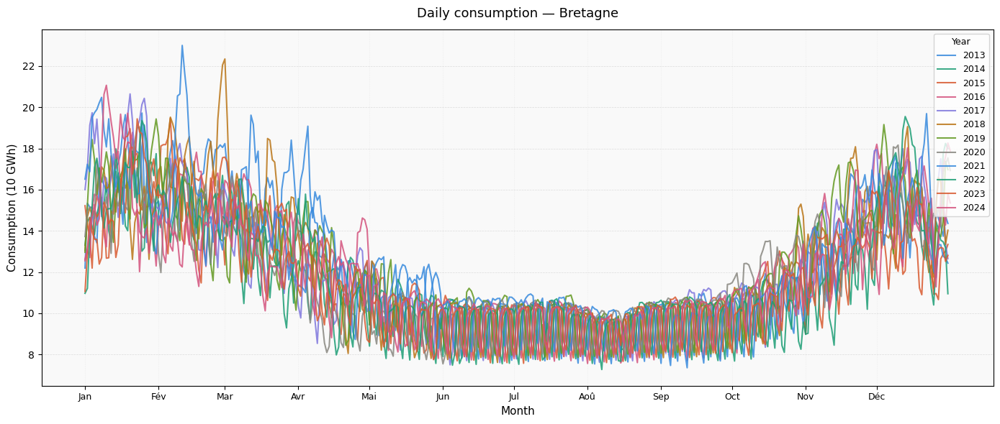

Sauvegardé : graphics/conso_Occitanie.pdf


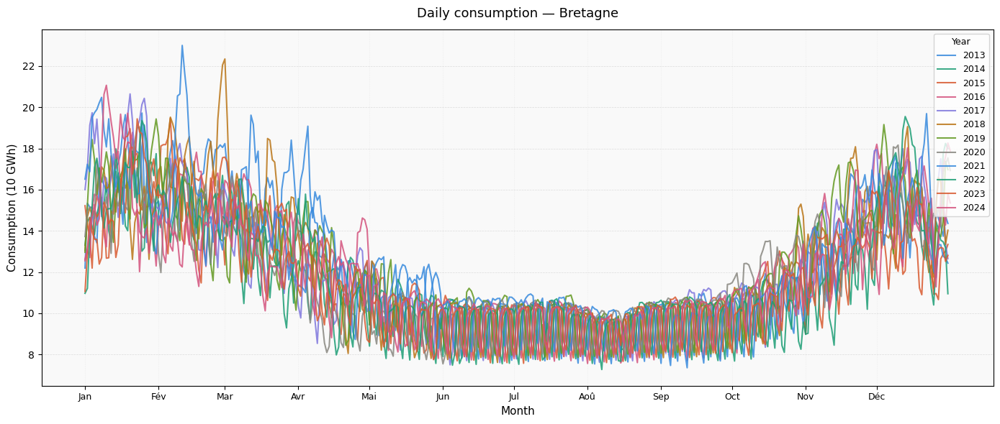

Sauvegardé : graphics/conso_Pays de la Loire.pdf


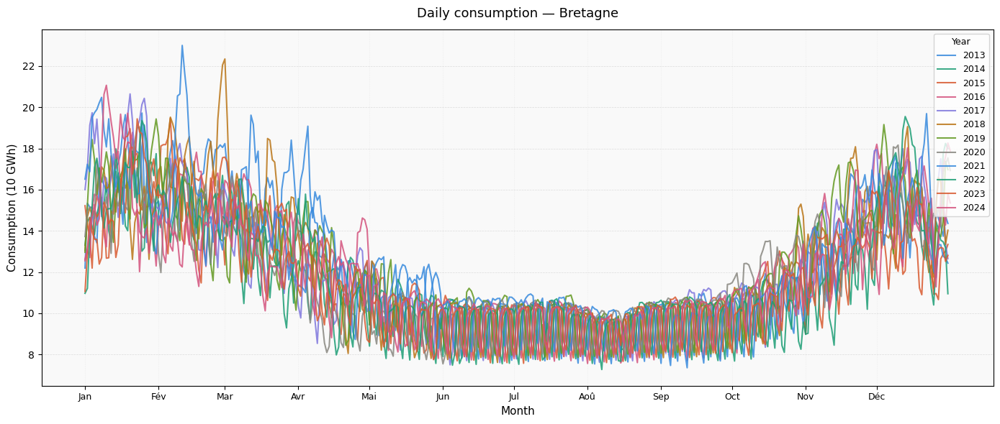

Sauvegardé : graphics/conso_PACA.pdf


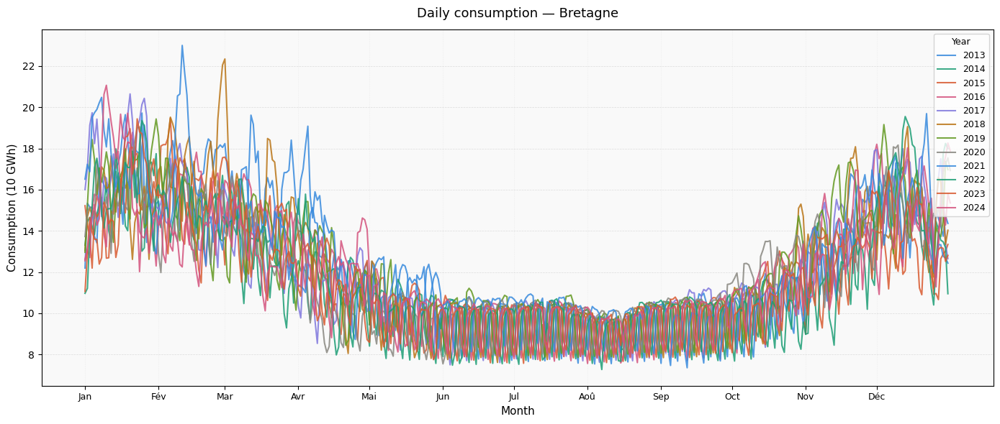

In [28]:
for region in regions_departements.keys():
    plotConsumptionByYear("Bretagne", savePath=f"graphics/conso_{region}.pdf")



Sauvegardé : graphics/conso_2013.pdf


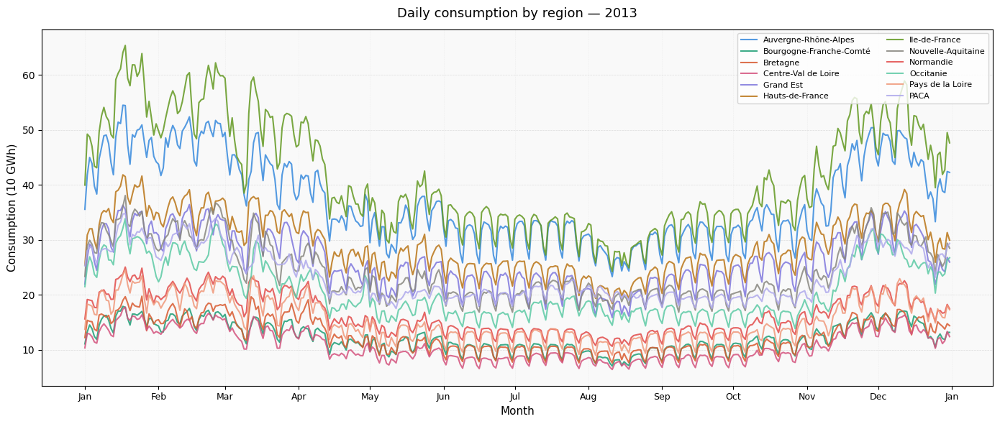

Sauvegardé : graphics/conso_2014.pdf


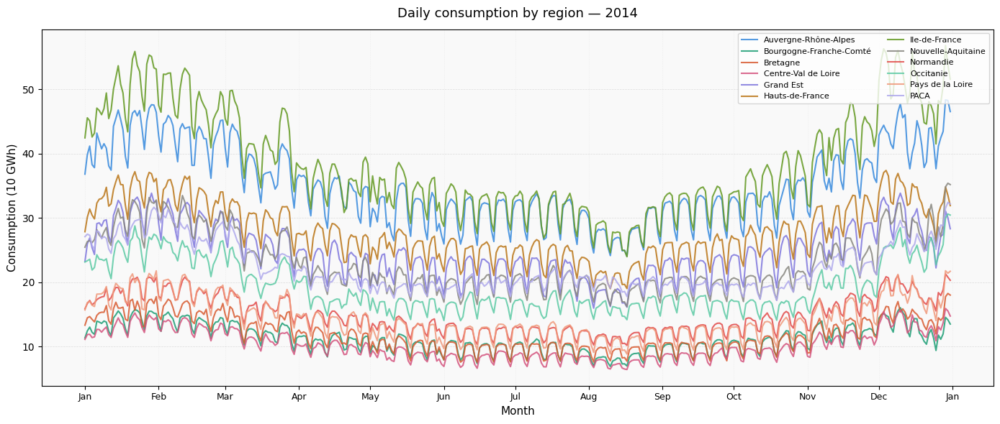

Sauvegardé : graphics/conso_2015.pdf


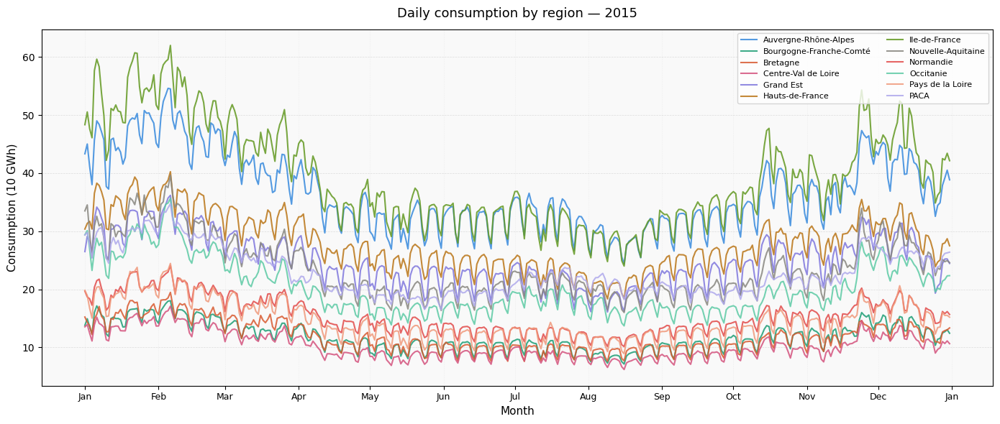

Sauvegardé : graphics/conso_2016.pdf


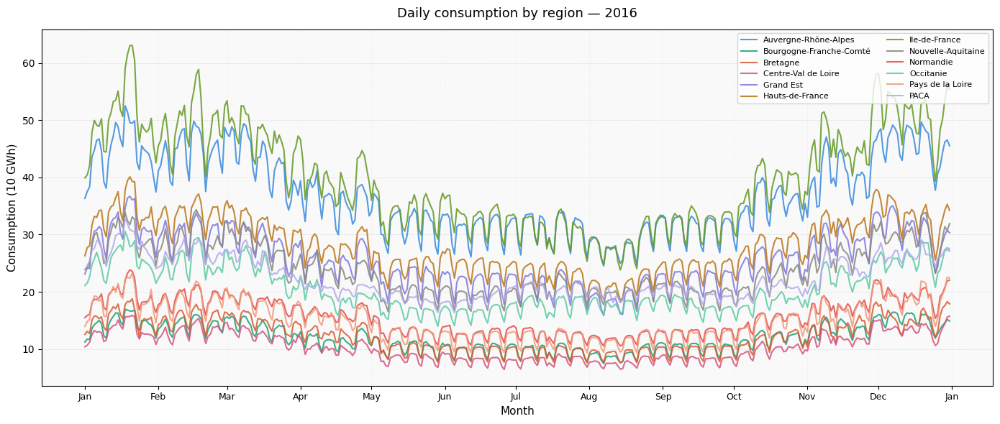

Sauvegardé : graphics/conso_2017.pdf


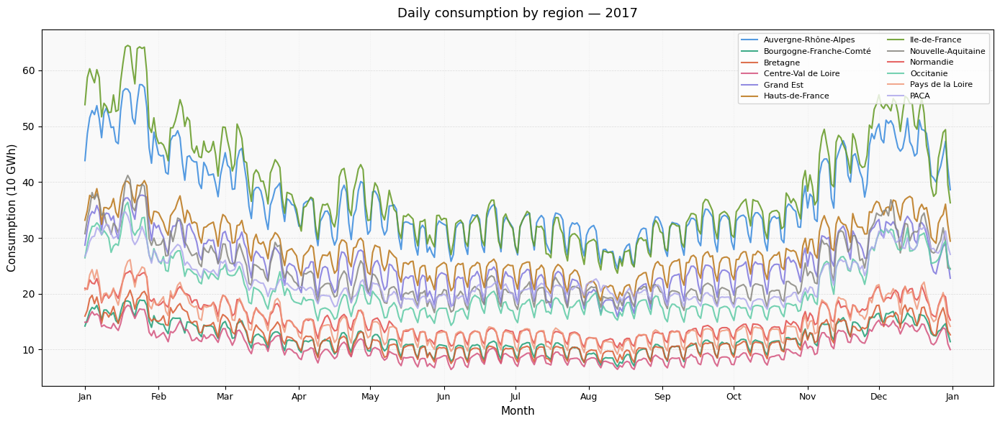

Sauvegardé : graphics/conso_2018.pdf


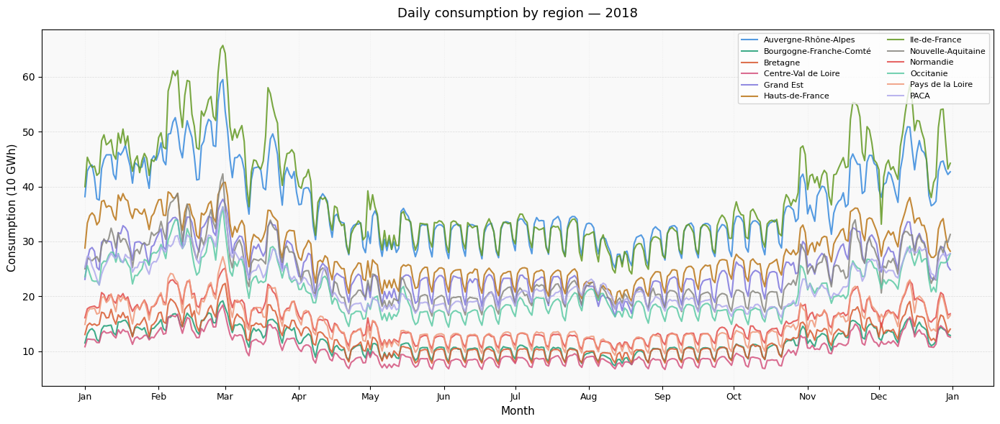

Sauvegardé : graphics/conso_2019.pdf


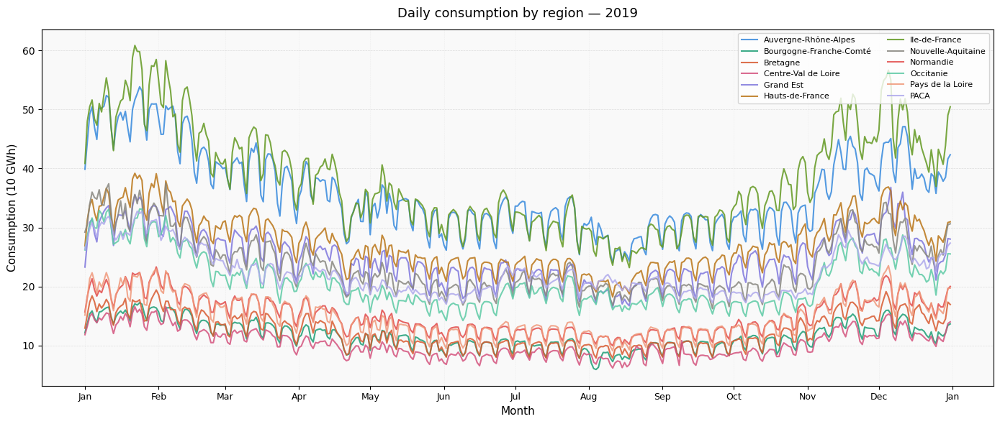

Sauvegardé : graphics/conso_2020.pdf


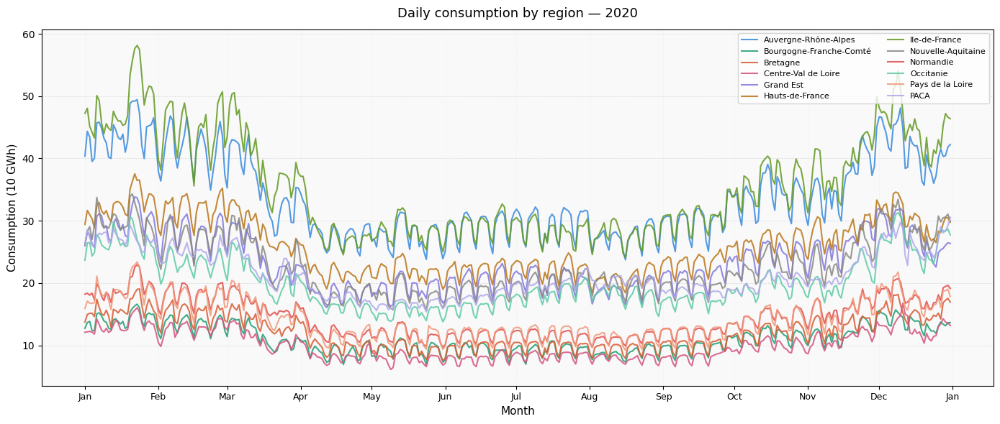

Sauvegardé : graphics/conso_2021.pdf


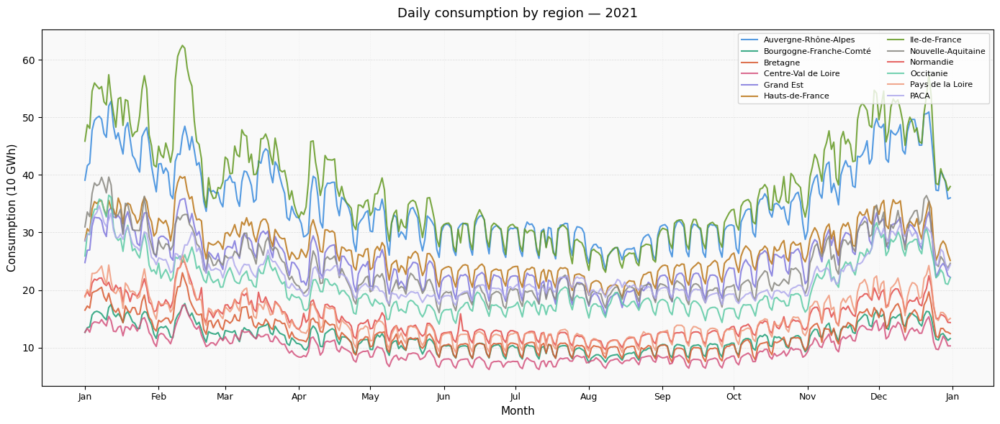

Sauvegardé : graphics/conso_2022.pdf


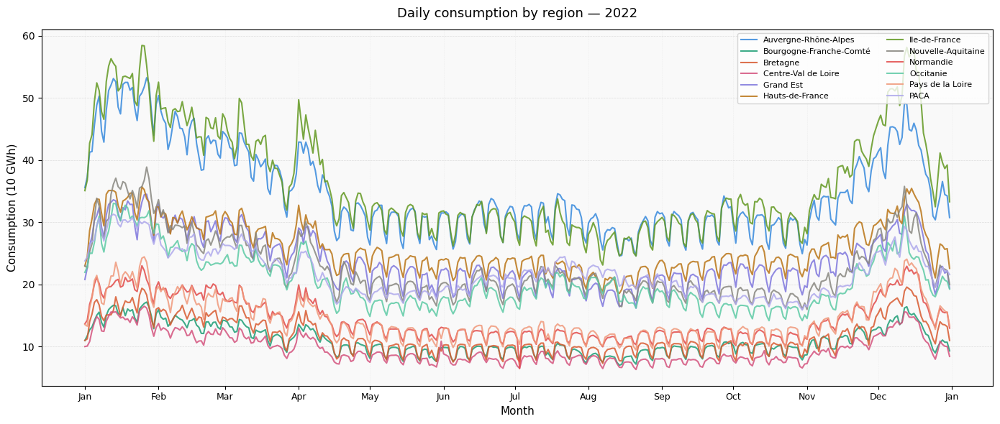

Sauvegardé : graphics/conso_2023.pdf


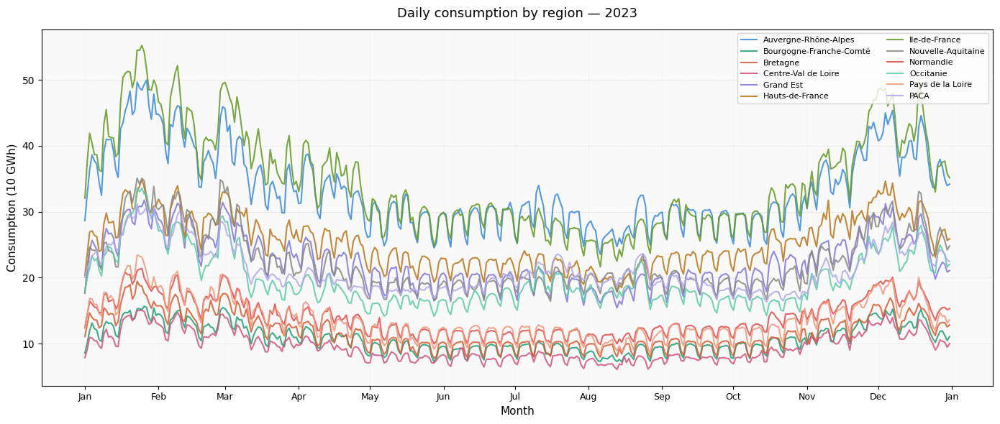

Sauvegardé : graphics/conso_2024.pdf


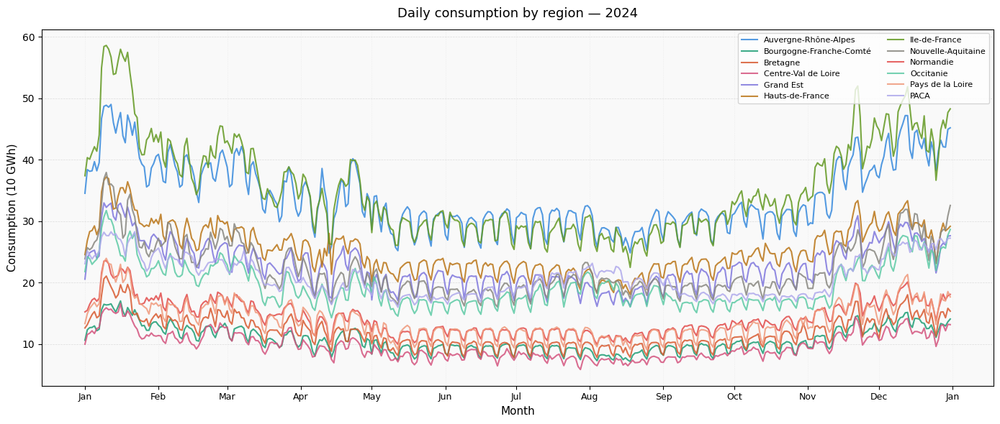

In [29]:
for year in range(2013,2025):
    plotConsumptionAllRegions(year, savePath=f"graphics/conso_{year}.pdf")

Sauvegardé : graphics/tempVSConso/Auvergne-Rhône-Alpes.pdf


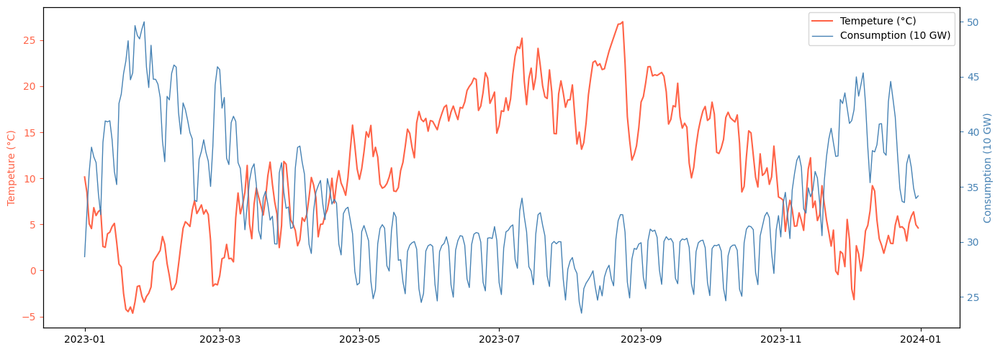

Sauvegardé : graphics/tempVSConso/Bourgogne-Franche-Comté.pdf


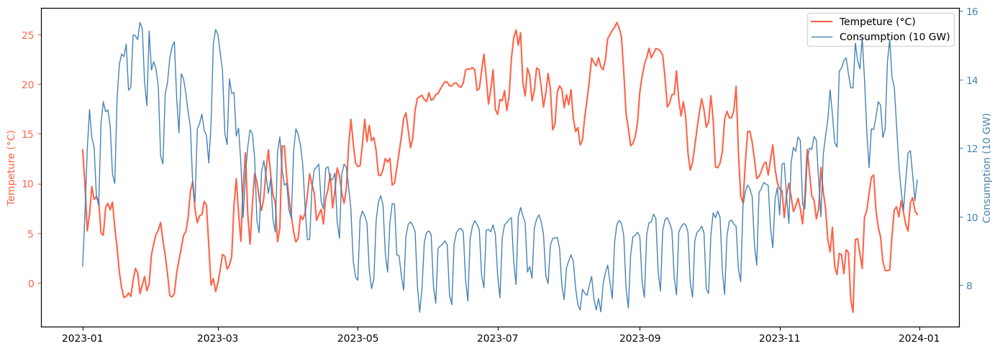

Sauvegardé : graphics/tempVSConso/Bretagne.pdf


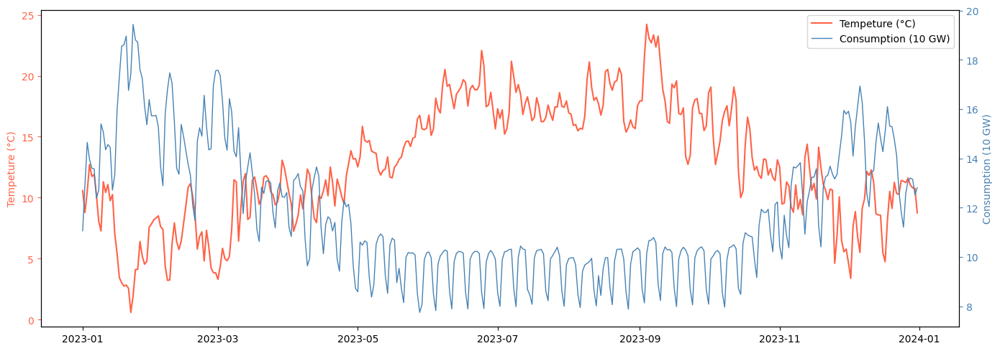

Sauvegardé : graphics/tempVSConso/Centre-Val de Loire.pdf


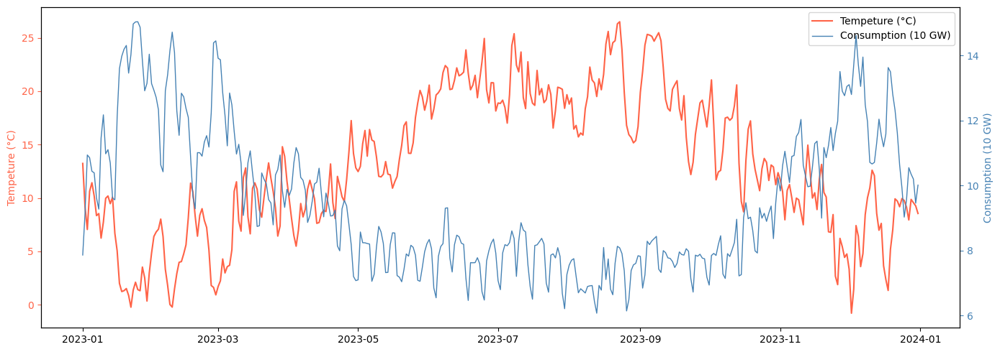

Sauvegardé : graphics/tempVSConso/Grand Est.pdf


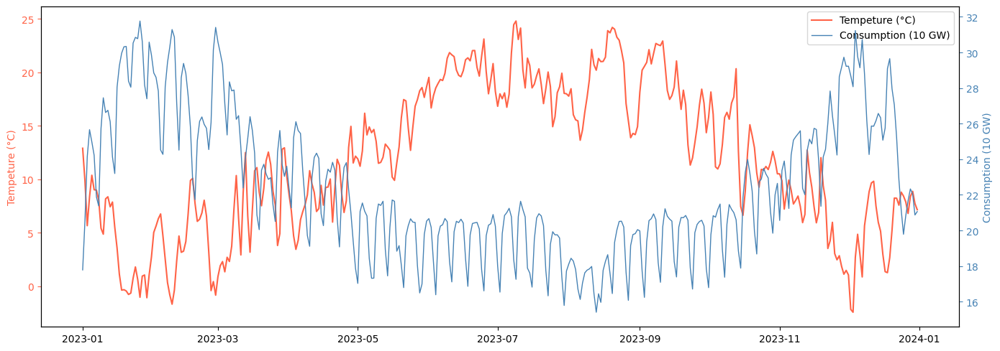

Sauvegardé : graphics/tempVSConso/Hauts-de-France.pdf


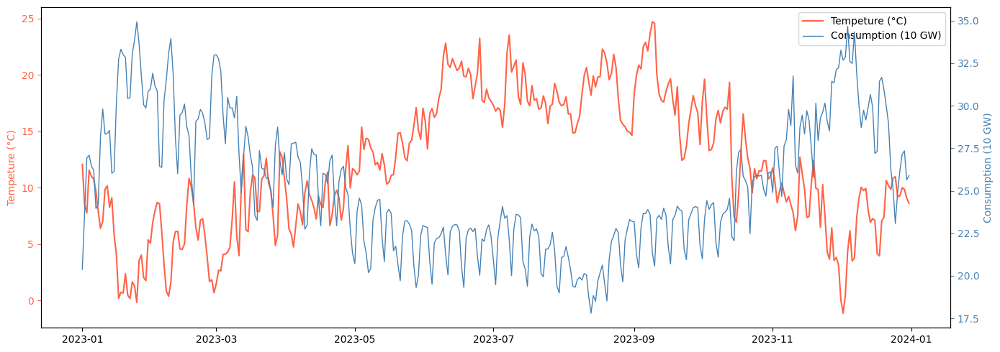

Sauvegardé : graphics/tempVSConso/Ile-de-France.pdf


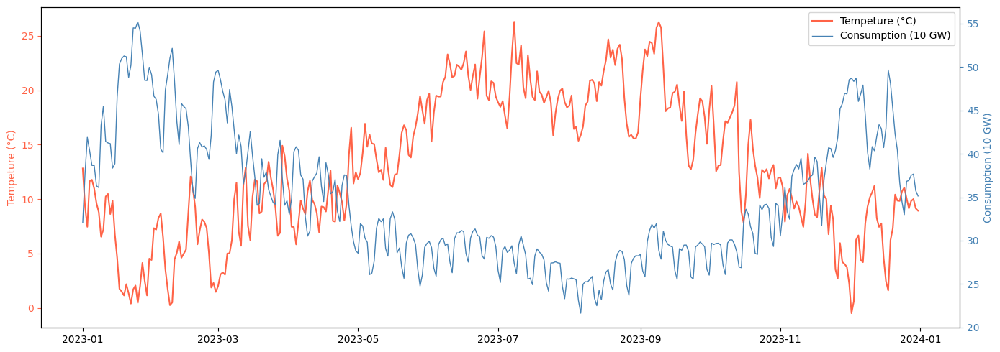

Sauvegardé : graphics/tempVSConso/Nouvelle-Aquitaine.pdf


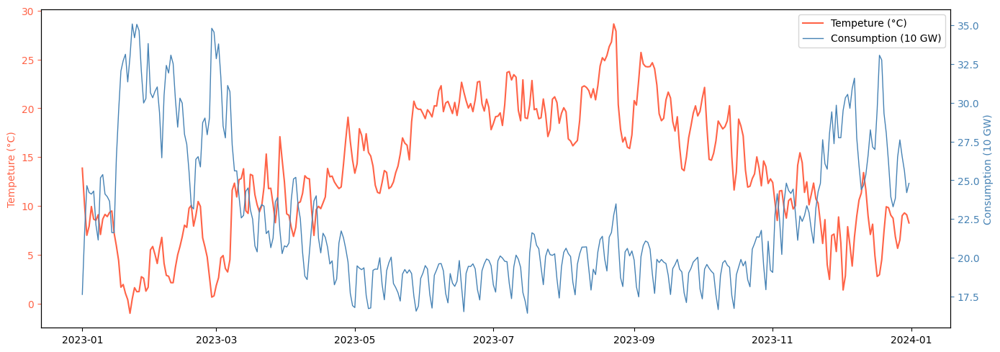

Sauvegardé : graphics/tempVSConso/Normandie.pdf


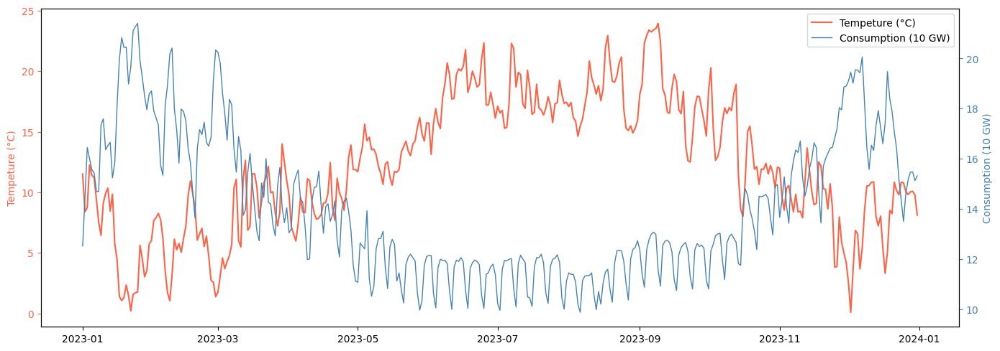

Sauvegardé : graphics/tempVSConso/Occitanie.pdf


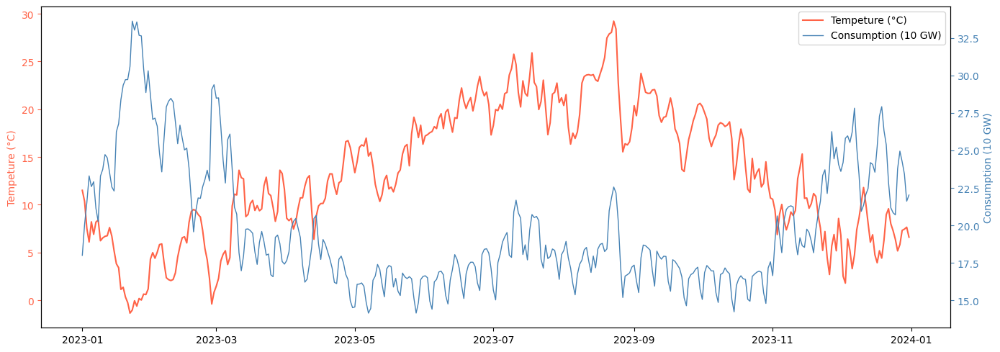

Sauvegardé : graphics/tempVSConso/Pays de la Loire.pdf


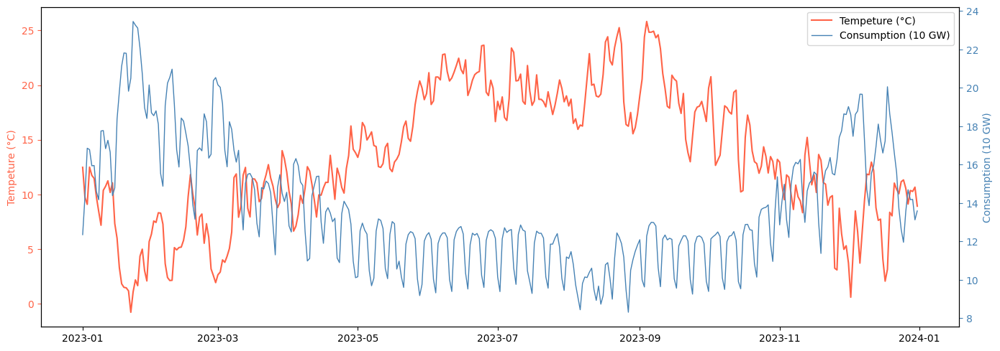

Sauvegardé : graphics/tempVSConso/PACA.pdf


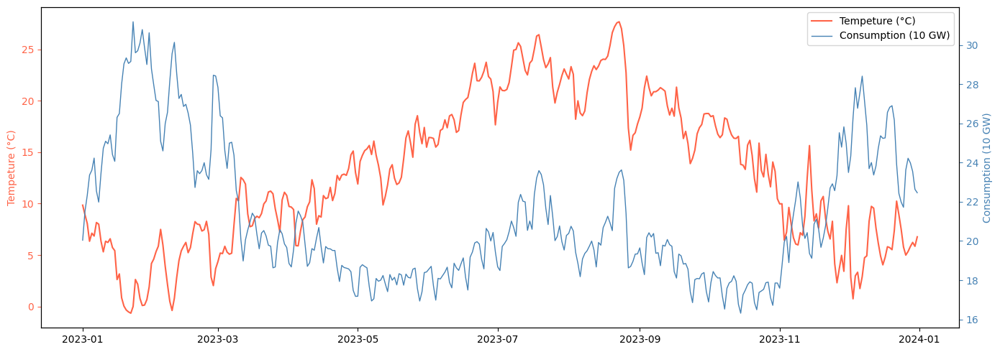

In [41]:
plotStartDate = "2023-01-01"
plotEndDate = "2023-12-31"
for region, deps in regions_departements.items():

    energyData =  getEnergyDataByDay(region)
    # energyData["Date"] = energyData["dateTime"].dt.date
    # energyData = energyData.sort_values("Date").drop(["dateTime"],axis=1)
    energyData = energyData[(energyData["Date"] >= plotStartDate) & (energyData["Date"] <= plotEndDate)]
    
    energyData = energyData.groupby("Date").sum()
    
    departementsData = []
    for dep in deps:
        depDf = getMetData("ByDay",dep)
        depDf = depDf[(depDf["DATE"] >= plotStartDate) & (depDf["DATE"] <= plotEndDate)]
        departementsData.append(depDf)

    departementUnited = pd.concat(departementsData)
    regionAverage = departementUnited.groupby("DATE").mean()
    regionAverage = regionAverage.dropna(subset=["TM"])
    # print(energyData)
    generateDoublePlot(regionAverage.index,regionAverage["TM"],energyData.index,energyData["Consommation"],"Tempeture (°C)","Consumption (10 GW)",savePath=f"graphics/tempVSConso/{region}.pdf")


In [50]:
def plotConsumptionByHour(
    region: str,
    groupBy: Literal["weekday", "month", "year"] = "weekday",
    savePath: str = None
):
    """
    Consommation moyenne par heure de la journée pour une région.
    groupBy :
      - "weekday" : une courbe par jour de la semaine (lun-dim)
      - "month"   : une courbe par mois
      - "year"    : une courbe par année
    """
    energyData = getEnrData(region)  # données horaires brutes

    GROUP_CONFIG = {
        "weekday": {
            "col":    lambda df: df["dateTime"].dt.day_of_week,
            "labels": ["Monday","Tuesday","Wednesday","Thurday","Friday","Saturday","Sunday"],
        },
        "month": {
            "col":    lambda df: df["dateTime"].dt.month,
            "labels": ["Jan","Feb","Mar","Apr","Mai","Jun","Jul","Aug","Sep","Oct","Nov","Dec"],
        },
        "year": {
            "col":    lambda df: df["dateTime"].dt.year,
            "labels": None,  # dynamique
        },
    }

    config = GROUP_CONFIG[groupBy]
    energyData["hour"]  = energyData["dateTime"].dt.hour
    energyData["group"] = config["col"](energyData)

    grouped = (
        energyData
        .groupby(["group", "hour"])["Consommation"]
        .mean()
        .reset_index()
    )

    groups  = sorted(grouped["group"].unique())
    labels  = config["labels"] if config["labels"] else [str(g) for g in groups]
    hours   = list(range(24))

    fig, ax = plt.subplots(figsize=(13, 6))

    for i, g in enumerate(groups):
        vals = grouped[grouped["group"] == g].set_index("hour")["Consommation"].reindex(hours)
        ax.plot(
            hours, vals,
            label=labels[i] if i < len(labels) else str(g),
            color=COLORS_REGIONS[i % len(COLORS_REGIONS)],
            linewidth=2,
            marker="o", markersize=3,
        )


    ax.set_xticks(hours)
    ax.set_xticklabels([f"{h:02d}h" for h in hours], fontsize=8, rotation=45)
    ax.set_xlabel("Hour of the day", fontsize=11)
    ax.set_ylabel("Mean consumption", fontsize=11)
    ax.set_title(f"Consumption — {region} (by {groupBy})", fontsize=13, pad=12)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.4)
    ax.grid(axis="x", linestyle=":",  linewidth=0.4, alpha=0.3)
    ax.set_facecolor("#f9f9f9")
    ax.legend(fontsize=9, ncol=2 if len(groups) > 6 else 1, loc="upper left")

    plt.tight_layout()
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
        print(f"Sauvegardé : {savePath}")
    plt.show()

Sauvegardé : graphics/conso/hour_weekday_Auvergne-Rhône-Alpes.pdf


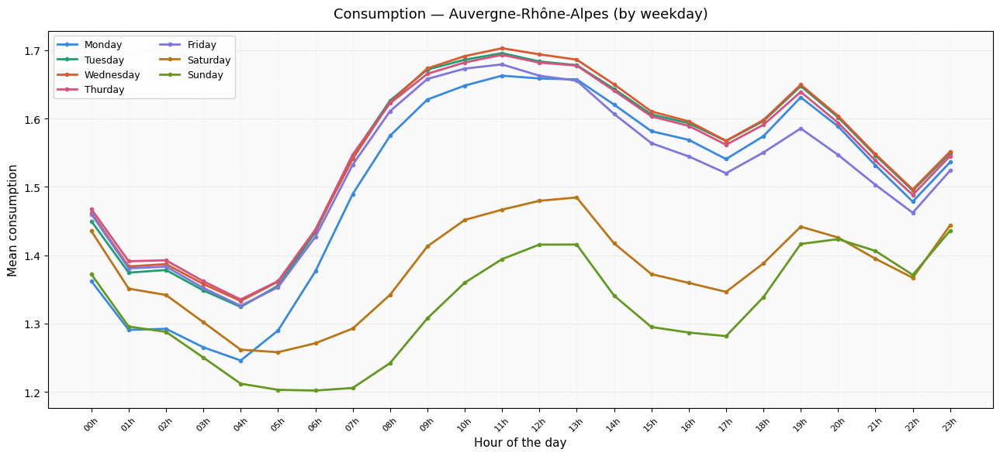

Sauvegardé : graphics/conso/hour_weekday_Bourgogne-Franche-Comté.pdf


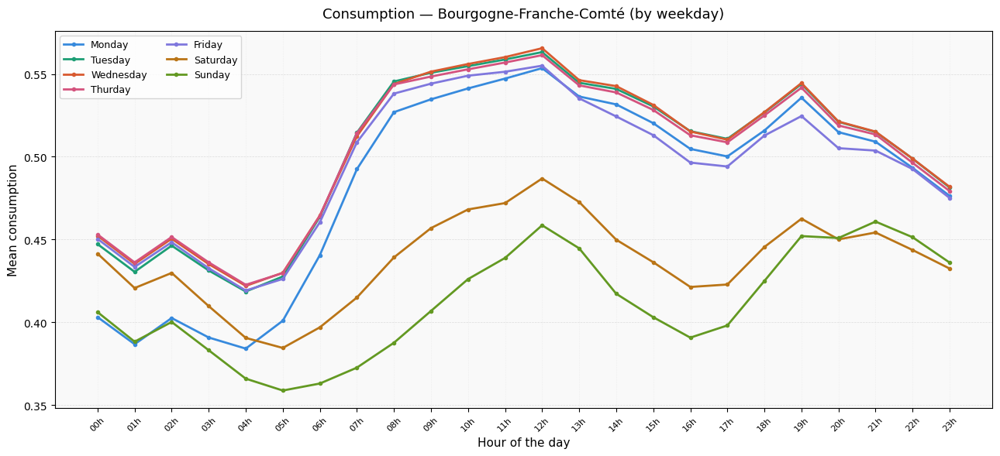

Sauvegardé : graphics/conso/hour_weekday_Bretagne.pdf


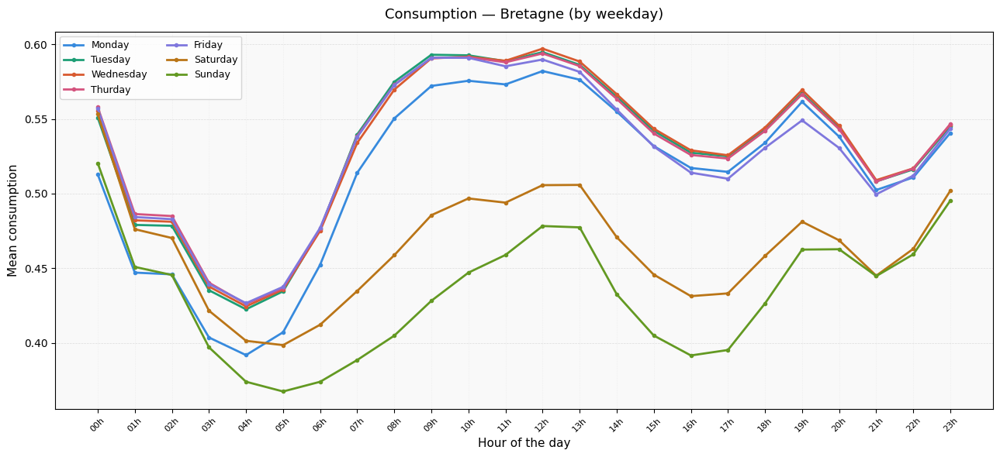

Sauvegardé : graphics/conso/hour_weekday_Centre-Val de Loire.pdf


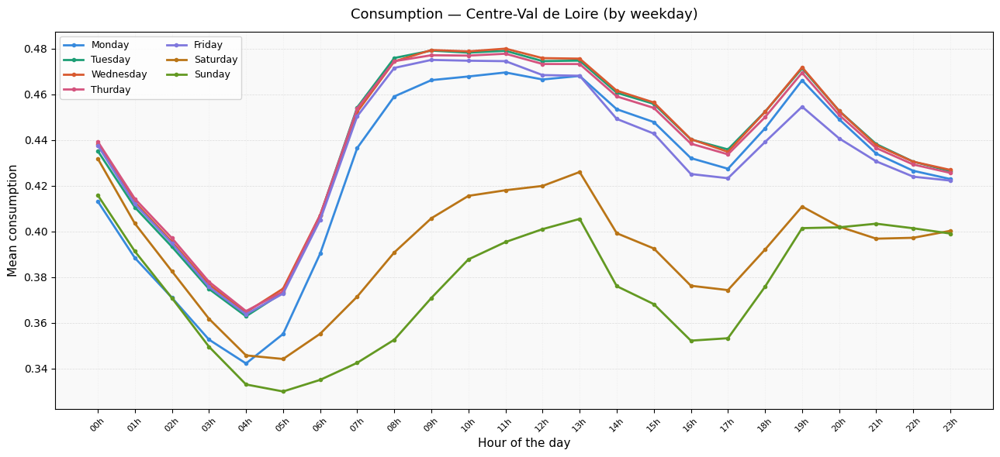

Sauvegardé : graphics/conso/hour_weekday_Grand Est.pdf


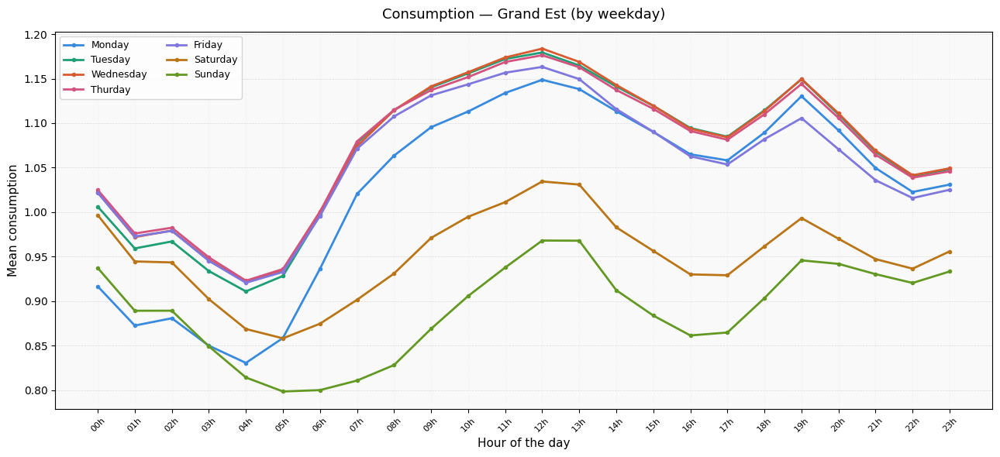

Sauvegardé : graphics/conso/hour_weekday_Hauts-de-France.pdf


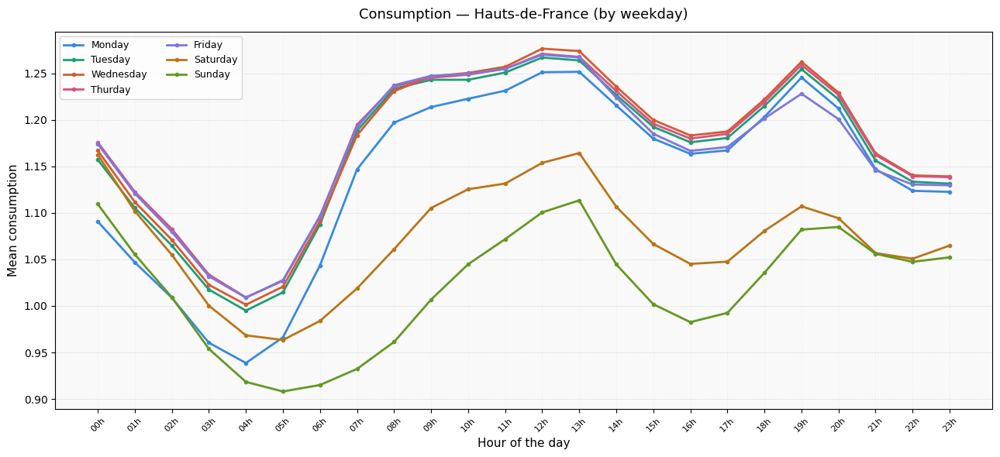

Sauvegardé : graphics/conso/hour_weekday_Ile-de-France.pdf


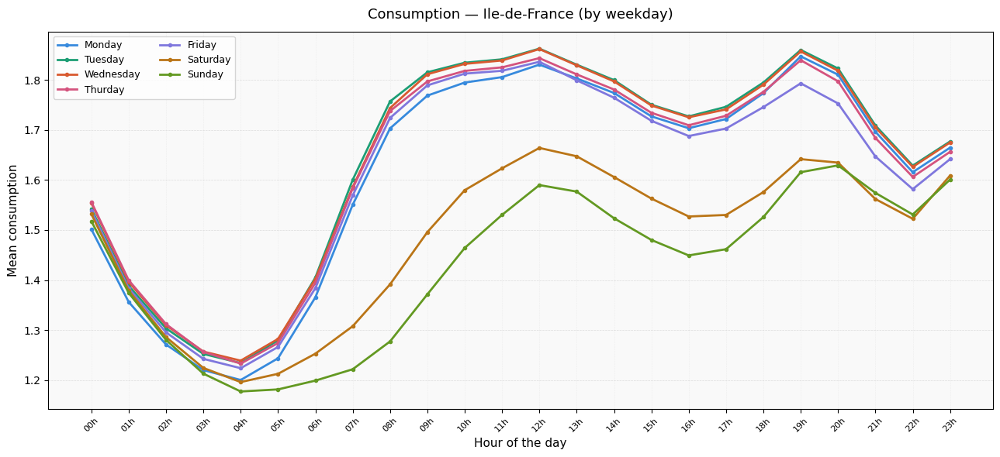

Sauvegardé : graphics/conso/hour_weekday_Nouvelle-Aquitaine.pdf


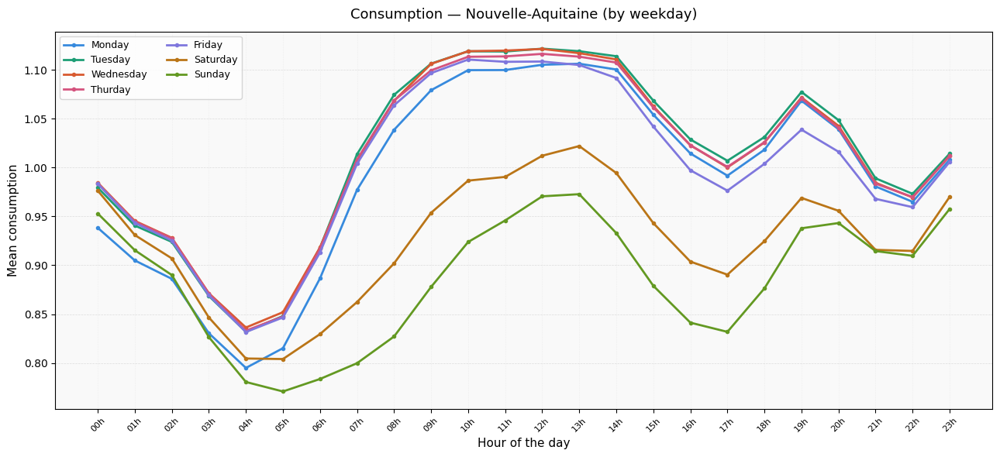

Sauvegardé : graphics/conso/hour_weekday_Normandie.pdf


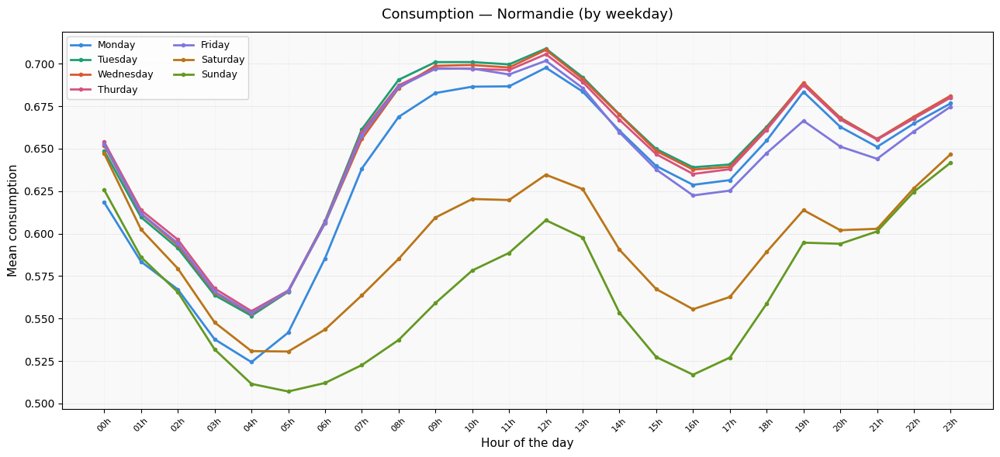

Sauvegardé : graphics/conso/hour_weekday_Occitanie.pdf


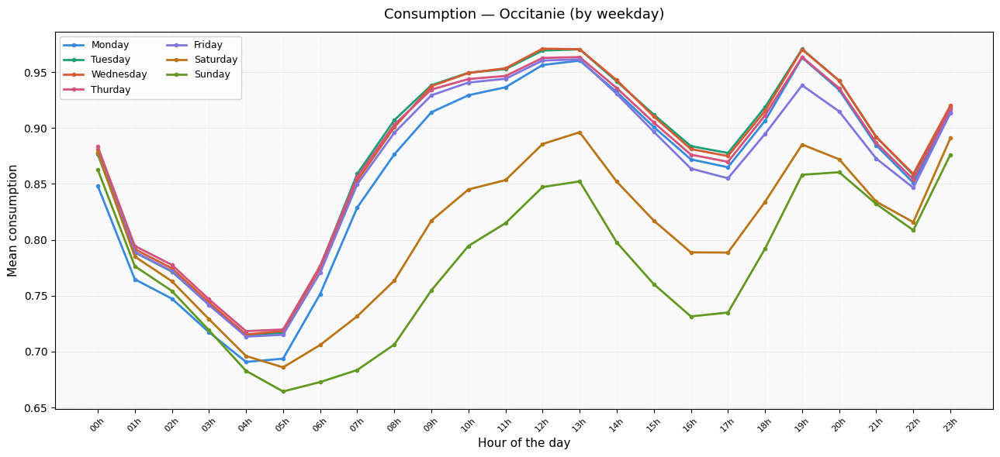

Sauvegardé : graphics/conso/hour_weekday_Pays de la Loire.pdf


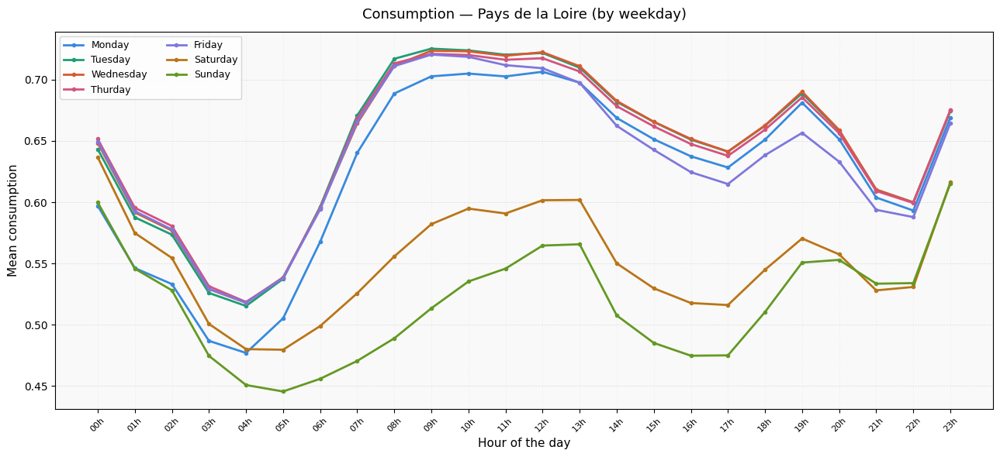

Sauvegardé : graphics/conso/hour_weekday_PACA.pdf


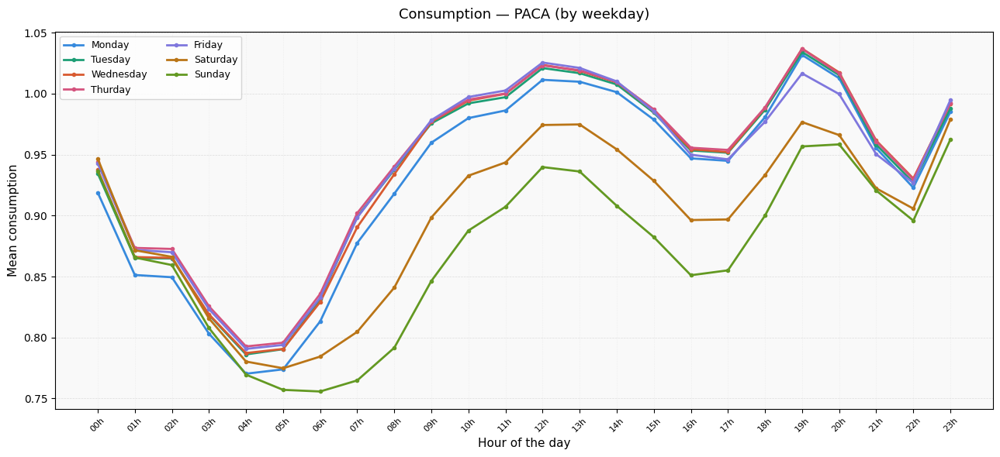

In [53]:
# Profil selon le jour de la semaine (lun-dim)
for region in regions_departements.keys():
    plotConsumptionByHour(region, groupBy="weekday",savePath=f"graphics/conso/hour_weekday_{region}.pdf")

# # Profil selon le mois — utile pour voir la saisonnalité horaire
# plotConsumptionByHour("PACA", groupBy="month")

# # Évolution du profil d'une année à l'autre
# plotConsumptionByHour("Ile-de-France", groupBy="year")

#### Coefs analysis

In [80]:
def getFeatureImportance(pipeline, 
                         X_sample: np.ndarray,
                         ) -> tuple:
    
    # Get the estimator type (LinearRegression, Ridge, DecisionTreeRegressor, etc.)
    estimatorName = None
    estimatorCoefs = None
    estimatorImportances = None
    
    # Try to get coefficients (Linear models)
    if hasattr(pipeline, "named_steps"):
        for name, step in pipeline.named_steps.items():
            if hasattr(step, "coef_"):
                estimatorName = name
                estimatorCoefs = step.coef_
                break
            elif hasattr(step, "feature_importances_"):
                estimatorName = name
                estimatorImportances = step.feature_importances_
                break
    
    if estimatorCoefs is None and estimatorImportances is None:
        raise ValueError("Pipeline does not contain a model with coef_ or feature_importances_")
    
    # Get feature names through transformations
    featureNames = getFeatureNames(pipeline, X_sample)
    
    # Calculate importance (absolute normalized coefficients for linear models)
    if estimatorCoefs is not None:
        coefs = estimatorCoefs[0] if estimatorCoefs.ndim > 1 else estimatorCoefs
        importanceScores = np.abs(coefs) / np.linalg.norm(coefs)
    else:
        importanceScores = estimatorImportances / np.sum(estimatorImportances)
    
    # Sort by importance
    topIndices = np.argsort(importanceScores)[::-1]
    
    topFeatureNames = [featureNames[i] for i in topIndices]
    topImportances = importanceScores[topIndices]
    
    return topFeatureNames, topImportances, estimatorName


def getFeatureNames(pipeline, X_sample: np.ndarray) -> list:
    
    featureNames = None
    currentData = X_sample
    
    for name, step in pipeline.named_steps.items():
        # print(step,featureNames)
        # Skip estimators that don't transform
        if name in ["linReg", "ridge", "decTree", "AdaBoostTree"]:
            # print(step.n_features_in_)
            break
        
        # Apply transformation
        currentData = step.fit_transform(currentData) if not hasattr(step, "transform") or \
                      not hasattr(pipeline.named_steps[list(pipeline.named_steps.keys())[
                          list(pipeline.named_steps.keys()).index(name) - 1]], "fit_transform") \
                      else step.transform(currentData)
        
        # Try to get feature names from the step
        if hasattr(step, "get_feature_names_out"):
            try:
                featureNames = step.get_feature_names_out(featureNames)
            except:
                featureNames = step.get_feature_names_out()
        elif name == "sincos":
            featureNames  = []
            for name, transformation,oldName in step.ct.transformers_:
                if transformation=="drop":
                    continue
                if name == "remainder":
                    featureNames += oldName
                else:
                    featureNames.append(name)
            # featureNames = [name for name,transformation,_ in  if transformation != "drop"]
        
        else:
            # For other transformers, create generic names if needed
            if featureNames is None:
                featureNames = [f"feature_{i}" for i in range(currentData.shape[1])]
    
    # If no feature names found, create generic ones
    if featureNames is None or len(featureNames) != currentData.shape[1]:
        featureNames = [f"feature_{i}" for i in range(currentData.shape[1])]
    
    return list(featureNames)


def plotFeatureImportance(pipeline,
                          combinedDatas: list,
                          lastCons:int,
                          topN: int = 15,
                          onlyRegion:str = None,
                          figsize: tuple = (14, 8),
                          savePath: str = None,
                          aggregationMethod: str = "mean") -> None:
    allImportances = {}

    for region, combinedData in zip(regions_departements.keys(), combinedDatas):
        if onlyRegion and region!=onlyRegion:
            continue
        combinedData = addLastCons(combinedData, lastCons)
        Xtrain, yTrain, Xtest, yTest = getTestTrain(combinedData, "2022-01-01")
        pipeline.fit(Xtrain, yTrain)
        
        allFeatureNames, allImportances_region, _ = getFeatureImportance(pipeline, Xtrain)
        
        allImportances[region] = dict(zip(allFeatureNames, allImportances_region))
    
    # Create DataFrame with all regions' importances
    dfImportances = pd.DataFrame(allImportances).fillna(0)
    
    # Aggregate across regions
    if aggregationMethod == "mean":
        aggregatedImportances = dfImportances.mean(axis=1)
    elif aggregationMethod == "std":
        aggregatedImportances = dfImportances.std(axis=1)
    else:
        raise ValueError("aggregationMethod must be 'mean' or 'std'")
    
    # Get top N features
    topIndices = np.argsort(aggregatedImportances.values)[-topN:][::-1]
    topFeatureNames = aggregatedImportances.index[topIndices].tolist()
    topAggregated = aggregatedImportances.values[topIndices]
    topByRegion = dfImportances.loc[topFeatureNames].T
    # Plot grouped bar chart
    fig, ax = plt.subplots(figsize=figsize)
    
    x = np.arange(len(topFeatureNames))
    width = 0.065
    if onlyRegion:
        ax.bar(x, topByRegion.loc[onlyRegion], width*3, label=onlyRegion, alpha=0.85)
    else:
        for idx, region in enumerate(sorted(regions_departements.keys())):
            offset = (idx - len(regions_departements) / 2) * width
            ax.bar(x + offset, topByRegion.loc[region], width, label=region, alpha=0.85)
        ax.plot(x, topAggregated, color="red", marker="o", linewidth=2.5, markersize=7, 
                    label=f"Aggregated ({aggregationMethod})", zorder=10)
            
    
    ax.set_xlabel("Features", fontsize=13)
    ax.set_ylabel("Importance (normalized)", fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(topFeatureNames, rotation=45, ha="right", fontsize=12)
    ax.legend(loc="upper right", fontsize=11, ncol=2)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
    
    plt.show()

In [58]:
def compareFeatureImportance(pipelines: dict,
                             combinedDatas: list,
                             lastCons: int,
                             topN: int = 15,
                             figsize: tuple = (12, 6),
                             savePath: str = None) -> None:
    """
    Compare feature importance across multiple pipelines.
    
    Args:
        pipelines: Dictionary with pipeline names as keys and fitted pipelines as values
                   Example: {"LinearReg": linRegPipe, "Ridge": ridgePipe, "DecTree": treePipe}
        combinedDatas: List of combined data DataFrames for each region
        lastCons: Number of last consumptions to add
        topN: Number of top features to display (default: 15)
        figsize: Figure size as (width, height) tuple (default: (12, 6))
        savePath: Path to save the figure (optional)
        
    Returns:
        None - displays the plot
    """
    
    pipelineImportances = {}
    
    # Collect aggregated importances for each pipeline
    for pipelineName, pipeline in pipelines.items():
        allImportances = {}
        
        for region, combinedData in zip(regions_departements.keys(), combinedDatas):
            
            combinedData = addLastCons(combinedData, lastCons)
            Xtrain, yTrain, Xtest, yTest = getTestTrain(combinedData, "2022-01-01")
            pipeline.fit(Xtrain, yTrain)
            
            allFeatureNames, allImportances_region, _ = getFeatureImportance(pipeline, Xtrain)
            allImportances[region] = dict(zip(allFeatureNames, allImportances_region))
        
        # Aggregate across regions (mean)
        dfImportances = pd.DataFrame(allImportances).fillna(0)
        aggregatedImportances = dfImportances.mean(axis=1)
        pipelineImportances[pipelineName] = aggregatedImportances
    
    # Create comparison DataFrame
    dfComparison = pd.DataFrame(pipelineImportances)
    
    # Get top N features based on mean importance across all pipelines
    meanImportance = dfComparison.mean(axis=1)
    topIndices = np.argsort(meanImportance.values)[-topN:][::-1]
    topFeatures = meanImportance.index[topIndices].tolist()
    dfTop = dfComparison.loc[topFeatures]
    
    # Plot comparison
    fig, ax = plt.subplots(figsize=figsize)
    
    x = np.arange(len(topFeatures))
    width = 0.25
    
    for idx, pipelineName in enumerate(dfTop.columns):
        offset = (idx - len(dfTop.columns) / 2) * width + width / 2
        ax.bar(x + offset, dfTop[pipelineName], width, label=pipelineName, alpha=0.85)
    
    ax.set_xlabel("Features", fontsize=12)
    ax.set_ylabel("Importance (normalized)", fontsize=12)
    ax.set_title(f"Top {topN} Feature Importance Comparison", fontsize=13, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(topFeatures, rotation=45, ha="right", fontsize=10)
    ax.legend(loc="upper right", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
    
    plt.show()


def getFeatureImportanceComparison(pipelines: dict,
                                   combinedDatas: list,
                                   lastCons: int,
                                   topN: int = 15) -> pd.DataFrame:
    """
    Get feature importance comparison as a DataFrame without plotting.
    Useful for further analysis or custom visualization.
    
    Args:
        pipelines: Dictionary with pipeline names as keys and fitted pipelines as values
        combinedDatas: List of combined data DataFrames for each region
        lastCons: Number of last consumptions to add
        topN: Number of top features to display (default: 15)
        
    Returns:
        pd.DataFrame: DataFrame with top features as index and pipelines as columns
    """
    
    pipelineImportances = {}
    
    # Collect aggregated importances for each pipeline
    for pipelineName, pipeline in pipelines.items():
        allImportances = {}
        
        for region, combinedData in zip(regions_departements.keys(), combinedDatas):
            
            combinedData = addLastCons(combinedData, lastCons)
            Xtrain, yTrain, Xtest, yTest = getTestTrain(combinedData, "2022-01-01")
            pipeline.fit(Xtrain, yTrain)
            
            allFeatureNames, allImportances_region, _ = getFeatureImportance(pipeline, Xtrain)
            allImportances[region] = dict(zip(allFeatureNames, allImportances_region))
        
        # Aggregate across regions (mean)
        dfImportances = pd.DataFrame(allImportances).fillna(0)
        aggregatedImportances = dfImportances.mean(axis=1)
        pipelineImportances[pipelineName] = aggregatedImportances
    
    # Create comparison DataFrame
    dfComparison = pd.DataFrame(pipelineImportances)
    
    # Get top N features based on mean importance across all pipelines
    meanImportance = dfComparison.mean(axis=1)
    topIndices = np.argsort(meanImportance.values)[-topN:][::-1]
    
    return dfComparison.iloc[topIndices]

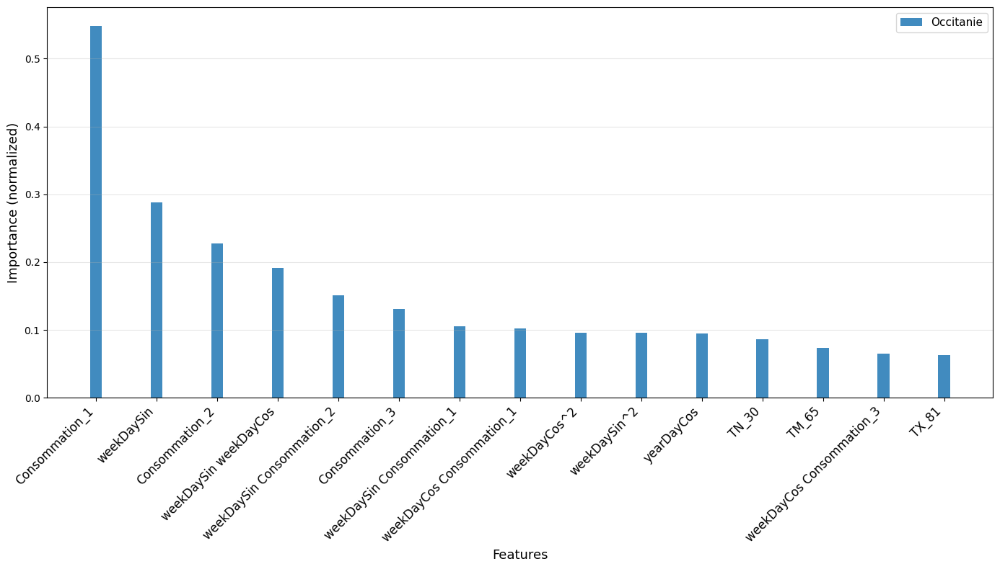

In [84]:
sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("scaler", StandardScaler()),
    ("pca",     PcaTransformer(nComp=-1)),

    ("poly",    PolynomialFeatures(degree=2)),

    ("linReg",  LinearRegression())
])

RidgePipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler",  StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("poly",    PolynomialFeatures(degree=2)),
        ("ridge",   Ridge(alpha=30))
    ])

RidgePipe2 = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler",  StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("poly",    PolynomialFeatures(degree=3)),
        ("ridge",   Ridge(alpha=10000))
    ])

TreePipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler",  StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("decTree", DecisionTreeRegressor(max_depth=11,max_features=None)),
    ])


combinedDatas = getCombinedDatas("ByDay","Dep")

    # print(sincosLinRegPipe.score(Xtest,yTest))
# print(sincosLinRegPipe['sincos'].ct.transformers_)
# coefs = sincosLinRegPipe["linReg"].coef_[0] / np.linalg.norm(sincosLinRegPipe["linReg"].coef_[0])
# print(preprocess.fit_transform(Xtrain))
# print(sincosLinRegPipe["poly"].get_feature_names_out()[np.argmax(coefs)])
# plotFeatureImportance(RidgePipe, combinedDatas, lastCons=11, topN=10)
# pipelines = {
#     "Ridge_100": RidgePipe,
#     "Ridge_10000": RidgePipe2,
#     # "DecTree": treePipe
# }

# compareFeatureImportance(pipelines, combinedDatas, lastCons=11, topN=15)
# plotFeatureImportance(RidgePipe, combinedDatas, lastCons=3, topN=50,savePath="graphics/coefs/coefs_Dep_ByDay_Ridge.pdf")
plotFeatureImportance(RidgePipe, combinedDatas, lastCons=3, topN=15,onlyRegion="Occitanie",savePath="coef_Dep_ByDay_Ridge_Occ.pdf")
# plotFeatureImportance(sincosLinRegPipe, Xtrain, topN=15,savePath="graphics/coefs/coefs_Region_ByDay_linReg.pdf")

In [ ]:
combinedDatas = getCombinedDatas("ByDay","Region")

plotFeatureImportance(RidgePipe, combinedDatas, topN=10,savePath="graphics/coefs/coefs_Region_ByDay_ridge.pdf")

#### Prediction

In [ ]:
def plotPredictions(pipeline,
                    combinedData: pd.DataFrame,
                    separatingDate: str,
                    lastCons: int,
                    startDate: str = None,
                    endDate: str = None,
                    figsize: tuple = (16, 6),
                    savePath: str = None) -> dict:
    """
    Train a pipeline on train data and plot predictions vs actual values on test data.
    
    Args:
        pipeline: Fitted sklearn Pipeline
        combinedData: Combined DataFrame with features and target
        separatingDate: Date to split train/test (YYYY-MM-DD format)
        lastCons: Number of last consumptions to add
        startDate: Start date for plot display (YYYY-MM-DD format, optional)
        endDate: End date for plot display (YYYY-MM-DD format, optional)
        figsize: Figure size as (width, height) tuple (default: (16, 6))
        savePath: Path to save the figure (optional)
        
    Returns:
        dict: Dictionary with scores and predictions info
    """
    
    # Prepare data
    combinedData = addLastCons(combinedData, lastCons)
    Xtrain, yTrain, Xtest, yTest = getTestTrain(combinedData, separatingDate)
    
    # Train pipeline
    pipeline.fit(Xtrain, yTrain)
    
    # Get predictions
    yPredTrain = pipeline.predict(Xtrain)
    yPredTest = pipeline.predict(Xtest)
    
    # Calculate scores
    trainScore = pipeline.score(Xtrain, yTrain)
    testScore = pipeline.score(Xtest, yTest)
    
    # Get test dates for x-axis
    if "Date" in combinedData.columns:
        testDates = combinedData.loc[Xtest.index][["Date"]].values
    else:
        testDates = combinedData.loc[Xtest.index,"dateTime"]
    # print(testDates)
    
    # Filter by date range if provided
    if startDate is not None and endDate is not None:
        startDateTime = pd.to_datetime(startDate)
        endDateTime = pd.to_datetime(endDate)
        
        mask = (testDates >= startDateTime) & (testDates <= endDateTime)
        mask = mask[:,0]
        # print()
        testDates_filtered = testDates[mask]
        yTest_filtered = yTest[mask].values
        yPredTest_filtered = yPredTest[mask]
    else:
        testDates_filtered = testDates
        yTest_filtered = yTest.values
        yPredTest_filtered = yPredTest
    
    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    
    ax.plot(testDates_filtered, yTest_filtered, label="Actual", color="blue", linewidth=2, alpha=0.7)
    ax.plot(testDates_filtered, yPredTest_filtered, label="Predicted", color="red", linewidth=2, alpha=0.7)
    
    ax.set_xlabel("Date", fontsize=14)
    ax.set_ylabel("Value", fontsize=14)
    # ax.set_title(f"Predictions vs Actual (Train Score: {trainScore:.4f}, Test Score: {testScore:.4f})", 
    #              fontsize=13, fontweight="bold")
    ax.legend(loc="upper right", fontsize=17)
    ax.grid(True, alpha=0.3)
    
    # Rotate x-axis labels for better readability
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
    
    plt.show()
    
    # Return scores info
    return {
        "trainScore": trainScore,
        "testScore": testScore,
        "trainMAE": np.mean(np.abs(yTrain.values - yPredTrain)),
        "testMAE": np.mean(np.abs(yTest.values - yPredTest)),
        "trainRMSE": np.sqrt(np.mean((yTrain.values - yPredTrain) ** 2)),
        "testRMSE": np.sqrt(np.mean((yTest.values - yPredTest) ** 2)),
    }


def plotPredictionsMultiRegion(pipeline,
                               combinedDatas: list,
                               separatingDate: str,
                               lastCons: int,
                               startDate: str = None,
                               endDate: str = None,
                               figsize: tuple = (16, 8),
                               savePath: str = None) -> dict:
    """
    Train pipeline for each region and plot predictions vs actual values.
    
    Args:
        pipeline: Fitted sklearn Pipeline
        combinedDatas: List of combined data DataFrames for each region
        separatingDate: Date to split train/test (YYYY-MM-DD format)
        lastCons: Number of last consumptions to add
        startDate: Start date for plot display (YYYY-MM-DD format, optional)
        endDate: End date for plot display (YYYY-MM-DD format, optional)
        figsize: Figure size as (width, height) tuple (default: (16, 8))
        savePath: Path to save the figure (optional)
        
    Returns:
        dict: Dictionary with scores for each region
    """
    
    allScores = {}
    fig, axes = plt.subplots(3, 4, figsize=figsize)
    axes = axes.flatten()
    
    for idx, (region, combinedData) in enumerate(zip(regions_departements.keys(), combinedDatas)):
        
        # Prepare data
        combinedData = addLastCons(combinedData, lastCons)
        Xtrain, yTrain, Xtest, yTest = getTestTrain(combinedData, separatingDate)
        
        # Train pipeline
        pipeline.fit(Xtrain, yTrain)
        
        # Get predictions
        yPredTest = pipeline.predict(Xtest)
        
        # Calculate scores
        testScore = pipeline.score(Xtest, yTest)
        trainScore = pipeline.score(Xtrain, yTrain)
        
        allScores[region] = {
            "trainScore": trainScore,
            "testScore": testScore,
        }
        
        # Get test dates for x-axis
        if "Date" in combinedData.columns:
            testDates = combinedData.loc[Xtest.index,"Date"]
        else:
            testDates = combinedData.loc[Xtest.index,"dateTime"]
        print(testDates)
        # Filter by date range if provided
        if startDate is not None and endDate is not None:
            startDateTime = pd.to_datetime(startDate)
            endDateTime = pd.to_datetime(endDate)
            
            mask = (testDates >= startDateTime) & (testDates <= endDateTime)
            testDates_filtered = testDates[mask]
            yTest_filtered = yTest.iloc[mask].values
            yPredTest_filtered = yPredTest[mask]
        else:
            testDates_filtered = testDates
            yTest_filtered = yTest.values
            yPredTest_filtered = yPredTest
        
        # Plot on subplot
        ax = axes[idx]
        ax.plot(testDates_filtered, yTest_filtered, label="Actual", color="blue", linewidth=1.5, alpha=0.7)
        ax.plot(testDates_filtered, yPredTest_filtered, label="Predicted", color="red", linewidth=1.5, alpha=0.7)
        
        ax.set_title(f"{region}\n(Train: {trainScore:.3f}, Test: {testScore:.3f})", fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.tick_params(axis="x", rotation=45, labelsize=8)
    
    # Remove empty subplots
    for idx in range(len(regions_departements), len(axes)):
        fig.delaxes(axes[idx])
    
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", fontsize=11)
    
    plt.tight_layout()
    
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
    
    plt.show()
    
    return allScores

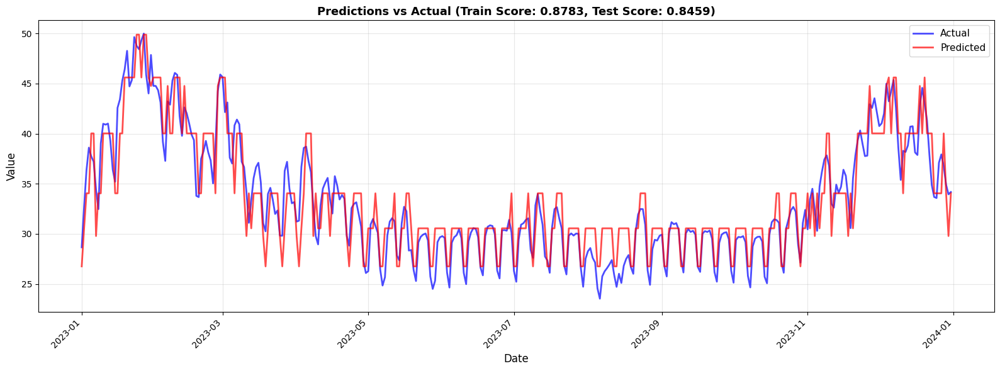

In [90]:


TreePipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("pca",     PcaTransformer(nComp=-1)),
        ("decTree", DecisionTreeRegressor(max_depth=3)),
    ])
combinedDatas = getCombinedDatas("ByDay","Region")
# allScores = plotPredictionsMultiRegion(
#     TreePipe,
#     combinedDatas,
#     separatingDate="2023-01-01",
#     lastCons=3
#     # startDate="2023-06-01",
#     # endDate="2023-12-31"
# )
scores = plotPredictions(
    TreePipe, 
    combinedDatas[0], 
    separatingDate="2023-01-01",
    lastCons=3,
    startDate="2023-01-01",
    endDate="2023-12-31",
    savePath="graphics/predict/predict_ByDay_Region_decTree3.pdf"
)

#### PCA IMPACT

In [106]:
def generatePcaImpactSummary(modelNames: list,
                             deltas: list,
                             scale: str = "Region",
                             level: int = 1) -> pd.DataFrame:
    """
    Generate a summary table showing the impact of PCA on model performances.
    
    Args:
        modelNames: List of model names (e.g., ["polyReg", "ridgeReg", "decTree", "AdaBoostDecTree"])
        deltas: List of deltas (e.g., ["ByDay", "ByHour"])
        scale: Scale to use (default: "Region")
        level: Level parameter (default: 1)
        
    Returns:
        pd.DataFrame: Summary table with MultiIndex (Model, Delta, PCA Precision) and 
                     columns (Test Score, Train Score, Fit Time, Test Time)
    """
    
    summaryData = []
    pcaConfig = loadPcaComponents()
    
    for modelName in modelNames:
        for delta in deltas:
            pcaPrecisionMapping = mapPcaComponentsToPrecision(pcaConfig, delta, scale)
            print(f"Processing {modelName} - {delta}")
            
            try:
                # Load grid search results
                gridResults = loadGridSearchResults(
                    getGridSearchResultsName(delta, scale, modelName, level)
                )
            except FileNotFoundError:
                print(f"  Warning: File not found for {modelName} - {delta}")
                continue
            
            for precision in ["0.01", "0.005"]:
                
                try:
                    df = dictToPandasResult(gridResults, delta, scale, 
                                          filters={"pca__precision": [precision]}, 
                                          onlyMean=True)
                    
                    print(f"DEBUG - Returned df type: {type(df)}")
                    print(f"DEBUG - Returned df:\n{df}")
                    print(f"DEBUG - df columns: {df.columns.tolist()}")
                    print(f"DEBUG - Looking for: ('Moyenne', 'meanTestScore')")
                    # Check if DataFrame is empty
                    if df.empty:
                        print(f"    No data for precision {precision}")
                        continue
                    
                    # Get the best index based on Moyenne/meanTestScore
                    if ("Moyenne", "meanTestScore") not in df.columns:
                        print(f"    Column not found for precision {precision}, available: {df.columns.tolist()}")
                        continue
                    
                    bestIdx = df[("Moyenne", "meanTestScore")].idxmax()
                    bestValue = df.loc[bestIdx]
                    
                    summaryData.append({
                        "model": modelName,
                        "delta": delta,
                        "pca__precision": precision,
                        "testScore": bestValue[("Moyenne", "meanTestScore")],
                        "trainScore": bestValue[("Moyenne", "meanTrainScore")],
                        "fitTime": bestValue[("Moyenne", "meanFitTime")],
                        "testTime": bestValue[("Moyenne", "meanTestTime")],
                    })
                    
                except Exception as e:
                    print(f"    Error processing precision {precision}: {str(e)}")
                    continue
    
    if not summaryData:
        print("No data collected")
        return pd.DataFrame()
    
    # Create DataFrame with MultiIndex
    dfFinal = pd.DataFrame(summaryData)
    dfFinal = dfFinal.set_index(["model", "delta", "pca__precision"])
    
    # Select and reorder columns
    dfFinal = dfFinal[["testScore", "trainScore", "fitTime", "testTime"]]
    
    # Sort by index for better readability
    dfFinal = dfFinal.sort_index()
    
    return dfFinal


def displayPcaImpactSummary(modelNames: list,
                            deltas: list,
                            scale: str = "Region",
                            level: int = 1):
    """
    Display PCA impact summary table with formatting.
    
    Args:
        modelNames: List of model names
        deltas: List of deltas
        scale: Scale to use (default: "Region")
        level: Level parameter (default: 1)
        
    Returns:
        pd.io.formats.style.Styler: Styled DataFrame
    """
    
    dfSummary = generatePcaImpactSummary(modelNames, deltas, scale, level)
    
    if dfSummary.empty:
        return None
    
    return dfSummary.style \
        .highlight_max(color="green", axis=0, subset=["testScore", "trainScore"]) \
        .highlight_min(color="yellow", axis=0, subset=["fitTime", "testTime"]) \
        .format("{:.5f}") \
        .set_caption("PCA Impact on Model Performances (Level 1)")

In [107]:
modelNames = [ "ridgeReg", "decTree", "AdaBoostDecTree","polyReg",]
deltas = ["ByDay", "ByHour"]

# Générer le tableau
summary = generatePcaImpactSummary(modelNames, deltas)
displayPcaImpactSummary(modelNames, deltas)

Processing ridgeReg - ByDay
      poly__degree  ridge__alpha  nbLstCons                region  \
0                1      0.000100          0  Auvergne-Rhône-Alpes   
1                1      0.000599          0  Auvergne-Rhône-Alpes   
2                1      0.003594          0  Auvergne-Rhône-Alpes   
3                1      0.021544          0  Auvergne-Rhône-Alpes   
4                1      0.129155          0  Auvergne-Rhône-Alpes   
...            ...           ...        ...                   ...   
4315             3      0.774264         11                  PACA   
4316             3      4.641589         11                  PACA   
4317             3     27.825594         11                  PACA   
4318             3    166.810054         11                  PACA   
4319             3   1000.000000         11                  PACA   

     pca__precision  meanTestScore  meanTrainScore  meanFitTime  meanTestTime  
0                 0       0.824058        0.865941     0.030217

In [292]:
to_tabularx(displayPcaImpactSummary(modelNames, deltas))

Processing polyReg - ByDay
Processing polyReg - ByHour
Processing ridgeReg - ByDay
Processing ridgeReg - ByHour
Processing decTree - ByDay
Processing decTree - ByHour
Processing AdaBoostDecTree - ByDay
Processing AdaBoostDecTree - ByHour
\begin{table}
\caption{PCA Impact on Model Performances (Level 1)}
\begin{tabularx}{\textwidth}{lllrrrr}
\toprule
 &  &  & testScore & trainScore & fitTime & testTime \\
model & delta & pca__precision &  &  &  &  \\
\midrule
\multirow[c]{2}{*}{AdaBoostDecTree} & ByDay & 0 & 0.9721 & 0.9996 & 16.3253 & 0.0907 \\
 & ByHour & 0 & 0.9868 & {\cellcolor{cyan}} 0.9998 & 198.7064 & 0.9848 \\
\multirow[c]{2}{*}{decTree} & ByDay & 0 & 0.9506 & 0.9760 & {\cellcolor{orange}} 0.0379 & {\cellcolor{magenta}} 0.0121 \\
 & ByHour & 0 & 0.9777 & 0.9961 & 0.3939 & 0.0285 \\
\multirow[c]{2}{*}{polyReg} & ByDay & 0 & 0.9753 & 0.9818 & 0.1867 & 0.0382 \\
 & ByHour & 0 & 0.9807 & 0.9948 & 1.2358 & 0.1224 \\
\multirow[c]{2}{*}{ridgeReg} & ByDay & 0 & 0.9760 & 0.9835 & 0.4802 

## MERDE

In [83]:
RidgePipe = Pipeline([
        ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
        ("scaler",  StandardScaler()),
        ("pca",     PcaTransformer(nComp=-1)),
        ("poly",    PolynomialFeatures(degree=3)),
        ("ridge",   Ridge(alpha=1000))
    ])


combinedDatas = getCombinedDatas("ByDay","Region")
combinedData =  addLastCons(combinedDatas[0],11)
Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedData,"2022-01-01")
RidgePipe.fit(Xtrain,yTrain)
print(RidgePipe.score(Xtest,yTest))
print(RidgePipe.score(Xtrain,yTrain))

0.9647327584705752
0.9799548837776354


In [33]:
def migrateGridSearchFormat(modelName: Literal["polyReg", "ridgeReg", "decTree", "AdaBoostDecTree"],
                            delta: Literal["ByHour", "ByDay"],
                            scale: Literal["Region", "Dep"],
                            level: int = 1) -> None:
    """
    Convert old grid search JSON format to new format with bestIndex.
    Handles both old format (with bestScore/bestParams/meanScore) and new format (with bestIndex).
    
    Args:
        modelName: Name of the model
        delta: Time delta (ByHour or ByDay)
        scale: Scale (Region or Dep)
        level: Level parameter
        
    Returns:
        None - Saves the converted file in place
    """
    filepath = getGridSearchResultsName(delta, scale, modelName, level)
    
    try:
        oldData = loadGridSearchResults(filepath)
    except FileNotFoundError:
        print(f"File not found: {filepath}")
        return
    
    # Check if already in new format
    if oldData and isinstance(oldData.get(list(oldData.keys())[0]), list):
        firstEntry = oldData[list(oldData.keys())[0]][0]
        if "bestIndex" in firstEntry:
            print(f"File {filepath} is already in new format")
            return
    
    convertedData = {}
    
    for region, entries in oldData.items():
        convertedData[region] = []
        
        for entry in entries:
            convertedAllResults = []
            bestIndex = None
            bestScore = entry.get("bestScore", -np.inf)
            
            # Convert allResults
            for idx, result in enumerate(entry.get("allResults", [])):
                convertedResult = {
                    "params": result.get("params", {}),
                    "meanTestScore": result.get("meanScore", np.nan),
                    "meanTrainScore": np.nan,
                    "meanFitTime": np.nan,
                    "meanTestTime": np.nan
                }
                
                # Update bestIndex if this is the best result
                if bestScore != -np.inf and abs(result.get("meanScore", -np.inf) - bestScore) < 1e-9:
                    bestIndex = idx
                
                convertedAllResults.append(convertedResult)
            
            convertedEntry = {
                "bestIndex": bestIndex if bestIndex is not None else 0,
                "allResults": convertedAllResults
            }
            
            convertedData[region].append(convertedEntry)
    
    # Save converted data
    saveGridSearchResults(filepath, convertedData)
    print(f"Migrated {filepath} to new format")

In [34]:
modelsName = ["polyReg","ridgeReg","decTree","AdaBoostDecTree"]
for model in modelsName:
    for level in [1,2]:
        for delta in ["ByDay","ByHour"]:
            for scale in ["Region","Dep"]:
                migrateGridSearchFormat(model, delta, scale, level)

    Result saved in gridSearchResult\gridsearch_Region_ByDay_polyReg_results_1.json
Migrated gridSearchResult\gridsearch_Region_ByDay_polyReg_results_1.json to new format
    Result saved in gridSearchResult\gridsearch_Dep_ByDay_polyReg_results_1.json
Migrated gridSearchResult\gridsearch_Dep_ByDay_polyReg_results_1.json to new format
    Result saved in gridSearchResult\gridsearch_Region_ByHour_polyReg_results_1.json
Migrated gridSearchResult\gridsearch_Region_ByHour_polyReg_results_1.json to new format
File not found: gridSearchResult\gridsearch_Dep_ByHour_polyReg_results_1.json
File not found: gridSearchResult\gridsearch_Region_ByDay_polyReg_results_2.json
File not found: gridSearchResult\gridsearch_Dep_ByDay_polyReg_results_2.json
File not found: gridSearchResult\gridsearch_Region_ByHour_polyReg_results_2.json
File not found: gridSearchResult\gridsearch_Dep_ByHour_polyReg_results_2.json
    Result saved in gridSearchResult\gridsearch_Region_ByDay_ridgeReg_results_1.json
Migrated gri

In [51]:
class IndependentPolyFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, degree=2):
        self.degree = degree
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X, y=None):
        powers = [X ** d for d in range(1, self.degree + 1)]
        return np.hstack(powers)

In [83]:
#* Optimizing Poly degree after PCA

sincosPcaLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("pca", PcaTransformer(nComp=53)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])

transformPipe = sincosPcaLinRegPipe[:3]

collectedInformations = {}
for combinedData,(region,deps) in zip(combinedDatasDep,regions_departements.items()):
    
    combineLastDay = addLastCons(combinedData,27)
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-01-01")
    # print(Xtest.shape)
    # Xtrain.drop(['dateTime'],axis=1,inplace=True)
    # pca.fit(Xtrain)
    XtrainTransformed = transformPipe.fit_transform(Xtrain)
    XtestTransformed = transformPipe.transform(Xtest)

    print(region,XtrainTransformed.shape[1])
    informationRatios = []
    for d in range(1,4):
        fitPipe = Pipeline([           
            ("poly",   PolynomialFeatures(degree=d,interaction_only=True,include_bias=False)),
            # ("poly",   IndependentPolyFeatures(degree=d)), #* Pas ouf les scores
            ("linReg", LinearRegression())
        ])

        fitPipe.fit(XtrainTransformed,yTrain)
        score = fitPipe.score(XtestTransformed,yTest)
        print(f"d:{d}, score : {score}")
        
        informationRatios.append(score)
        if d not in collectedInformations:
            collectedInformations[d] = []
        collectedInformations[d].append(score)

    plt.plot(list(range(1,6)),informationRatios,label=region)
varDfPoly = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))
plt.legend()
plt.show()

Auvergne-Rhône-Alpes 53
d:1, score : 0.8566959890796844
d:2, score : 0.8704489885596829


KeyboardInterrupt: 

In [ ]:

sincosPcaLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("pca", PcaTransformer(nComp=53)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])

scores = {}
for combinedData,(region,deps) in zip(combinedDatasDep,regions_departements.items()):

    combineLastDay = addLastCons(combinedData,27)

    # combineWDays = addDays(combineLastDay)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-01-01")
    # print(Xtrain.columns)
    # print(Xtrain.shape, Xtest.shape)
    sincosPcaLinRegPipe.fit(Xtrain,yTrain)


    scores[region] = sincosPcaLinRegPipe.score(Xtest, yTest)
    print(region, " - score : ", scores[region])
dfResult = pd.DataFrame.from_dict(scores,orient="index")

Auvergne-Rhône-Alpes  - score :  0.8722335188917267
Bourgogne-Franche-Comté  - score :  0.8291675955548464
Bretagne  - score :  0.9756613125912437
Centre-Val de Loire  - score :  0.8929969810879173
Grand Est  - score :  0.8262343754753955
Hauts-de-France  - score :  0.9490974808346675
Île-de-France  - score :  0.860878067097171
Nouvelle-Aquitaine  - score :  0.8657415836943855
Normandie  - score :  0.9460414119888244
Occitanie  - score :  0.8405074455567201
Pays de la Loire  - score :  0.8815840096264624
PACA  - score :  0.9390924910487739


ValueError: If using all scalar values, you must pass an index

In [82]:
dfResult

,by Dep HOUR
Auvergne-Rhône-Alpes,0.872234
Bourgogne-Franche-Comté,0.829168
Bretagne,0.975661
Centre-Val de Loire,0.892997
Grand Est,0.826234
Hauts-de-France,0.949097
Île-de-France,0.860878
Nouvelle-Aquitaine,0.865742
Normandie,0.946041
Occitanie,0.840507


**Departement par jour**

In [22]:
#* Combine Data
combinedDatasDepDay = []
for region,deps in regions_departements.items():

    # combinedData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))

    energyData = getEnrData(region)
    dateMin = energyData["dateTime"].dt.date.min()
    dateMax = energyData["dateTime"].dt.date.max()
    # print(energyData)
    departementsData = []
    for dep in deps: 

        depDf = getMetData("ByDay",dep)
        # depDf["dateTime"] = pd.to_datetime(depDf["DATE"].astype(str) + depDf["HOUR"].astype(str).str.zfill(2), format="%Y-%m-%d%H")
        # print(dep)
        # print(depDf.columns)
        if 'NUM_POSTE' in depDf.columns:
            depDf.drop(["NUM_POSTE"],axis=1,inplace=True)
        depDf.drop(["FF2M"],axis=1,inplace=True)
        depDf["DATE"] = pd.to_datetime(depDf["DATE"])
        depDf = depDf[(depDf["DATE"].dt.date >= dateMin) & (depDf["DATE"].dt.date <= dateMax)]

        depAverage = depDf.groupby(["DATE"]).mean() #* moyenne sur les heures
        depAverage.columns = [f"{col}_{dep}" for col in depAverage.columns]
        departementsData.append(depAverage)


    departementUnited = pd.concat(departementsData, axis=1, join="inner").reset_index(names=['DATE'])
    # print(departementUnited.head(50))

    combinedData = combineEnrAndMet(energyData,departementUnited)
    
    print(region, combinedData.shape)
    # print(combinedData)
    combinedDatasDepDay.append(combinedData)

Auvergne-Rhône-Alpes (4017, 110)
Bourgogne-Franche-Comté (4017, 74)
Bretagne (4017, 38)
Centre-Val de Loire (4017, 56)
Grand Est (4017, 92)
Hauts-de-France (4017, 47)
Île-de-France (3994, 74)
Nouvelle-Aquitaine (4017, 110)
Normandie (4017, 47)
Occitanie (4017, 119)
Pays de la Loire (4017, 47)
PACA (4017, 56)


In [71]:
fill_rates = []

for combinedData,(region,deps) in zip(combinedDatasDepDay,regions_departements.items()):
    # print(combinedData.columns)
    fill_rate = combinedData.notna().mean() * 100  
    fill_rates.append(fill_rate)

summary = pd.DataFrame(fill_rates).mean().round(2).sort_values()
summary.name = "Remplissage moyen (%)"

with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
    print(summary[summary<100])

Series([], Name: Remplissage moyen (%), dtype: float64)


In [23]:
#* Fill mising data
combinedDatasDepDay2 = []
for combinedData,(region,deps) in zip(combinedDatasDepDay,regions_departements.items()):
    # print(combinedData['Consommation'].nunique())
    # On récupère les noms de colonnes de base (sans le suffixe département)
    base_cols = set(col.rsplit("_", 1)[0] for col in combinedData.columns if "_" in col)

    for base_col in base_cols:
        # On récupère toutes les colonnes correspondant à cette mesure
        matching_cols = [col for col in combinedData.columns if col.rsplit("_", 1)[0] == base_col]
        
        # Moyenne uniquement sur ces colonnes
        col_mean = combinedData[matching_cols].mean(axis=1)
        # print(matching_cols)
        # On remplace les NaN uniquement pour ces colonnes
        combinedData[matching_cols] = combinedData[matching_cols].apply(lambda col: col.fillna(col_mean))
        
    combinedDatasDepDay2.append(combinedData)

combinedDatasDepDay = combinedDatasDepDay2.copy()

Auvergne-Rhône-Alpes : 
 25 / 50 - test score : -0.60446 | train score : 1.00000Bourgogne-Franche-Comté : 
 25 / 50 - test score : 0.21316 | train score : 1.000000Bretagne : 
 25 / 50 - test score : 0.88218 | train score : 0.99408Centre-Val de Loire : 
 25 / 50 - test score : -2.59337 | train score : 0.99978Grand Est : 
 25 / 50 - test score : -2.08554 | train score : 1.00000Hauts-de-France : 
 25 / 50 - test score : 0.66177 | train score : 0.99675Île-de-France : 
 25 / 50 - test score : -42.23148 | train score : 1.0000050Nouvelle-Aquitaine : 
 25 / 50 - test score : -3.30229 | train score : 1.00000Normandie : 
 25 / 50 - test score : 0.76307 | train score : 0.99748Occitanie : 
 25 / 50 - test score : -2.09622 | train score : 1.00000Pays de la Loire : 
 25 / 50 - test score : 0.71565 | train score : 0.99676PACA : 
 25 / 50 - test score : -4.06693 | train score : 0.99993

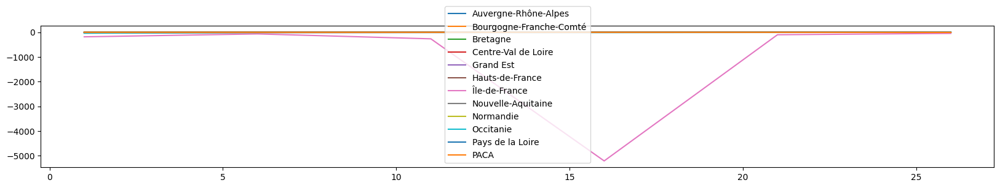

In [72]:
#* Optimizing the number of last consomation to consider
sincosLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])

scores = {}
collectedInformations ={}
for combinedData,(region,deps) in zip(combinedDatasDepDay,regions_departements.items()):
    informationRatios = []
    print(region+" : ")
    for lastCons in range(0,30,5):
        combinedDataCons = addLastCons(combinedData, lastCons)
        # print(combinedDataCons.head())

        Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedDataCons,"2023-01-01")
        # print(Xtrain.columns)
        # print(Xtrain.columns.tolist())
        # print(Xtrain.columns)
        # print(Xtrain.shape, Xtest.shape)
        sincosLinRegPipe.fit(Xtrain,yTrain)

        # scores[region] = sincosLinRegPipe.score(Xtest, yTest)

        # print(region, " - score : ", scores[region])

        score = sincosLinRegPipe.score(Xtest, yTest)
        print(f"\r {lastCons} / 50 - test score : {score:.5f} | train score : {sincosLinRegPipe.score(Xtrain, yTrain):.5f}",end='',flush=True)
        informationRatios.append(score)
        if lastCons not in collectedInformations:
            collectedInformations[lastCons] = []
        collectedInformations[lastCons].append(score)
        
    plt.plot(list(range(1,30,5)),informationRatios,label=region)
    
varLastConsDepDay = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))
plt.legend()
plt.show()

In [73]:
varLastConsDepDay

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Île-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA
0,-8.143656,-1.062736,0.926231,0.754692,-9.313721,0.587697,-181.418344,-29.829206,0.824051,-34.539991,0.814447,0.658375
5,-3.019613,-0.314779,0.959082,0.893572,-1.743070,0.912507,-63.726240,-14.986904,0.946130,-4.654140,0.927955,0.911894
10,-1.350870,-1.850108,0.944949,0.864774,-2.462222,0.903717,-262.186968,-6.558016,0.946600,-5.799221,0.927744,0.846320
15,-1.318364,-0.351858,0.928787,0.793783,-1.683854,0.879408,-5212.895516,-4.540605,0.930722,-9.474189,0.886804,0.830705
20,-1.041516,-0.033764,0.865689,0.525475,-1.900726,0.830965,-96.425750,-2.547435,0.892375,-4.130323,0.861115,0.577361
25,-0.604461,0.213159,0.882178,-2.593372,-2.085541,0.661769,-42.231478,-3.302292,0.763072,-2.096221,0.715653,-4.066933


Auvergne-Rhône-Alpes : 

Meilleur alpha retenu : 10.0
test score : 0.95893 | train score : 0.96007
Bourgogne-Franche-Comté : 

Meilleur alpha retenu : 10.0
test score : 0.96098 | train score : 0.95910
Bretagne : 

Meilleur alpha retenu : 10.0
test score : 0.97567 | train score : 0.96932
Centre-Val de Loire : 

Meilleur alpha retenu : 10.0
test score : 0.95993 | train score : 0.96780
Grand Est : 

Meilleur alpha retenu : 10.0
test score : 0.94819 | train score : 0.94458
Hauts-de-France : 

Meilleur alpha retenu : 10.0
test score : 0.95195 | train score : 0.96606
Île-de-France : 

Meilleur alpha retenu : 10.0
test score : 0.97432 | train score : 0.97863
Nouvelle-Aquitaine : 

Meilleur alpha retenu : 10.0
test score : 0.95558 | train score : 0.96552
Normandie : 

Meilleur alpha retenu : 10.0
test score : 0.96991 | train score : 0.97460
Occitanie : 

Meilleur alpha retenu : 10.0
test score : 0.96694 | train score : 0.96907
Pays de la Loire : 

Meilleur alpha retenu : 10.0
test score : 0.95

C:\Users\felib\AppData\Local\Temp\ipykernel_12620\3095417722.py:51: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


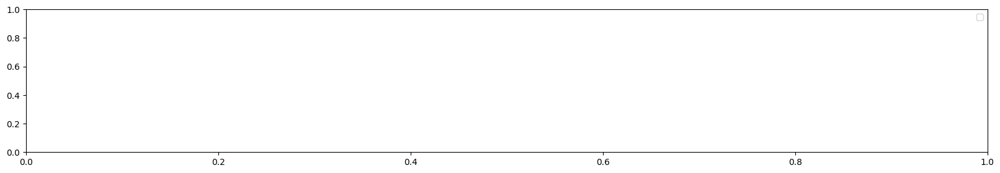

In [ ]:
#* Testing Ridge
tsCv_day = TimeSeriesSplit(
    n_splits=5,
    gap=11, #* add least nb of last cons added
    max_train_size=10000,
    test_size=400,
)

sincosRidgePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("scaler",  StandardScaler()),
    ("ridge",RidgeCV([0.5,1,2,5,10],cv=tsCv_day))
])

scores = {}
collectedInformations ={}
for combinedData,(region,deps) in zip(combinedDatasDepDay,regions_departements.items()):
    informationRatios = []
    print(region+" : ")
    # for lastCons in range(0,30,5):
    combinedDataCons = addLastCons(combinedData, 10)
    # print(combinedDataCons.head())

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedDataCons,"2023-01-01")
    # print(Xtrain.columns)
    # print(Xtrain.columns.tolist())
    # print(Xtrain.columns)
    # print(Xtrain.shape, Xtest.shape)
    sincosRidgePipe.fit(Xtrain,yTrain)
    ridge_step = sincosRidgePipe.named_steps['ridge']


    print(f"\nMeilleur alpha retenu : {ridge_step.alpha_}")
    # scores[region] = sincosRidgePipe.score(Xtest, yTest)

    # print(region, " - score : ", scores[region])

    score = sincosRidgePipe.score(Xtest, yTest)
    print(f"test score : {score:.5f} | train score : {ridge_step.best_score_:.5f}")
    scores[region] = (score,ridge_step.alpha_)
    informationRatios.append(score)
    if lastCons not in collectedInformations:
        collectedInformations[lastCons] = []
    collectedInformations[lastCons].append(score)
        
    # plt.plot(list(range(1,30,5)),informationRatios,label=region)
    
varLastConsDepDayRidge = pd.DataFrame.from_dict(scores,orient="index",columns=["tests score", "alpha"])
plt.legend()
plt.show()

In [21]:
#* Grid search Ridge and poly

tsCv_day = TimeSeriesSplit(
    n_splits=5,
    gap=9, #* add least nb of last cons added
    max_train_size=10000,
    test_size=400,
)

sincosRidgePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("scaler",  StandardScaler()),
    # ("ridge",RidgeCV([0.5,1,2,5,10],cv=ts_cv))
    ("ridge",Ridge())
])
param_grid = {"poly__degree":list(range(1,3)),"ridge__alpha":np.logspace(-1, 4, 20)}
# param_grid = {"ridge__alpha":np.logspace(-1, 4, 20)}

scores = {}
collectedInformations ={}
for combinedData,(region,deps) in zip(combinedDatasDepDay,regions_departements.items()):
    combinedDataCons = addLastCons(combinedData, 8)
    
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedDataCons,"2023-01-01")

    grid_search = GridSearchCV(estimator = sincosRidgePipe, param_grid = param_grid, cv = tsCv_day, n_jobs=-1,error_score='raise')

    grid_search.fit(Xtrain,yTrain)
    collectedInformations[region] = grid_search.cv_results_
    print(f"{region}, {grid_search.best_params_} - {grid_search.best_score_}")


NameError: name 'combinedDatasDepDay' is not defined

In [78]:
#* Ridge and poly
sincosRidgePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("pca",     PcaTransformer(nComp=60)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("scaler",  StandardScaler()),
    # ("ridge",RidgeCV([0.5,1,2,5,10],cv=ts_cv))
    ("ridge",Ridge(alpha=140))
])

# param_grid = {"ridge__alpha":np.logspace(-1, 4, 20)}

scores = {}

for combinedData,(region,deps) in zip(combinedDatasDepHor,regions_departements.items()):
    combinedDataCons = addLastCons(combinedData, 30)
    
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedDataCons,"2023-01-01")

    sincosRidgePipe.fit(Xtrain,yTrain)
    print(f"{region}, {sincosRidgePipe.score(Xtrain,yTrain)} - {sincosRidgePipe.score(Xtest,yTest)}")

Auvergne-Rhône-Alpes, 0.8129093846689751 - 0.5443690457271009
Bourgogne-Franche-Comté, 0.7535784730929302 - 0.5337440350682583
Bretagne, 0.9159716698309844 - 0.8732223770234268
Centre-Val de Loire, 0.8312479389589617 - 0.7275608804235607
Grand Est, 0.7272354229008848 - 0.4192419601388252
Hauts-de-France, 0.9090938101104642 - 0.8308022488957704
Île-de-France, 0.9427188921788507 - 0.827332953693708
Nouvelle-Aquitaine, 0.8034510331343702 - 0.5882503607743693
Normandie, 0.8863337880400826 - 0.8006393309274193
Occitanie, 0.7975522254688787 - 0.5439840386736283
Pays de la Loire, 0.8941579795484773 - 0.8251587474827577
PACA, 0.864241635483511 - 0.7169009846244745


In [77]:
#* Kernel Ridge
sincosRidgePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("pca",     PcaTransformer(nComp=60)),
    # ("poly",    PolynomialFeatures(degree=2)),
    ("scaler",  StandardScaler()),
    # ("ridge",RidgeCV([0.5,1,2,5,10],cv=ts_cv))
    ("kernelRidge",KernelRidge(kernel="poly",alpha=1,degree=2))
])

# param_grid = {"ridge__alpha":np.logspace(-1, 4, 20)}

scores = {}

for combinedData,(region,deps) in zip(combinedDatasDepHor,regions_departements.items()):
    combinedDataCons = addLastCons(combinedData, 30)
    
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combinedDataCons,"2023-01-01")

    sincosRidgePipe.fit(Xtrain,yTrain)
    print(f"{region}, {sincosRidgePipe.score(Xtrain,yTrain)} - {sincosRidgePipe.score(Xtest,yTest)}")

KeyboardInterrupt: 

In [117]:
for region, cvResult in collectedInformations.items():
    df = pd.DataFrame({
        'alpha':      cvResult['param_ridge__alpha'],
        'degree':     cvResult['param_poly__degree'],
        'mean_score': cvResult['mean_test_score']
    })
    
    pivot = df.pivot(index='degree', columns='alpha', values='mean_score')
    pivot.columns = [f"{a:.3f}" for a in pivot.columns]  # arrondi pour lisibilité
    
    print(f"\n=== {region} ===")
    print(pivot.to_string())


=== Auvergne-Rhône-Alpes ===
           0.100     0.183     0.336     0.616     1.129     2.069     3.793     6.952    12.743    23.357    42.813    78.476   143.845   263.665   483.293   885.867  1623.777  2976.351  5455.595  10000.000
degree                                                                                                                                                                                                         
1       0.966540  0.966568  0.966608  0.966656  0.966699  0.966709  0.966631  0.966367  0.965745  0.964482  0.962166  0.958339  0.952684  0.945184  0.935967  0.924532  0.908880  0.885896  0.853784   0.814464
2       0.857932  0.880699  0.900378  0.916743  0.930034  0.940660  0.949081  0.955672  0.960700  0.964370  0.966832  0.968154  0.968306  0.967169  0.964588  0.960423  0.954534  0.946748  0.936896   0.924751

=== Bourgogne-Franche-Comté ===
           0.100     0.183     0.336     0.616     1.129     2.069     3.793     6.952    12.743    23.35

In [ ]:
import seaborn as sns

n_regions = len(collectedInformations)
n_cols = 2
n_rows = math.ceil(n_regions / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

for ax, (region, cvResult) in zip(axes, collectedInformations.items()):
    df = pd.DataFrame({
        'alpha':      cvResult['param_ridge__alpha'],
        'degree':     cvResult['param_poly__degree'],
        'mean_score': cvResult['mean_test_score']
    })
    
    pivot = df.pivot(index='alpha', columns='degree', values='mean_score')
    # pivot = df.pivot(index='degree', columns='alpha', values='mean_score')
    pivot.columns = [f"{a:.3f}" for a in pivot.rows]  # ← 3 chiffres après la virgule
    
    sns.heatmap(pivot, ax=ax, annot=True, fmt=".5f", cmap="RdYlGn")
    ax.set_title(region, fontsize=13)
    ax.set_xlabel("degree")
    ax.set_ylabel("alpha")

# Masquer les axes vides si nombre impair de régions
for ax in axes[n_regions:]:
    ax.set_visible(False)

plt.tight_layout(pad=3.0)
plt.show()

Auvergne-Rhône-Alpes, {'kernelRidge__alpha': np.float64(0.1), 'kernelRidge__coef0': 1, 'kernelRidge__degree': 2} - 0.9784101184642939


KeyboardInterrupt: 

In [ ]:
bestParamsDepDay = {
    "Auvergne-Rhône-Alpes": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    "Bourgogne-Franche-Comté": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    "Bretagne": [
        22, 29, 35, 56
    ],
    "Centre-Val de Loire": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    # "Corse": [ #* Not in Rte Data
    #     20
    # ],
    "Grand Est": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    "Hauts-de-France": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    "Île-de-France": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    "Nouvelle-Aquitaine": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    "Normandie": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    "Occitanie": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    "Pays de la Loire": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
    "PACA": {
        "poly__degree":2,
        "ridge__alpha":43,
        "lastCons__nb":8,
    },
}

In [ ]:
#* Trying PCA to reduce number of features

sincosPcaLinRegPipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("pca", PcaTransformer(nComp=22)),
    ("poly",    PolynomialFeatures(degree=2)),
    ("linReg",  LinearRegression())
])

preTransformPipe = sincosPcaLinRegPipe[:2]

collectedInformations = {}
for combinedData,(region,deps) in zip(combinedDatasDepDay,regions_departements.items()):
    
    combineLastDay = addLastCons(combinedData,27)
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-12-31")
    # Xtrain.drop(['dateTime'],axis=1,inplace=True)
    # pca.fit(Xtrain)
    XtrainTransformed = preTransformPipe.fit_transform(Xtrain, yTrain)
    print(region,XtrainTransformed.shape[1])
    informationRatios = []
    for d in range(30,70):
        pca = PCA(d)

        pca.fit(XtrainTransformed)
        totalVar = sum(pca.explained_variance_ratio_)
        # print(XPca )
        
        informationRatios.append(totalVar)
        if d not in collectedInformations:
            collectedInformations[d] = []
        collectedInformations[d].append(totalVar)

    plt.plot(list(range(30,70)),informationRatios,label=region)
varDf = pd.DataFrame.from_dict(collectedInformations,orient="index",columns=list(regions_departements.keys()))
plt.legend()
plt.show()

**TESTING TREES**

#### Region by Day

In [36]:

tsCv_day = TimeSeriesSplit(
    n_splits=5,
    gap=9, #* add least nb of last cons added
    max_train_size=10000,
    test_size=400,
)

sincosTreePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=True, use_weekDay=True, use_yearDay=True)),
    ("tree",    DecisionTreeRegressor(max_depth=8)),
])
param_grid = {"tree__max_depth":list(range(1,20))}
for combinedRegDay, (region,deps) in zip(combinedDatasRegDay,regions_departements.items()):
    combineLastDay = addLastCons(combinedRegDay,8)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2022-01-01")
    grid_search = GridSearchCV(estimator = sincosTreePipe, param_grid = param_grid, cv = tsCv_day, n_jobs=-1,error_score='raise')

    grid_search.fit(Xtrain,yTrain)
    collectedInformations[region] = grid_search.cv_results_
    print(f"{region}, {grid_search.best_params_} - {grid_search.best_score_}")

    # print(f'{region} | test : {sincosTreePipe.score(Xtest,yTest):.5f} train : {sincosTreePipe.score(Xtrain,yTrain):.5f}')
    # plt.plot(combineLastDay["Date"],combineLastDay["Consommation"],label="Truth")
    # plt.plot(combineLastDay["Date"],sincosTreePipe.predict(combineLastDay.drop(['Consommation'],axis=1)),label="Prediction")
    # plt.legend()
    # plt.show()
    

Auvergne-Rhône-Alpes, {'tree__max_depth': 8} - 0.9463600011285882
Bourgogne-Franche-Comté, {'tree__max_depth': 7} - 0.9274924167957994
Bretagne, {'tree__max_depth': 7} - 0.9437261967226144
Centre-Val de Loire, {'tree__max_depth': 7} - 0.9430936326891706
Grand Est, {'tree__max_depth': 7} - 0.9178578300715072
Hauts-de-France, {'tree__max_depth': 7} - 0.9380802961373573
Île-de-France, {'tree__max_depth': 7} - 0.9537642938491804
Nouvelle-Aquitaine, {'tree__max_depth': 7} - 0.9503668372787015
Normandie, {'tree__max_depth': 8} - 0.9504466490352383
Occitanie, {'tree__max_depth': 8} - 0.9560127301942783
Pays de la Loire, {'tree__max_depth': 9} - 0.9356489621617152
PACA, {'tree__max_depth': 9} - 0.9585195099117554


In [51]:
records = {}
for region, cvResult in collectedInformations.items():
    records[region] = dict(zip(
        cvResult['param_tree__max_depth'],
        cvResult['mean_test_score']
    ))

df = pd.DataFrame(records)
df.index.name = "max_depth"

# Colonne moyenne
df["Mean"] = df.mean(axis=1)
df.style.highlight_max(color = 'green', axis = 0)

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Île-de-France,Nouvelle-Aquitaine,Normandie,Occitanie,Pays de la Loire,PACA,Mean
max_depth,,,,,,,,,,,,,
1,0.656430,0.610973,0.664429,0.691523,0.598867,0.650783,0.674699,0.687568,0.683396,0.681671,0.632590,0.696790,0.660810
2,0.811348,0.791523,0.799492,0.821175,0.783679,0.822665,0.831714,0.824337,0.824156,0.839318,0.780557,0.855952,0.815493
3,0.860725,0.841173,0.867312,0.879619,0.846841,0.872414,0.893137,0.889328,0.886736,0.893853,0.851254,0.909380,0.874314
4,0.897028,0.875244,0.908287,0.907337,0.879370,0.903933,0.922682,0.920677,0.916499,0.925100,0.896067,0.939323,0.907629
5,0.925541,0.906737,0.929643,0.932300,0.902286,0.927182,0.939119,0.940181,0.934779,0.943699,0.920789,0.952110,0.929530
6,0.939789,0.923397,0.939774,0.939152,0.914054,0.934280,0.947982,0.948626,0.943470,0.952374,0.932878,0.956638,0.939368
7,0.944995,0.927492,0.943726,0.943094,0.917858,0.938080,0.953764,0.950367,0.948159,0.955393,0.935431,0.957669,0.943002
8,0.946360,0.920455,0.942607,0.941503,0.917435,0.937214,0.953319,0.947870,0.950447,0.956013,0.935645,0.958245,0.942260
9,0.941352,0.917674,0.940781,0.939585,0.916456,0.937981,0.951294,0.946031,0.948926,0.951893,0.935649,0.958520,0.940512


In [ ]:
sincosAdaTreePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("AdaBoostTree", AdaBoostRegressor(DecisionTreeRegressor(max_depth=8), n_estimators=100,learning_rate=1)),
])

for combinedRegDay, (region,deps) in zip(combinedDatasRegDay,regions_departements.items()):
    combineLastDay = addLastCons(combinedRegDay,8)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-01-01")
    sincosAdaTreePipe.fit(Xtrain,yTrain.to_numpy().ravel())

    print(f"{region}, {sincosAdaTreePipe.score(Xtest,yTest.to_numpy().ravel())} - {sincosAdaTreePipe.score(Xtrain,yTrain.to_numpy().ravel())}")

Auvergne-Rhône-Alpes, 0.9618419976746341 - 0.9947397850844983
Bourgogne-Franche-Comté, 0.9635942154979757 - 0.9932169759132818
Bretagne, 0.9737458387770629 - 0.9948498009347779
Centre-Val de Loire, 0.9575660862348703 - 0.9936513530952278
Grand Est, 0.9462180341235702 - 0.9938344905676945
Hauts-de-France, 0.9430496830029685 - 0.9941173734280395
Île-de-France, 0.9708096394805218 - 0.9960683271421756
Nouvelle-Aquitaine, 0.9716170192858914 - 0.9946072620041855
Normandie, 0.966375542898279 - 0.9952316432464228
Occitanie, 0.9767245254881931 - 0.994984713839335
Pays de la Loire, 0.9574517828621945 - 0.9943545653268877
PACA, 0.9742096261205664 - 0.995659418338793


In [ ]:
sincosAdaTreePipe = Pipeline([
    ("days",    DaysTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("sincos",  SinCosTransformer(use_hour=False, use_weekDay=True, use_yearDay=True)),
    ("AdaBoostTree", AdaBoostRegressor(DecisionTreeRegressor(max_depth=8), n_estimators=100,learning_rate=1)),
])

param_grid = {
    
}
for combinedRegDay, (region,deps) in zip(combinedDatasRegDay,regions_departements.items()):
    combineLastDay = addLastCons(combinedRegDay,8)

    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-01-01")
    grid_search = GridSearchCV(sincosAdaTreePipe,param_grid=param_grid,n_jobs=-1,cv = tsCv_day)
    sincosAdaTreePipe.fit(Xtrain,yTrain.to_numpy().ravel())

    print(f"{region}, {sincosAdaTreePipe.score(Xtest,yTest.to_numpy().ravel())} - {sincosAdaTreePipe.score(Xtrain,yTrain.to_numpy().ravel())}")

In [95]:
for combinedData, region in zip(combinedDatasDepHor,regions_departements.keys()):
    if region != "Île-de-France":
        continue
    print(region)
    print(combinedData.shape)
    print(combinedData["dateTime"].min())
    combineLastDay = addLastCons(combinedData,24)
    print(combineLastDay.shape)

    Xtrain,yTrain,_,_ = getTestTrain(combineLastDay,"2023-01-01")
    print(Xtrain.shape)

Île-de-France
(17774, 122)
2020-12-31 06:00:00
(17750, 146)
(8990, 145)


In [105]:
combinedDatasDepHor = loadDepHourData(verbose=True)

1 (43848, 15)
3 (43848, 15)
7 (43848, 15)
15 (43848, 15)
26 (43848, 15)
38 (43848, 15)
42 (43848, 15)
43 (43848, 15)
63 (43848, 15)
69 (43848, 15)
73 (43848, 15)
74 (43848, 15)
Auvergne-Rhône-Alpes (43848, 182)
21 (43848, 15)
25 (43848, 15)
39 (43848, 15)
58 (43848, 15)
70 (43848, 15)
71 (43848, 15)
89 (43848, 15)
90 (43848, 15)
Bourgogne-Franche-Comté (43848, 122)
22 (43848, 15)
29 (43848, 15)
35 (43848, 15)
56 (43848, 15)
Bretagne (43848, 62)
18 (43848, 15)
28 (43848, 15)
36 (43848, 15)
37 (43848, 15)
41 (43848, 15)
45 (43848, 15)
Centre-Val de Loire (43848, 92)
8 (43848, 15)
10 (43848, 15)
51 (43848, 15)
52 (43848, 15)
54 (43848, 15)
55 (43848, 15)
57 (43848, 15)
67 (43848, 15)
68 (43848, 15)
88 (43848, 15)
Grand Est (43848, 152)
2 (43848, 15)
59 (43848, 15)
60 (43848, 15)
62 (43848, 15)
80 (43848, 15)
Hauts-de-France (43848, 77)
75 (43848, 15)
77 (43848, 15)
78 (43848, 15)
91 (43848, 15)
92 (43753, 15)
93 (26558, 15)
94 (43848, 15)
95 (43848, 15)
Île-de-France (43848, 122)
16 (4384

**Calcul des prédiction RTE**

In [42]:
rteFileName = "eCO2mix_RTE_Annuel-Definitif_"
yearsDf = []
#* Convert Excel to csv
for year in range(2013,2025):
    rteData = pd.read_csv(os.path.join("rawData","rte",f"{rteFileName}{year}.xls"),sep="\t",encoding="latin-1",usecols=["Nature","Date","Heures","Consommation","Prévision J-1"])
    rteData.dropna(inplace=True)
    yearsDf.append(rteData)
    print(f"year : {year}, len : {rteData.shape}")
rteData = pd.concat(yearsDf)
rteData.to_csv(os.path.join("cleanedData","rte",f"rteEstimation.csv"),index=False)

year : 2013, len : (17520, 5)
year : 2014, len : (17520, 5)
year : 2015, len : (17520, 5)
year : 2016, len : (17568, 5)
year : 2017, len : (17520, 5)
year : 2018, len : (17520, 5)
year : 2019, len : (17520, 5)
year : 2020, len : (17568, 5)
year : 2021, len : (17520, 5)
year : 2022, len : (17520, 5)
year : 2023, len : (17520, 5)
year : 2024, len : (17568, 5)


In [43]:
from sklearn.metrics import r2_score

In [ ]:
rteEstimation = pd.read_csv(os.path.join("cleanedData","rte","rteEstimation.csv"))

x_energy = pd.to_datetime(rteEstimation["Date"].astype(str) + " " + rteEstimation["Heures"])
            
rteByHour = rteEstimation.set_index(x_energy).resample("1h").sum(numeric_only=True).reset_index(names=["dateTime"]) 

rteByDay = rteEstimation.groupby("Date").sum().reset_index()


for year in range(2013,2025):
    rteHourYear = rteByHour[(rteByHour["dateTime"] >= f"{year}-01-01") & (rteByHour["dateTime"] < f"{year+1}-01-01") ]
    rteDayyear = rteByDay[(rteByDay["Date"] >= f"{year}-01-01") & (rteByDay["Date"] < f"{year+1}-01-01") ]
    print(year," Score on J-1 by Hour",r2_score(rteHourYear["Consommation"],rteHourYear["Prévision J-1"]))
    print(year," Score on J-1 by Day",r2_score(rteDayyear["Consommation"],rteDayyear["Prévision J-1"]))
    # print(rteHourYear)

Score on J by Hour 0.9795237338309817
Score on J-1 by Hour 0.9895522734903659
Score on J by Day 0.9779091061527849
Score on J-1 by Day 0.991472379309217
2013  Score on J-1 by Hour 0.993000471174667
2013  Score on J-1 by Day 0.9946926075960633
2014  Score on J-1 by Hour 0.9924107267069642
2014  Score on J-1 by Day 0.993537633654152
2015  Score on J-1 by Hour 0.9928605481688069
2015  Score on J-1 by Day 0.9948561247542972
2016  Score on J-1 by Hour 0.9924197901070604
2016  Score on J-1 by Day 0.9941069551376103
2017  Score on J-1 by Hour 0.9930847018930853
2017  Score on J-1 by Day 0.9947202960295918
2018  Score on J-1 by Hour 0.992230101334636
2018  Score on J-1 by Day 0.9942053076048525
2019  Score on J-1 by Hour 0.9924842743949177
2019  Score on J-1 by Day 0.9946457701760112
2020  Score on J-1 by Hour 0.9901724162490099
2020  Score on J-1 by Day 0.9928589569946562
2021  Score on J-1 by Hour 0.9908044978094169
2021  Score on J-1 by Day 0.9932264961230726
2022  Score on J-1 by Hour 0.98

In [57]:
def plotScoresByYear(rteByHour: pd.DataFrame,
                     rteByDay: pd.DataFrame,
                     startYear: int = 2013,
                     endYear: int = 2025,
                     figsize: tuple = (14, 6),
                     savePath: str = None) -> None:
    """
    Plot prediction scores by year for both hourly and daily data.
    
    Args:
        rteByHour: DataFrame with hourly data containing 'dateTime', 'Consommation', 'Prévision J-1'
        rteByDay: DataFrame with daily data containing 'Date', 'Consommation', 'Prévision J-1'
        startYear: Start year (default: 2013)
        endYear: End year (default: 2025)
        figsize: Figure size as (width, height) tuple (default: (14, 6))
        savePath: Path to save the figure (optional)
        
    Returns:
        None - displays the plot
    """
    
    years = []
    scoresHourly = []
    scoresDaily = []
    
    # Collect scores for each year
    for year in range(startYear, endYear):
        rteHourYear = rteByHour[(rteByHour["dateTime"] >= f"{year}-01-01") & 
                                (rteByHour["dateTime"] < f"{year+1}-01-01")]
        rteDayYear = rteByDay[(rteByDay["Date"] >= f"{year}-01-01") & 
                              (rteByDay["Date"] < f"{year+1}-01-01")]
        
        if len(rteHourYear) > 0 and len(rteDayYear) > 0:
            scoreHour = r2_score(rteHourYear["Consommation"], rteHourYear["Prévision J-1"])
            scoreDay = r2_score(rteDayYear["Consommation"], rteDayYear["Prévision J-1"])
            
            years.append(year)
            scoresHourly.append(scoreHour)
            scoresDaily.append(scoreDay)
    
    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    
    x = np.arange(len(years))
    width = 0.35
    
    ax.bar(x - width / 2, scoresDaily, width, label="Daily", color="steelblue", alpha=0.85)
    ax.bar(x + width / 2, scoresHourly, width, label="Hourly", color="coral", alpha=0.85)
    
    ax.set_xlabel("Year", fontsize=12)
    ax.set_ylabel("R² Score", fontsize=12)
    ax.set_title("Prediction Scores by Year (T-1 Forecast)", fontsize=13, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(years, fontsize=11)
    ax.legend(loc="lower right", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(0.9, 1)
    
    plt.tight_layout()
    
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
    
    plt.show()

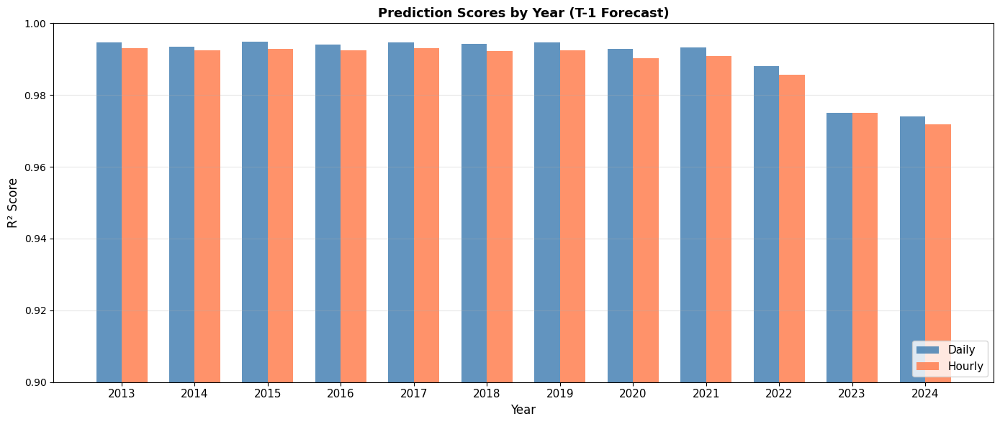

In [58]:
plotScoresByYear(rteByHour,rteByDay,savePath="graphics/bestscores/rte.pdf")

Map saved to graphics/stationsMap.pdf


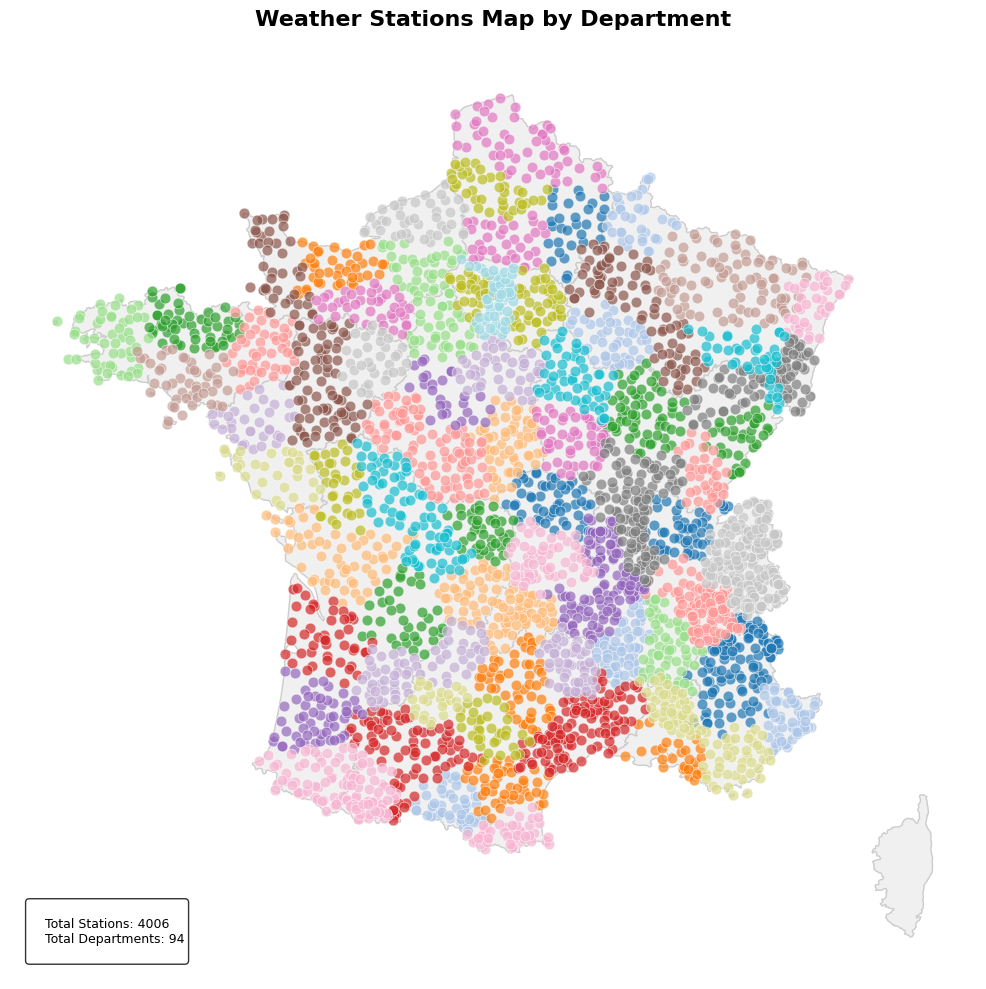

In [169]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


def createStationsMap(stationsFile: str = "stationsCoordDay.csv",
                      title: str = "Weather Stations Map - France",
                      figsize: tuple = (14, 10),
                      savePath: str = None) -> None:
    """
    Create a map of France with weather station locations plotted.
    
    Args:
        stationsFile: Path to CSV file with station coordinates (NUM_POSTE, LAT, LON, dep)
        title: Title of the map (default: "Weather Stations Map - France")
        figsize: Figure size as (width, height) tuple (default: (14, 10))
        savePath: Path to save the figure (optional)
        
    Returns:
        None - displays the map
    """
    
    # Load stations data
    try:
        stations_df = pd.read_csv(stationsFile)
    except FileNotFoundError:
        print(f"Error: File '{stationsFile}' not found")
        return
    
    # Load France regions GeoJSON
    try:
        gdf_regions = gpd.read_file("regions-version-simplifiee.geojson.txt")
    except FileNotFoundError:
        print("Error: regions-version-simplifiee.geojson.txt not found")
        return
    
    # --- Rename regions for consistency ---
    rename_map = {
        "Provence-Alpes-Côte d'Azur": "PACA",
    }
    gdf_regions["nom_model"] = gdf_regions["nom"].replace(rename_map)
    
    # --- Create figure ---
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=16, fontweight="bold", pad=20)
    
    # --- Plot regions (light gray background) ---
    gdf_regions.plot(ax=ax, color="#f0f0f0", edgecolor="#cccccc", linewidth=1)
    
    # --- Plot stations as scatter points ---
    scatter = ax.scatter(
        stations_df["LON"],
        stations_df["LAT"],
        c="#2c3e50",           # Dark blue-gray color
        s=50,                  # Point size
        alpha=0.7,             # Transparency
        edgecolors="#34495e",  # Darker edge
        linewidth=0.5,
        label=f"Stations ({len(stations_df)})",
        zorder=5               # Ensure points are on top
    )
    
    # --- Add grid ---
    ax.grid(True, alpha=0.2, linestyle="--", linewidth=0.5)
    
    # --- Legend ---
    legend_elements = [
        mpatches.Patch(facecolor="#f0f0f0", edgecolor="#cccccc", label="Regions"),
        scatter
    ]
    ax.legend(handles=legend_elements, loc="upper left", fontsize=11, framealpha=0.95)
    
    # --- Statistics ---
    stats_text = f"""
    Total Stations: {len(stations_df)}
    Latitude Range: {stations_df['LAT'].min():.2f}° - {stations_df['LAT'].max():.2f}°
    Longitude Range: {stations_df['LON'].min():.2f}° - {stations_df['LON'].max():.2f}°
    """
    ax.text(0.02, 0.02, stats_text, transform=ax.transAxes,
            fontsize=9, verticalalignment="bottom",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    
    plt.tight_layout()
    
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
        print(f"Map saved to {savePath}")
    
    plt.show()


def createStationsMapByDepartment(stationsFile: str = "stationsCoordDay.csv",
                                  title: str = "Weather Stations Map by Department",
                                  figsize: tuple = (14, 10),
                                  savePath: str = None) -> None:
    """
    Create a map of France with weather stations colored by department.
    
    Args:
        stationsFile: Path to CSV file with station coordinates (NUM_POSTE, LAT, LON, dep)
        title: Title of the map (default: "Weather Stations Map by Department")
        figsize: Figure size as (width, height) tuple (default: (14, 10))
        savePath: Path to save the figure (optional)
        
    Returns:
        None - displays the map
    """
    
    import matplotlib.cm as cm
    import numpy as np
    
    # Load stations data
    try:
        stations_df = pd.read_csv(stationsFile)
    except FileNotFoundError:
        print(f"Error: File '{stationsFile}' not found")
        return
    
    # Load France regions GeoJSON
    try:
        gdf_regions = gpd.read_file("regions-version-simplifiee.geojson.txt")
    except FileNotFoundError:
        print("Error: regions-version-simplifiee.geojson.txt not found")
        return
    
    # --- Create figure ---
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=16, fontweight="bold", pad=20)
    
    # --- Plot regions (light background) ---
    gdf_regions.plot(ax=ax, color="#f0f0f0", edgecolor="#cccccc", linewidth=1)
    
    # --- Color map for departments ---
    departments = stations_df["dep"].unique()
    colors = cm.tab20(np.linspace(0, 1, len(departments)))
    dep_colors = {dep: colors[i] for i, dep in enumerate(sorted(departments))}
    
    # --- Plot stations colored by department ---
    for dep in sorted(departments):
        dep_stations = stations_df[stations_df["dep"] == dep]
        ax.scatter(
            dep_stations["LON"],
            dep_stations["LAT"],
            c=[dep_colors[dep]],
            s=60,
            alpha=0.7,
            edgecolors="white",
            linewidth=0.5,
            label=f"Dep {int(dep)}",
            zorder=5
        )
    
    # --- Add grid ---
    ax.grid(True, alpha=0.2, linestyle="--", linewidth=0.5)
    
    # --- Legend ---
    # ax.legend(loc="upper left", fontsize=8, ncol=2, framealpha=0.95, markerscale=0.8)
    
    # --- Statistics ---
    stats_text = f"""
    Total Stations: {len(stations_df)}
    Total Departments: {len(departments)}
    """
    ax.text(0.02, 0.02, stats_text, transform=ax.transAxes,
            fontsize=9, verticalalignment="bottom",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    
    plt.tight_layout()
    
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")
        print(f"Map saved to {savePath}")
    
    plt.show()


def getStationsStats(stationsFile: str = "stationsCoordDay.csv") -> pd.DataFrame:
    """
    Get statistics about weather stations by department.
    
    Args:
        stationsFile: Path to CSV file with station coordinates
        
    Returns:
        pd.DataFrame: Statistics by department (count, lat/lon ranges)
    """
    
    try:
        stations_df = pd.read_csv(stationsFile)
    except FileNotFoundError:
        print(f"Error: File '{stationsFile}' not found")
        return pd.DataFrame()
    
    stats = stations_df.groupby("dep").agg({
        "NUM_POSTE": "count",
        "LAT": ["min", "max", "mean"],
        "LON": ["min", "max", "mean"]
    }).round(4)
    
    stats.columns = ["Count", "LAT_min", "LAT_max", "LAT_mean", "LON_min", "LON_max", "LON_mean"]
    
    return stats.sort_index()


# ===== Usage Examples =====

    
# Simple map with all stations
# createStationsMap("stationsCoordByDay.csv")

# Map colored by department
createStationsMapByDepartment("stationsCoordByDay.csv",savePath="graphics/stationsMap.pdf")

# Get statistics
# stats = getStationsStats("stationsCoordByDay.csv")
# print(stats)

In [ ]:
Xtrain,yTrain,_,_ = getTestTrain(combinedDatasRegDay[0],"2024-01-01")
tscv = TimeSeriesSplit()
print(tscv)

print(Xtrain.loc[1,"Date"])
for i, (train_index, test_index) in enumerate(tscv.split(Xtrain)):
    print(f"Fold {i}:")
    print(f"  Train: index={Xtrain.loc[train_index[0],"Date"]} {Xtrain.loc[train_index[-1],"Date"]}")
    print(f"  Test:  index={Xtrain.loc[test_index[0],"Date"]} {Xtrain.loc[test_index[-1],"Date"]}")

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)
2013-01-02 00:00:00
Fold 0:


KeyError: (np.int64(0), 'Date')